In [1]:
import gc
import torch
import numpy as np
import os
import sys

def clear_all_memory():
    # Clear CUDA memory (VRAM)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    
    # Collect garbage (clean up unused memory from the Python heap)
    gc.collect()

    # Delete variables to free RAM
    for name in dir():
        if not name.startswith('_'):
            del globals()[name]

    # Reset random seeds if necessary
    np.random.seed(42)
    torch.manual_seed(42)
    torch.cuda.manual_seed(42)
    torch.backends.cudnn.deterministic = True

    # Optional: Reset environment variables or modules if needed (e.g., clearing caches)
    os.environ["CUDA_VISIBLE_DEVICES"] = ""

    print("Memory cleared and environment reset!")

Vanilla Restnet32-----------------------------------------------------------------------------------------------

In [2]:
import import_ipynb
from starter_restnet import *
import sys

Classes: 
['0- Ripe 100- Unripe', '100- Ripe 0- Unripe', '30- Ripe 70- Unripe', '50- Ripe 50- Unripe', '70- Ripe 30- Unripe']
Number of splits: 10


In [3]:
class ResidualBlock(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None):
            super(ResidualBlock, self).__init__()
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels))
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.avgpool = nn.AvgPool2d(7, stride=1)
            self.fc = nn.Linear(512, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.avgpool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [4]:
all_folds_val_loss = []
all_folds_val_acc = []
all_folds_f1 = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 3.68 GMac
Model Params: 21.3 M
Early stopping at epoch 108 due to no improvement in validation loss.


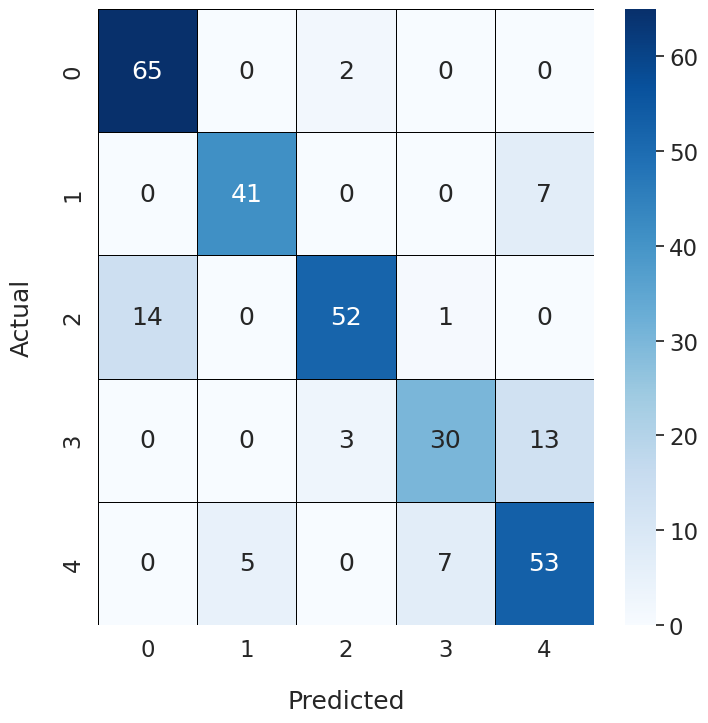

Epoch Training Time: 719.20 seconds
Test set: Average loss: 0.4690, Accuracy: 256/323 (79.26%), F1 Score: 0.7916

Fold 2
-------
Early stopping at epoch 109 due to no improvement in validation loss.


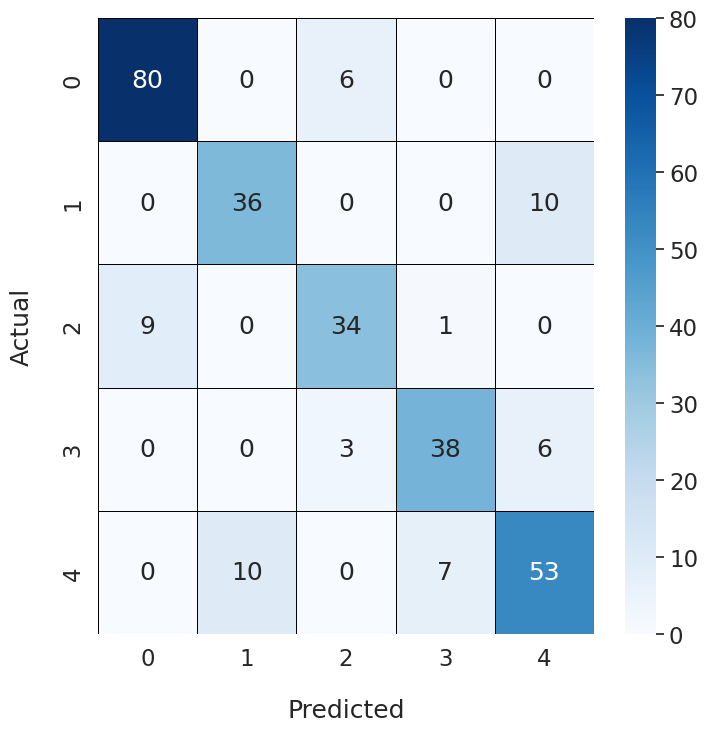

Epoch Training Time: 776.90 seconds
Test set: Average loss: 0.4348, Accuracy: 271/323 (83.90%), F1 Score: 0.8364

Fold 3
-------
Early stopping at epoch 112 due to no improvement in validation loss.


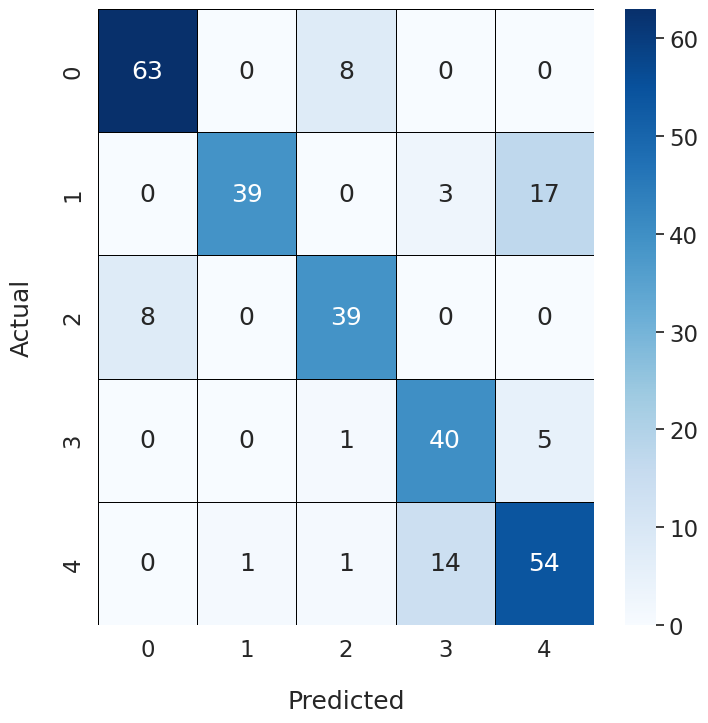

Epoch Training Time: 873.72 seconds
Test set: Average loss: 0.3901, Accuracy: 270/323 (83.59%), F1 Score: 0.8348

Fold 4
-------
Early stopping at epoch 116 due to no improvement in validation loss.


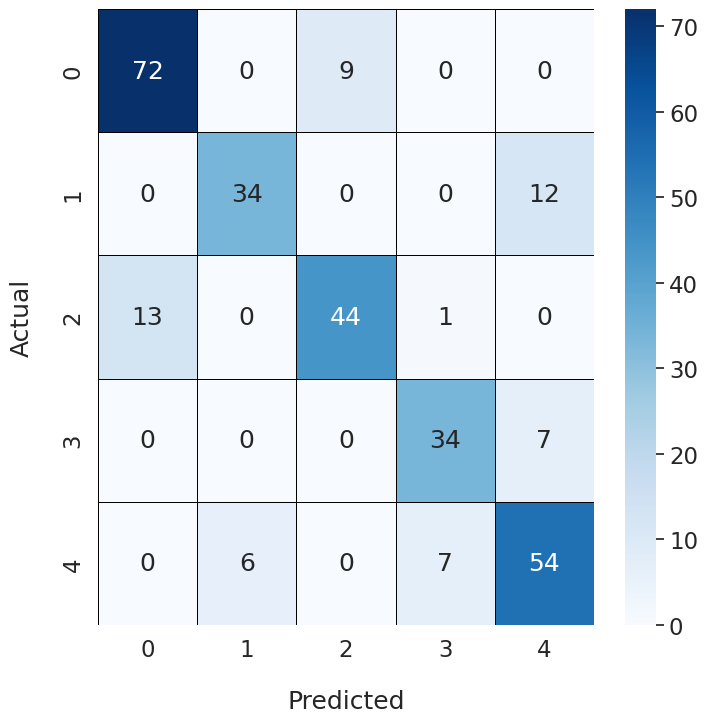

Epoch Training Time: 851.51 seconds
Test set: Average loss: 0.4773, Accuracy: 262/323 (81.11%), F1 Score: 0.8077

Fold 5
-------
Early stopping at epoch 104 due to no improvement in validation loss.


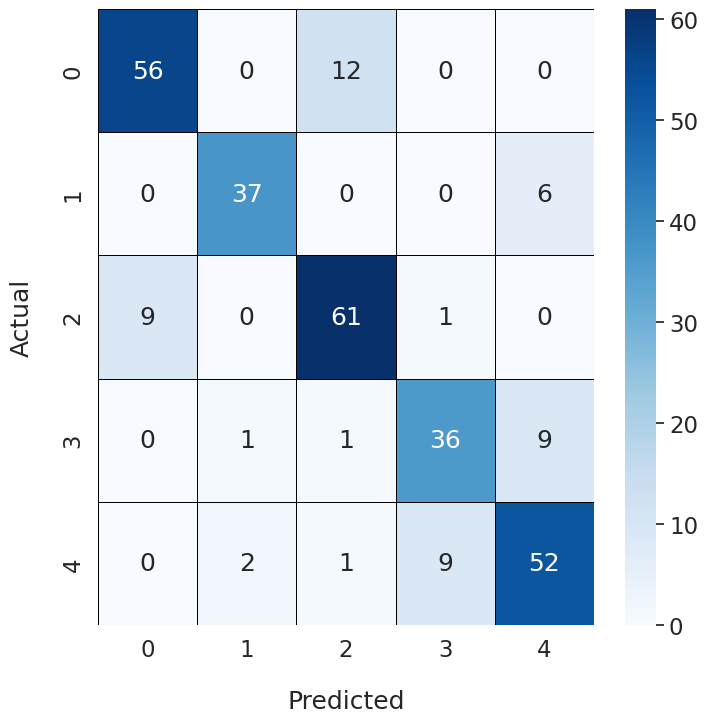

Epoch Training Time: 729.07 seconds
Test set: Average loss: 0.5381, Accuracy: 247/323 (76.47%), F1 Score: 0.7603

Fold 6
-------
Early stopping at epoch 112 due to no improvement in validation loss.


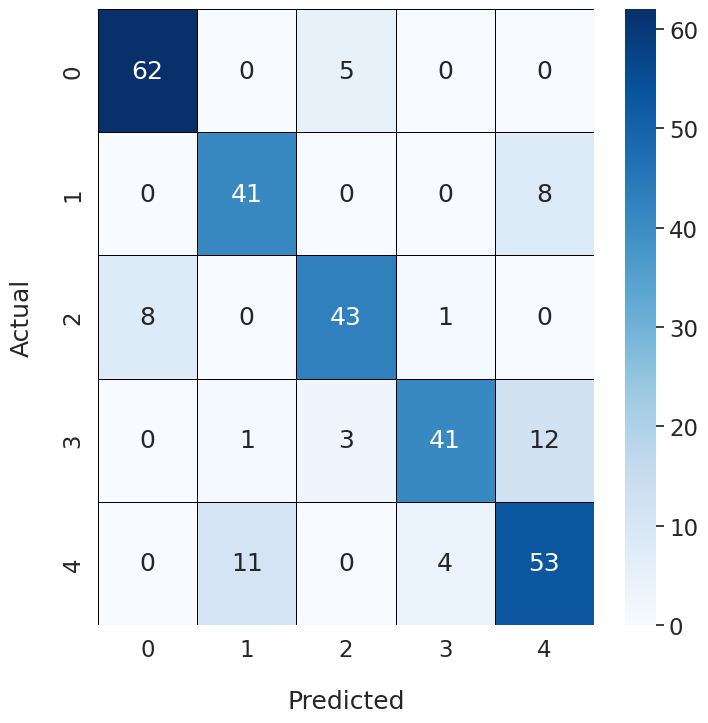

Epoch Training Time: 825.63 seconds
Test set: Average loss: 0.4117, Accuracy: 273/323 (84.52%), F1 Score: 0.8439

Fold 7
-------
Early stopping at epoch 113 due to no improvement in validation loss.


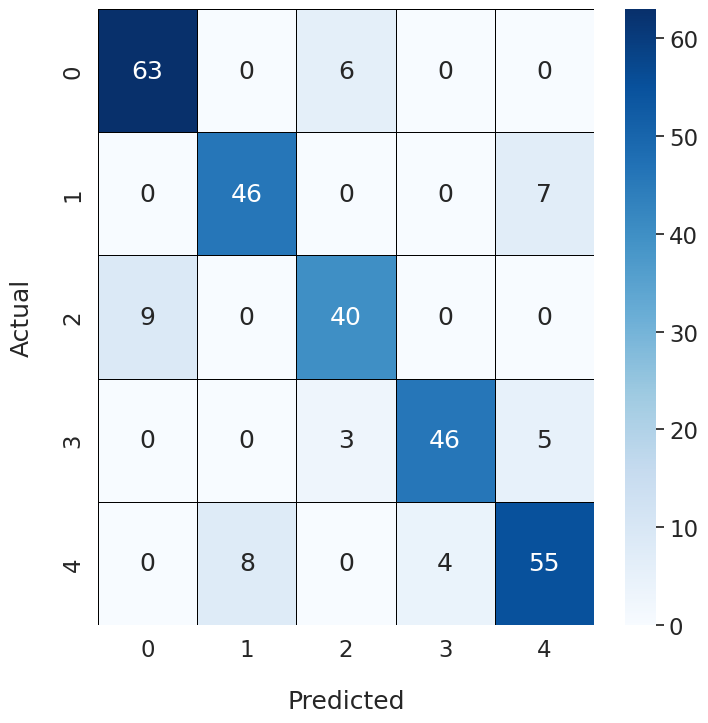

Epoch Training Time: 860.32 seconds
Test set: Average loss: 0.4405, Accuracy: 262/323 (81.11%), F1 Score: 0.8117

Fold 8
-------
Early stopping at epoch 106 due to no improvement in validation loss.


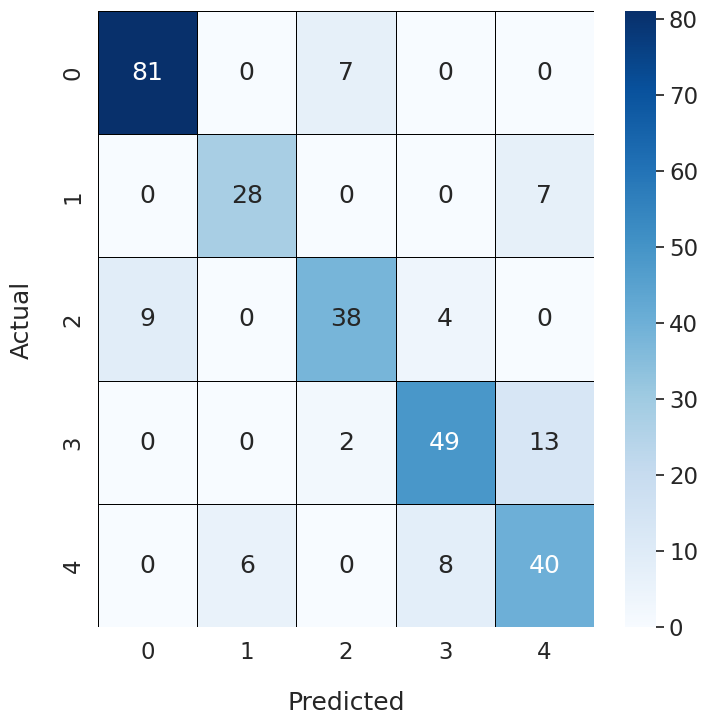

Epoch Training Time: 713.69 seconds
Test set: Average loss: 0.4862, Accuracy: 258/323 (79.88%), F1 Score: 0.7936

Fold 9
-------
Early stopping at epoch 114 due to no improvement in validation loss.


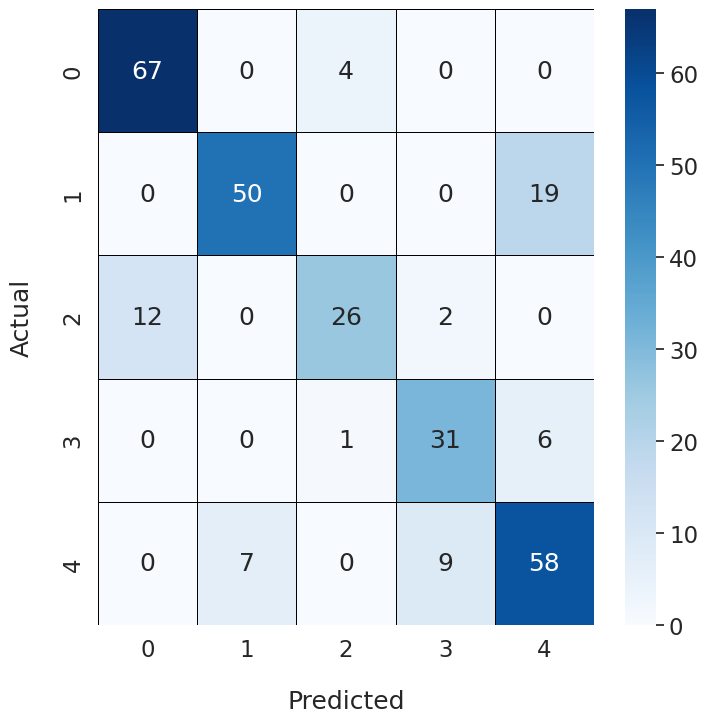

Epoch Training Time: 881.55 seconds
Test set: Average loss: 0.4761, Accuracy: 268/323 (82.97%), F1 Score: 0.8245

Fold 10
-------
Early stopping at epoch 120 due to no improvement in validation loss.


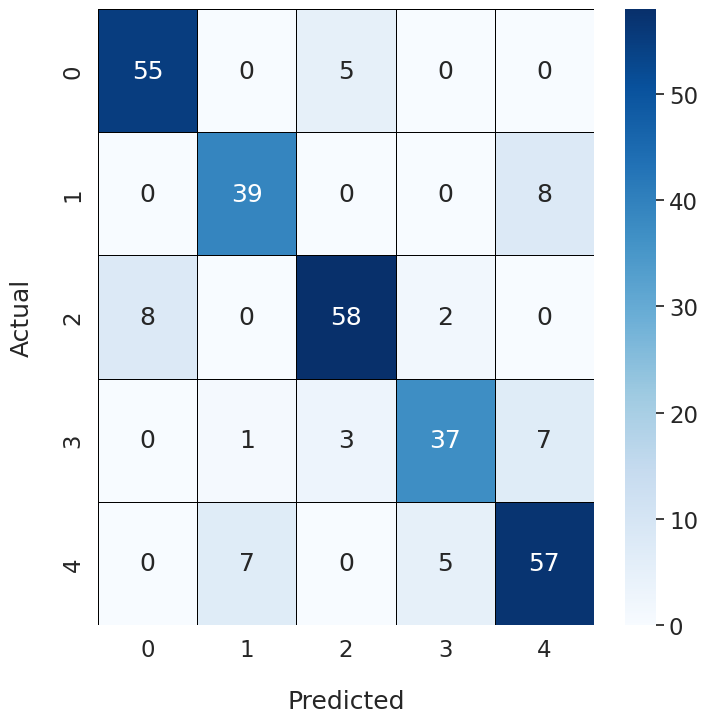

Epoch Training Time: 951.49 seconds
Test set: Average loss: 0.4328, Accuracy: 267/323 (82.66%), F1 Score: 0.8263



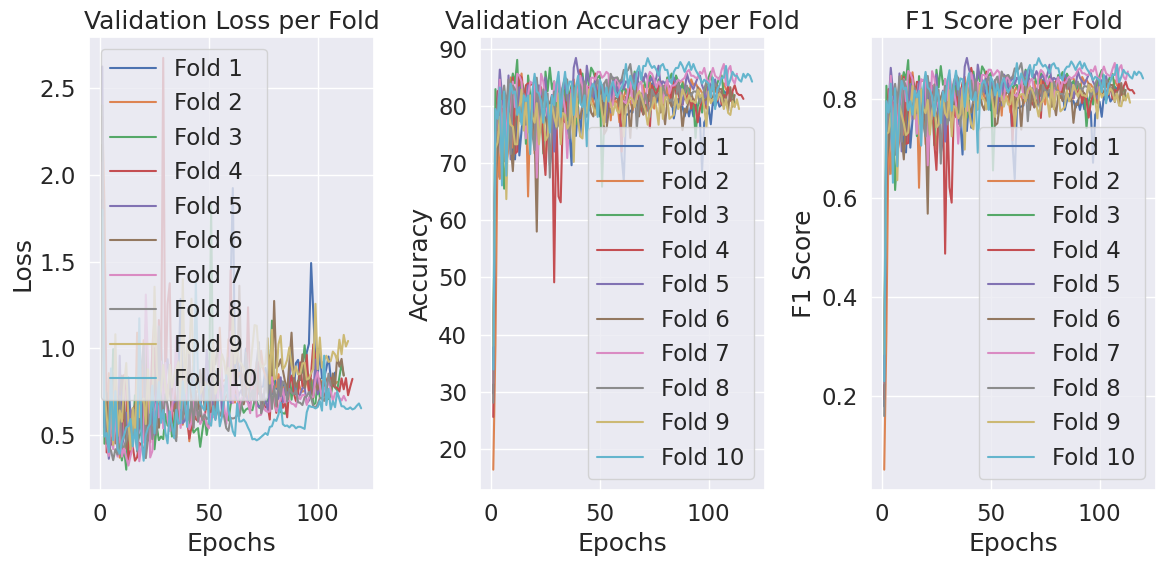

Maximum Fold Accuracy = 84.52012383900929
Maximum Fold F1 Score = 0.8439281096877692
Average Fold Accuracy = 81.54798761609906
Average Fold F1 Score = 0.8130915938634455


In [5]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Restnet/noSE"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/noSE/best_noSE.pth"
os.makedirs("./model_Restnet/noSE", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_noSE.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []

   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet(ResidualBlock, [3, 4, 6, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 224, 224), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=lr0, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")
    
    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"noSE_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])

    all_folds_val_loss.append(epoch_val_loss.copy())
    all_folds_val_acc.append(epoch_val_acc.copy())
    all_folds_f1.append(epochs_f1_score.copy())

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet(ResidualBlock, [3, 4, 6, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout_

In [6]:
clear_all_memory()

Memory cleared and environment reset!


SE(avg original) + Restnet34-------------------------------------------------------------------------------------------

In [7]:
import import_ipynb
from starter_restnet import *

In [8]:
class SE_Block(nn.Module):
    "credits: https://github.com/moskomule/senet.pytorch/blob/master/senet/se_module.py#L4"
    def __init__(self, c, r=8):
        super().__init__()
        self.squeeze = nn.AdaptiveAvgPool2d(1)
        self.excitation = nn.Sequential(
            nn.Linear(c, c // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(c // r, c, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        bs, c, _, _ = x.shape
        y = self.squeeze(x).view(bs, c)
        y = self.excitation(y).view(bs, c, 1, 1)
        return x * y.expand_as(x)

In [9]:
class ResidualBlock_SEavg(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=8):
            super(ResidualBlock_SEavg, self).__init__()
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels))
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels
            # add SE block
            self.se = SE_Block(out_channels, r)

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)

            out = self.se(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_SEavg(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_SEavg, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.avgpool = nn.AvgPool2d(7, stride=1)
            self.fc = nn.Linear(512, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.avgpool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [10]:
all_folds_val_loss = []
all_folds_val_acc = []
all_folds_f1 = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 3.69 GMac
Model Params: 21.61 M
Early stopping at epoch 118 due to no improvement in validation loss.


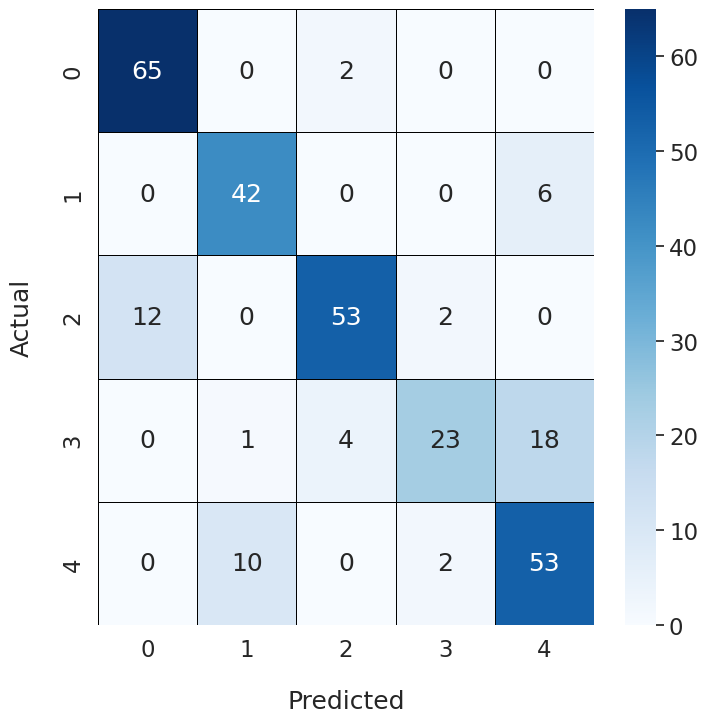

Epoch Training Time: 828.73 seconds
Test set: Average loss: 0.4180, Accuracy: 274/323 (84.83%), F1 Score: 0.8479

Fold 2
-------
Early stopping at epoch 118 due to no improvement in validation loss.


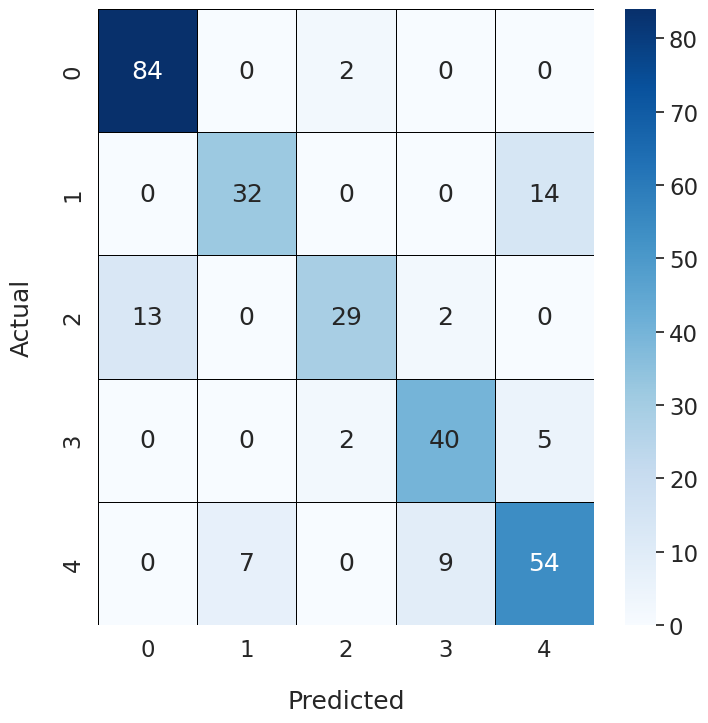

Epoch Training Time: 906.70 seconds
Test set: Average loss: 0.4538, Accuracy: 266/323 (82.35%), F1 Score: 0.8229

Fold 3
-------
Early stopping at epoch 114 due to no improvement in validation loss.


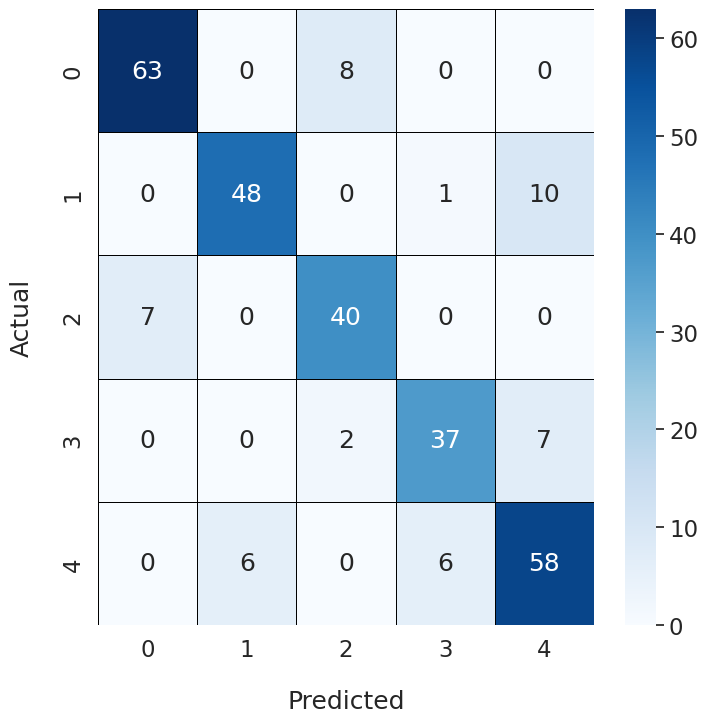

Epoch Training Time: 801.96 seconds
Test set: Average loss: 0.3947, Accuracy: 274/323 (84.83%), F1 Score: 0.8487

Fold 4
-------
Early stopping at epoch 117 due to no improvement in validation loss.


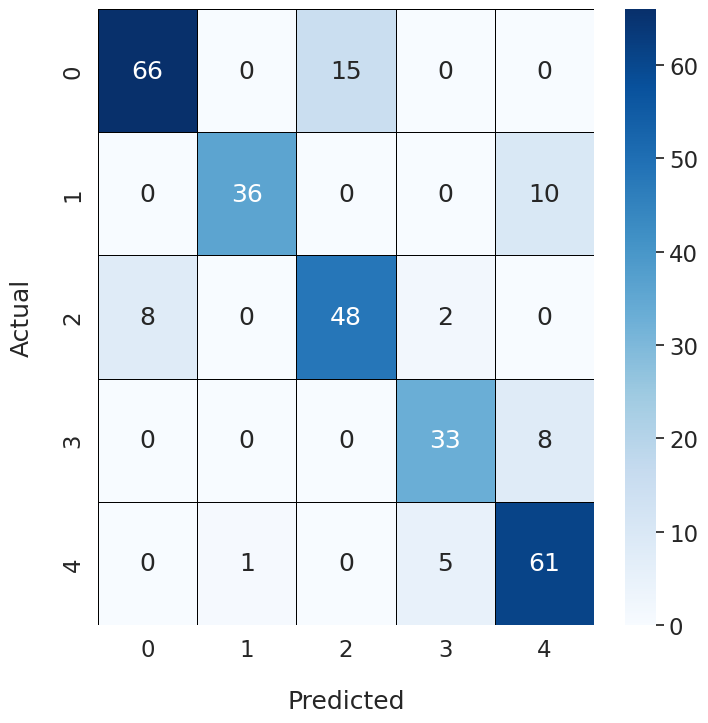

Epoch Training Time: 869.60 seconds
Test set: Average loss: 0.4964, Accuracy: 257/323 (79.57%), F1 Score: 0.7962

Fold 5
-------
Early stopping at epoch 113 due to no improvement in validation loss.


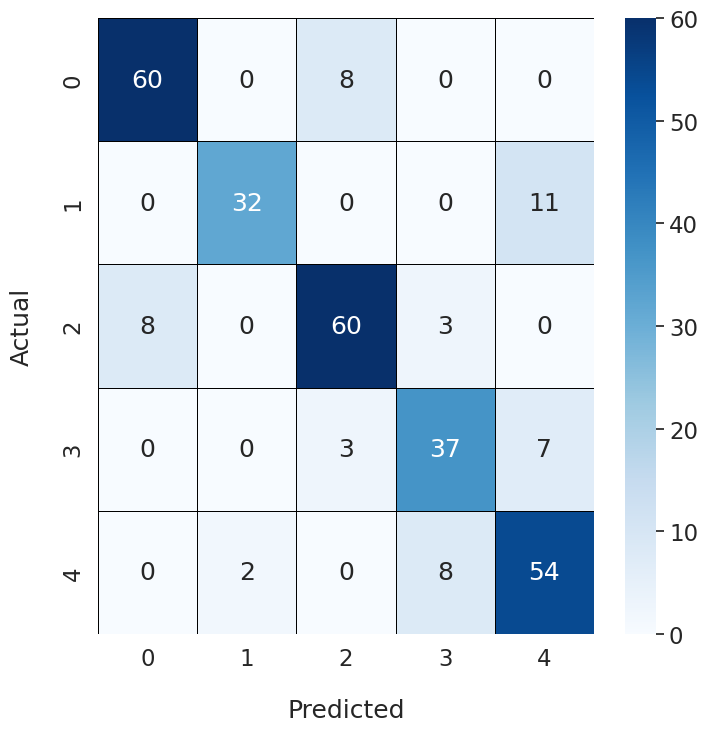

Epoch Training Time: 743.68 seconds
Test set: Average loss: 0.4367, Accuracy: 265/323 (82.04%), F1 Score: 0.8192

Fold 6
-------
Early stopping at epoch 111 due to no improvement in validation loss.


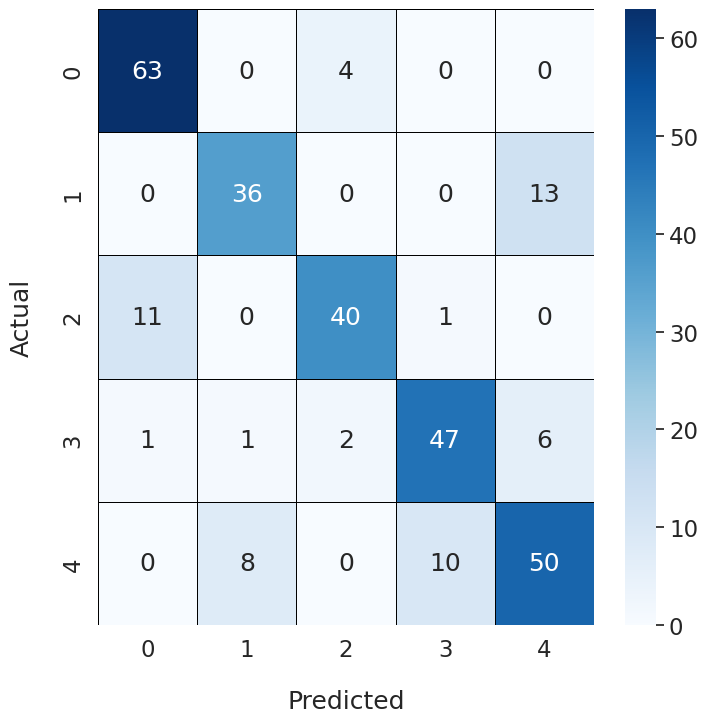

Epoch Training Time: 676.99 seconds
Test set: Average loss: 0.4153, Accuracy: 271/323 (83.90%), F1 Score: 0.8370

Fold 7
-------
Early stopping at epoch 110 due to no improvement in validation loss.


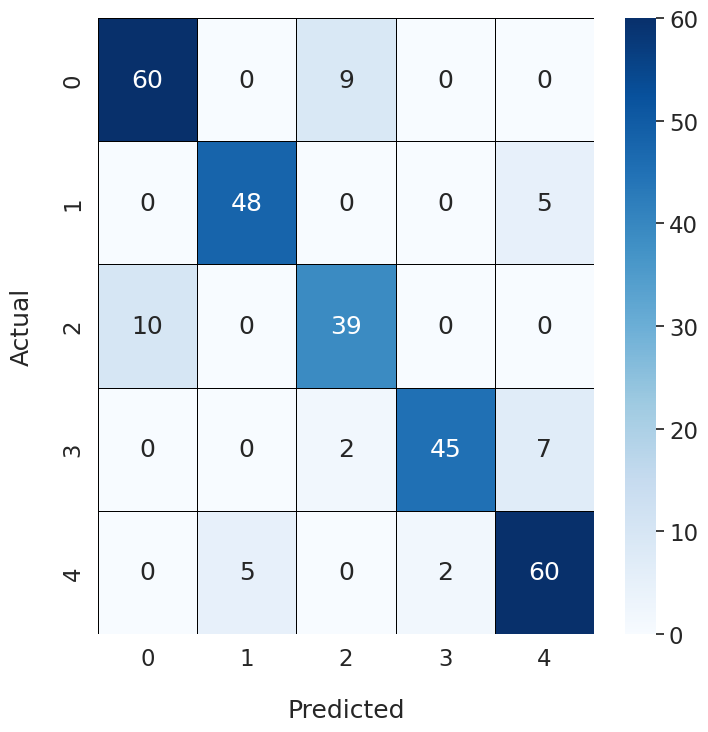

Epoch Training Time: 786.58 seconds
Test set: Average loss: 0.4365, Accuracy: 269/323 (83.28%), F1 Score: 0.8290

Fold 8
-------
Early stopping at epoch 111 due to no improvement in validation loss.


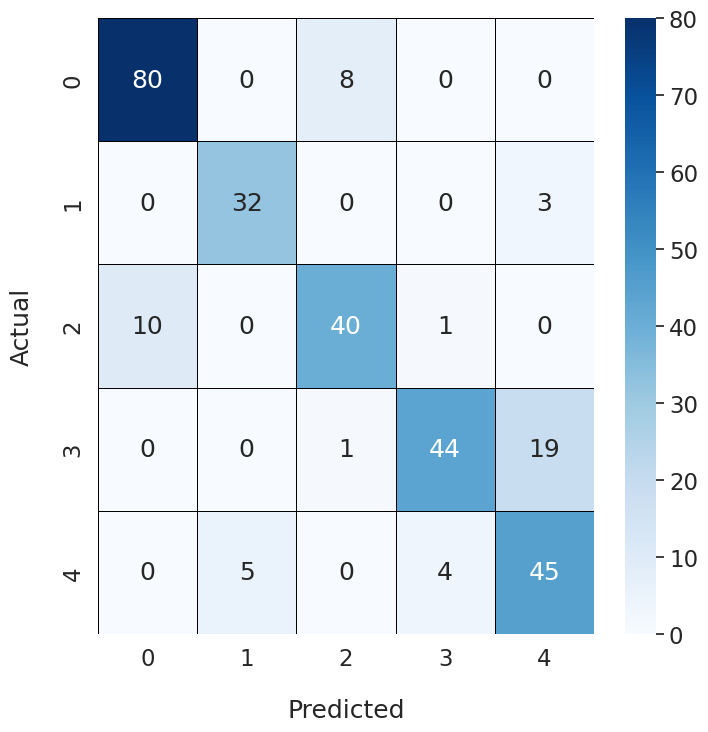

Epoch Training Time: 822.32 seconds
Test set: Average loss: 0.4703, Accuracy: 259/323 (80.19%), F1 Score: 0.7974

Fold 9
-------
Early stopping at epoch 114 due to no improvement in validation loss.


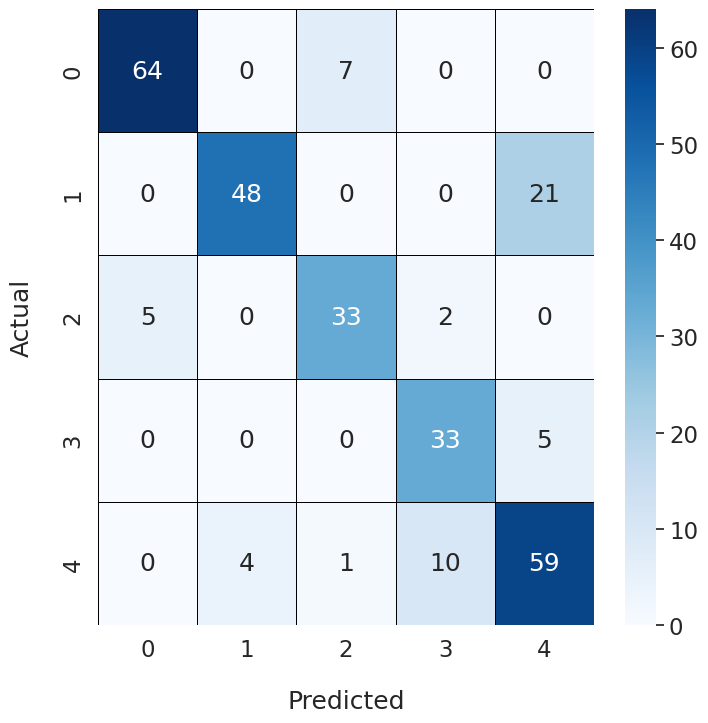

Epoch Training Time: 850.64 seconds
Test set: Average loss: 0.4105, Accuracy: 266/323 (82.35%), F1 Score: 0.8229

Fold 10
-------
Early stopping at epoch 119 due to no improvement in validation loss.


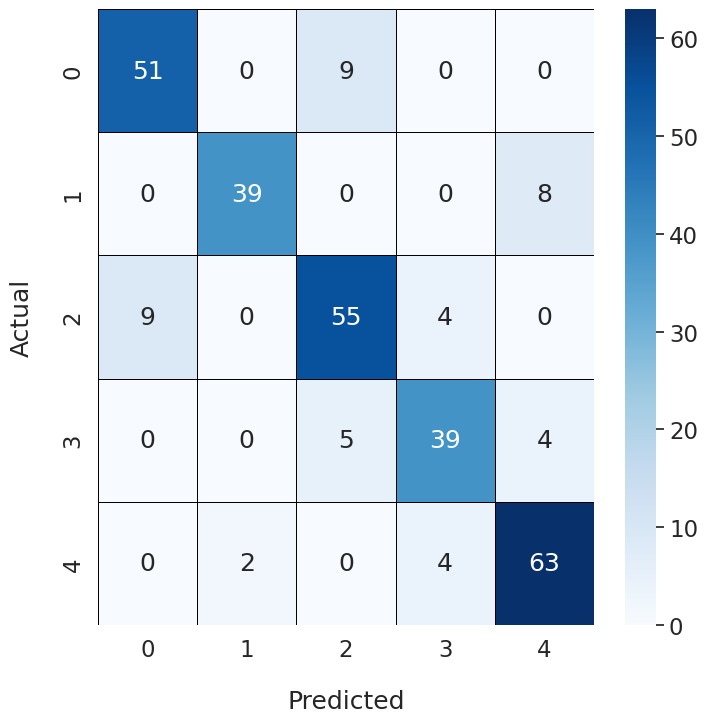

Epoch Training Time: 913.40 seconds
Test set: Average loss: 0.3976, Accuracy: 279/323 (86.38%), F1 Score: 0.8630



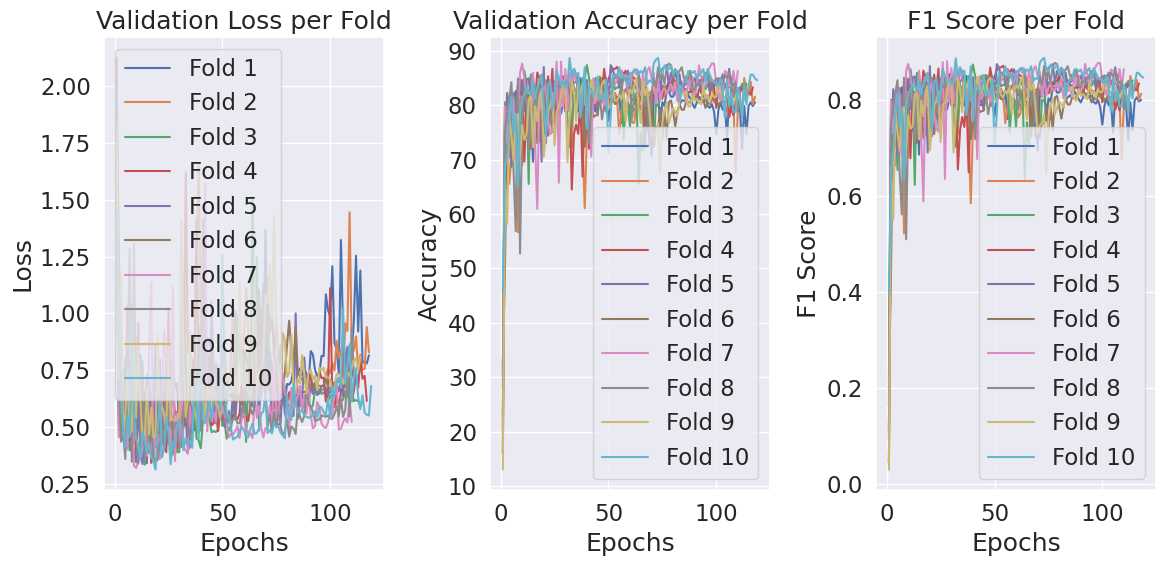

Maximum Fold Accuracy = 86.37770897832817
Maximum Fold F1 Score = 0.8630005456561716
Average Fold Accuracy = 82.97213622291022
Average Fold F1 Score = 0.828419645079854


In [11]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Restnet/SE_avg"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/SE_avg/best_SE_avg.pth"
os.makedirs("./model_Restnet/SE_avg", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_SEavg.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_SEavg(ResidualBlock_SEavg, [3, 4, 6, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 224, 224), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=lr0, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEavg_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])

    all_folds_val_loss.append(epoch_val_loss.copy())
    all_folds_val_acc.append(epoch_val_acc.copy())
    all_folds_f1.append(epochs_f1_score.copy())
            
    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet_SEavg(ResidualBlock_SEavg, [3, 4, 6, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [12]:
clear_all_memory()

Memory cleared and environment reset!


SE(max)+VGG16----------------------------------------------------------------------------------------------------------

In [13]:
import import_ipynb
from starter_restnet import *

In [14]:
class SE_Block_max(nn.Module):
    "credits: https://github.com/moskomule/senet.pytorch/blob/master/senet/se_module.py#L4"
    def __init__(self, c, r=8):
        super().__init__()
        self.squeeze = nn.AdaptiveMaxPool2d(1)
        self.excitation = nn.Sequential(
            nn.Linear(c, c // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(c // r, c, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        bs, c, _, _ = x.shape
        y = self.squeeze(x).view(bs, c)
        y = self.excitation(y).view(bs, c, 1, 1)
        return x * y.expand_as(x)

In [15]:
class ResidualBlock_SEmax(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=8):
            super(ResidualBlock_SEmax, self).__init__()
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels))
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels
            # add SE block
            self.se = SE_Block_max(out_channels, r)

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)

            out = self.se(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_SEmax(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_SEmax, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.avgpool = nn.AvgPool2d(7, stride=1)
            self.fc = nn.Linear(512, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.avgpool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [16]:
all_folds_val_loss = [] 
all_folds_val_acc = [] 
all_folds_f1 = []
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 3.69 GMac
Model Params: 21.61 M
Early stopping at epoch 104 due to no improvement in validation loss.


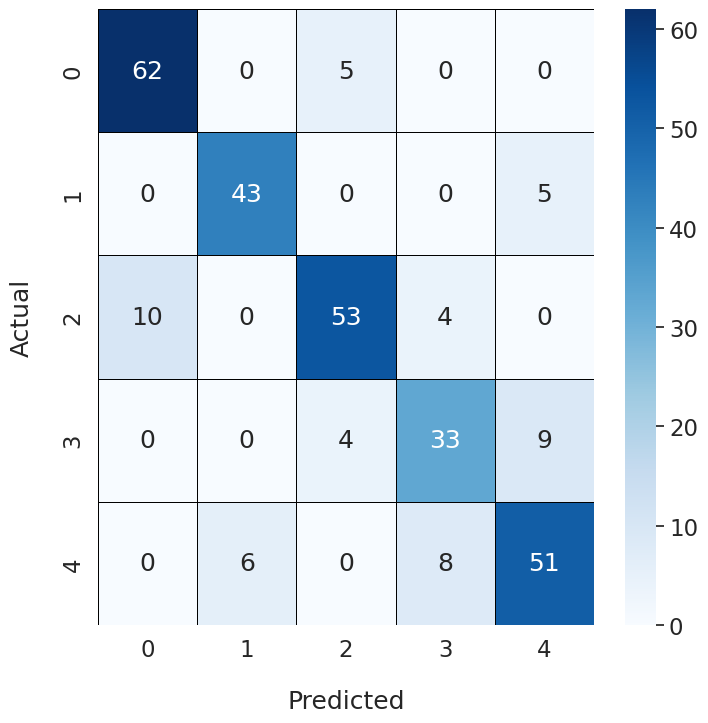

Epoch Training Time: 790.05 seconds
Test set: Average loss: 0.4972, Accuracy: 253/323 (78.33%), F1 Score: 0.7833

Fold 2
-------
Early stopping at epoch 126 due to no improvement in validation loss.


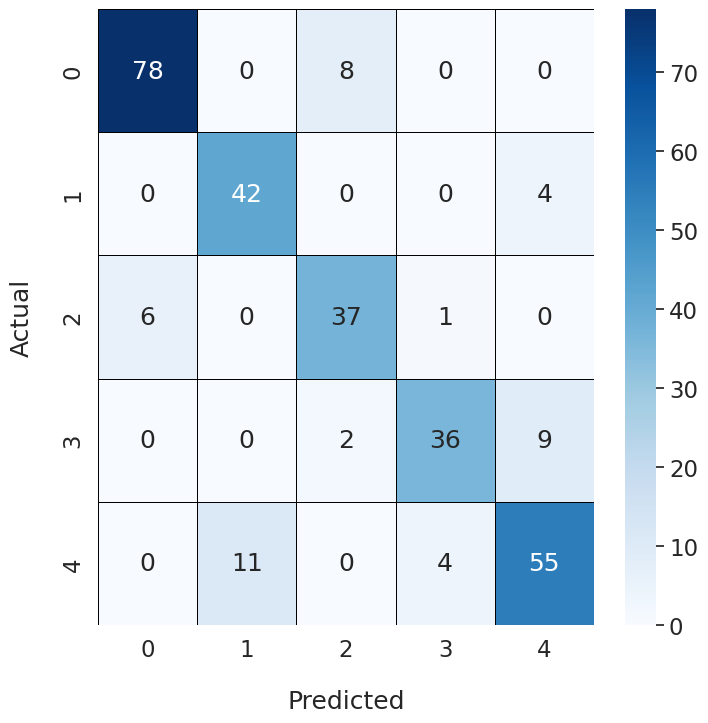

Epoch Training Time: 873.31 seconds
Test set: Average loss: 0.4668, Accuracy: 271/323 (83.90%), F1 Score: 0.8381

Fold 3
-------
Early stopping at epoch 104 due to no improvement in validation loss.


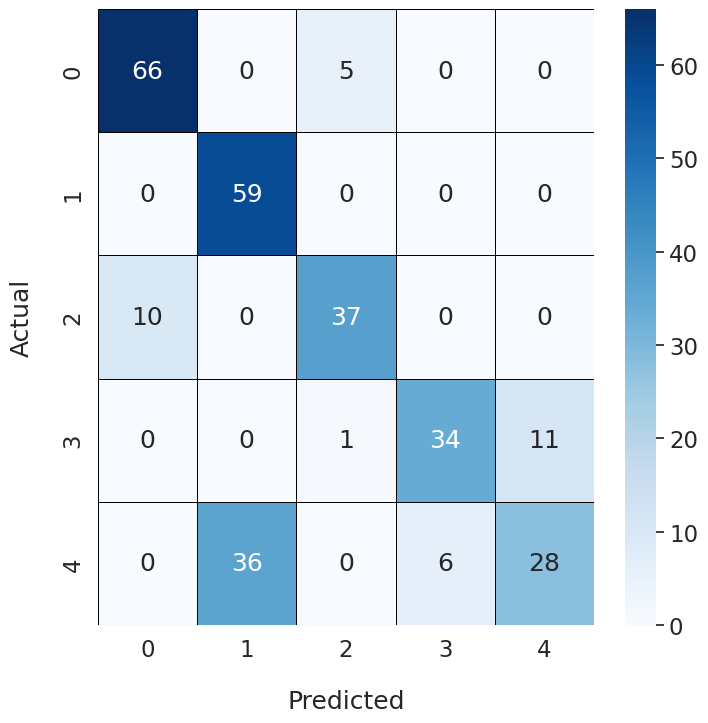

Epoch Training Time: 706.50 seconds
Test set: Average loss: 0.4877, Accuracy: 253/323 (78.33%), F1 Score: 0.7842

Fold 4
-------
Early stopping at epoch 128 due to no improvement in validation loss.


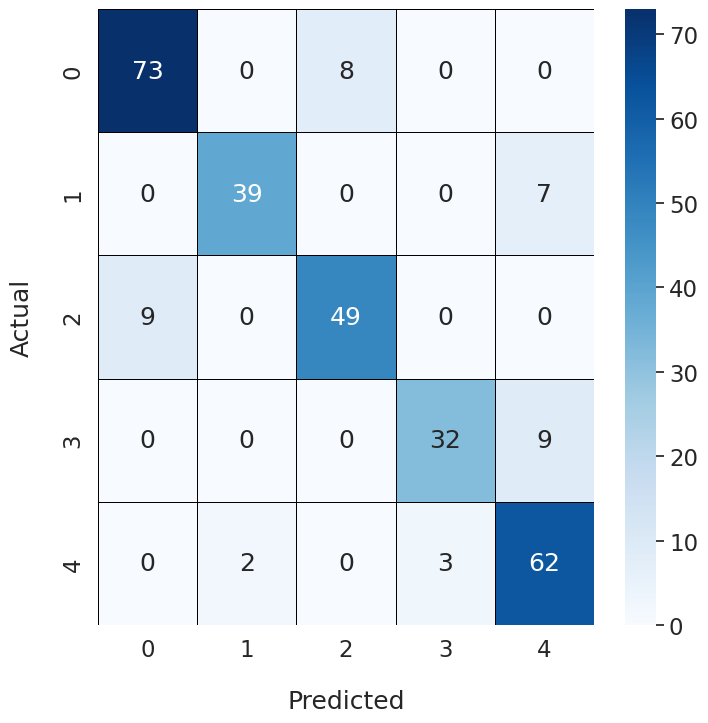

Epoch Training Time: 931.57 seconds
Test set: Average loss: 0.4704, Accuracy: 270/323 (83.59%), F1 Score: 0.8359

Fold 5
-------
Early stopping at epoch 108 due to no improvement in validation loss.


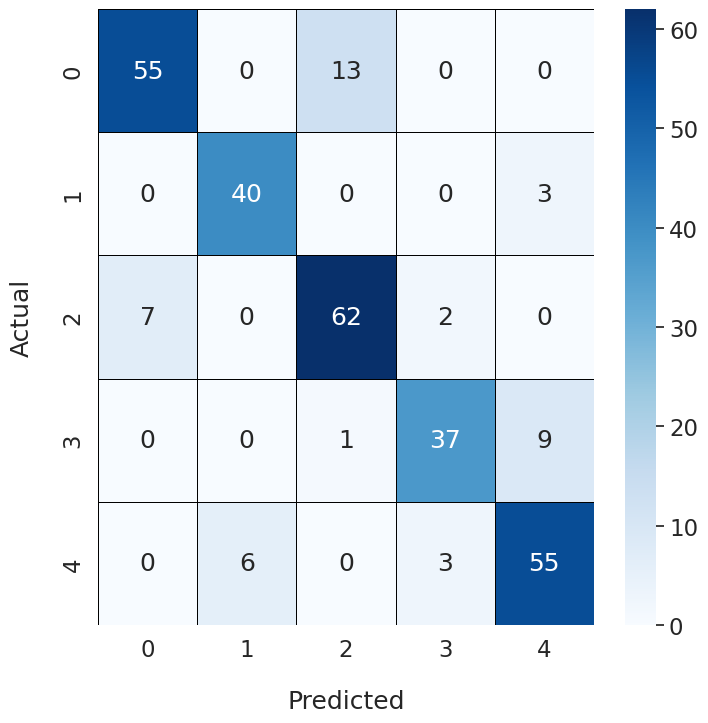

Epoch Training Time: 815.20 seconds
Test set: Average loss: 0.5395, Accuracy: 258/323 (79.88%), F1 Score: 0.7916

Fold 6
-------
Early stopping at epoch 117 due to no improvement in validation loss.


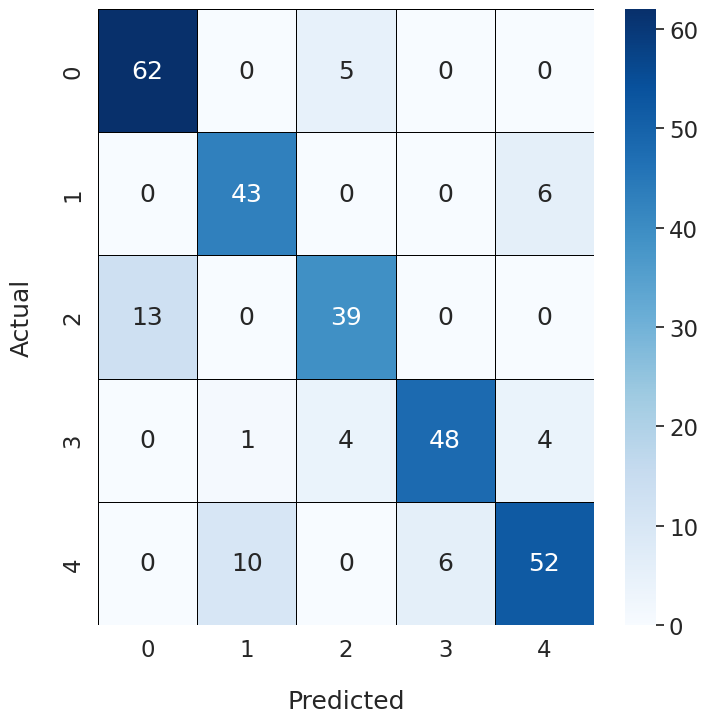

Epoch Training Time: 829.11 seconds
Test set: Average loss: 0.4487, Accuracy: 274/323 (84.83%), F1 Score: 0.8472

Fold 7
-------
Early stopping at epoch 114 due to no improvement in validation loss.


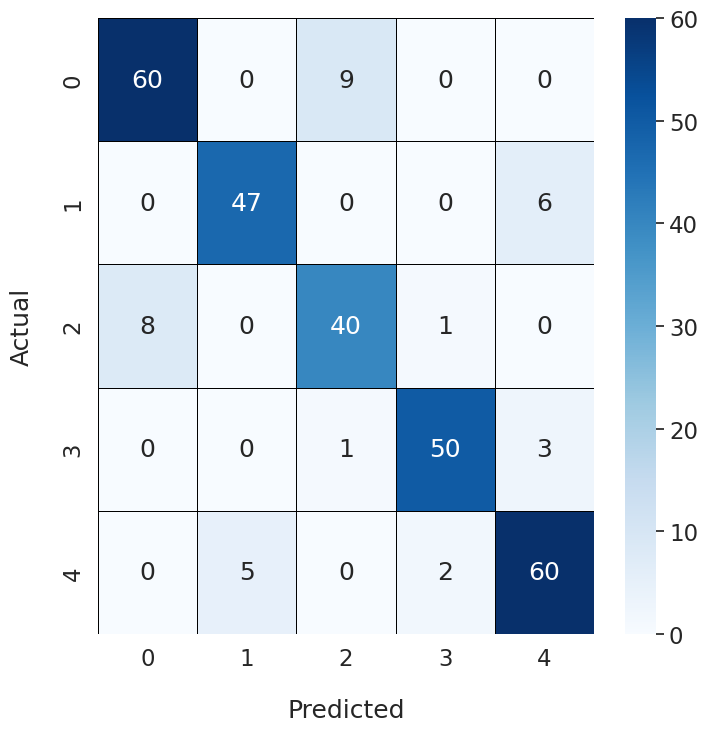

Epoch Training Time: 886.58 seconds
Test set: Average loss: 0.4685, Accuracy: 263/323 (81.42%), F1 Score: 0.8141

Fold 8
-------
Early stopping at epoch 114 due to no improvement in validation loss.


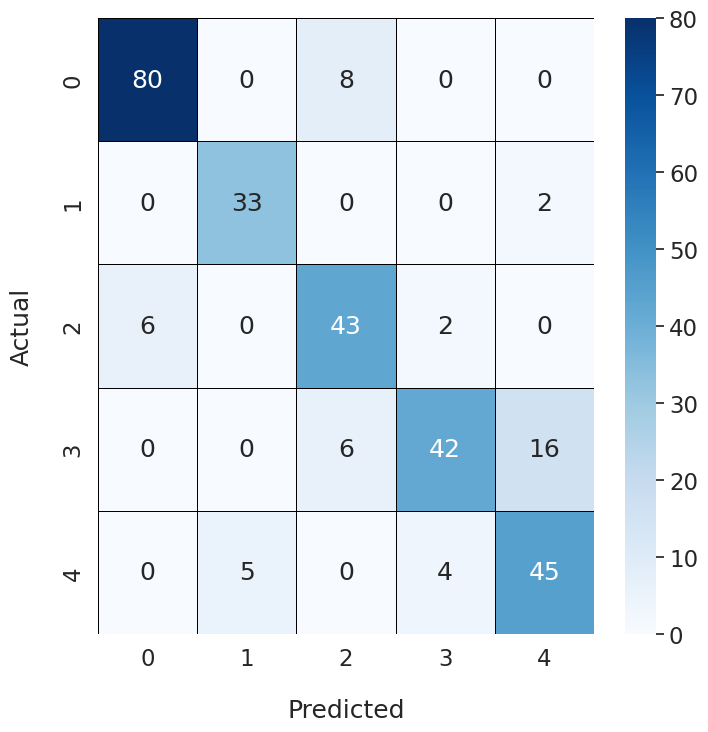

Epoch Training Time: 865.73 seconds
Test set: Average loss: 0.4235, Accuracy: 272/323 (84.21%), F1 Score: 0.8413

Fold 9
-------
Early stopping at epoch 118 due to no improvement in validation loss.


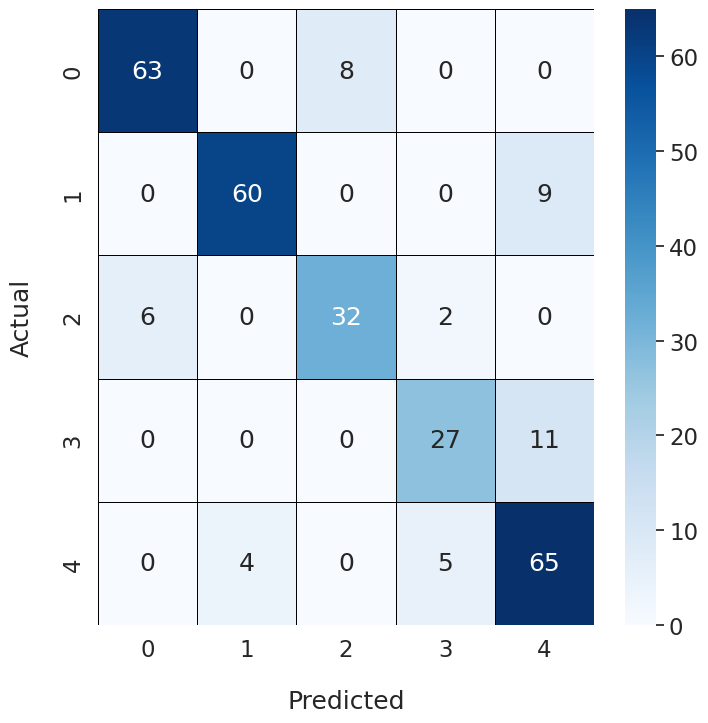

Epoch Training Time: 898.62 seconds
Test set: Average loss: 0.4396, Accuracy: 273/323 (84.52%), F1 Score: 0.8433

Fold 10
-------
Early stopping at epoch 111 due to no improvement in validation loss.


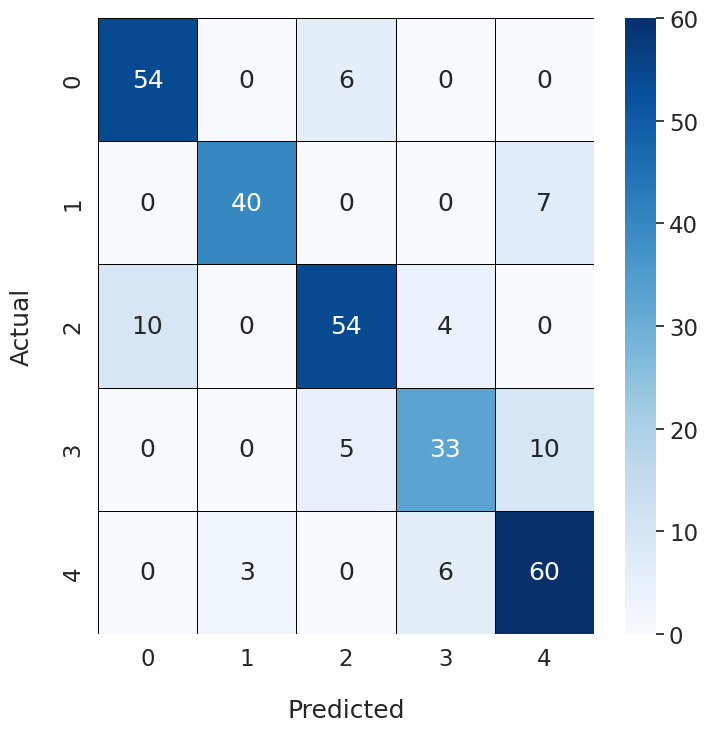

Epoch Training Time: 731.68 seconds
Test set: Average loss: 0.4487, Accuracy: 269/323 (83.28%), F1 Score: 0.8306



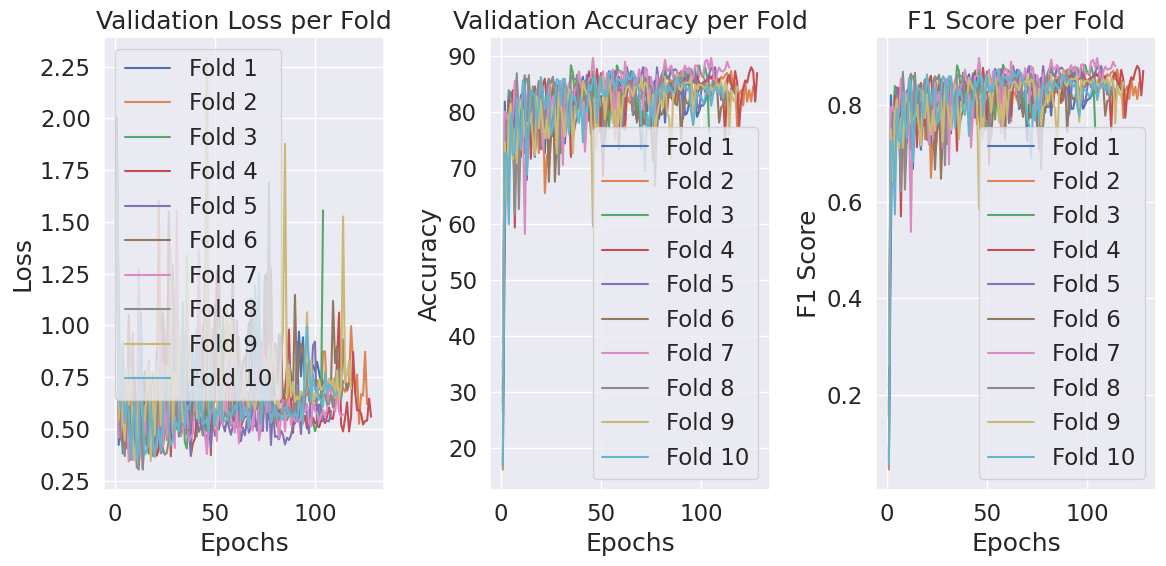

Maximum Fold Accuracy = 84.82972136222911
Maximum Fold F1 Score = 0.8472165007245803
Average Fold Accuracy = 82.22910216718267
Average Fold F1 Score = 0.8209560181041471


In [17]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Restnet/SE_max"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/SE_max/best_SE_max.pth"
os.makedirs("./model_Restnet/SE_max", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_SEmax.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []

   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_SEmax(ResidualBlock_SEmax, [3, 4, 6, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 224, 224), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=lr0, momentum=0.9)
    
    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEmax_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------
    

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    best_model = ResNet_SEmax(ResidualBlock_SEmax, [3, 4, 6, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    

max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [18]:
clear_all_memory()

Memory cleared and environment reset!


SE mixed pool + VGG16---------------------------------------------------------------------------------------

In [19]:
from Mixedpool05 import mixedPool

alpha = 0.5


In [20]:
import import_ipynb
from starter_restnet import *

In [21]:
class SE_Block_mix(nn.Module):
    "credits: https://github.com/moskomule/senet.pytorch/blob/master/senet/se_module.py#L4"
    def __init__(self, c, r=8):
        super().__init__()
        self.squeeze = mixedPool()
        self.excitation = nn.Sequential(
            nn.Linear(c, c // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(c // r, c, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        bs, c, _, _ = x.shape
        y = self.squeeze(x).view(bs, c)
        y = self.excitation(y).view(bs, c, 1, 1)
        return x * y.expand_as(x)

In [22]:
class ResidualBlock_SEmix(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=8):
            super(ResidualBlock_SEmix, self).__init__()
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels))
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels
            # add SE block
            self.se = SE_Block_mix(out_channels, r)

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)

            out = self.se(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_SEmix(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_SEmix, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.avgpool = nn.AvgPool2d(7, stride=1)
            self.fc = nn.Linear(512, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.avgpool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [23]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 3.69 GMac
Model Params: 21.61 M
Early stopping at epoch 110 due to no improvement in validation loss.


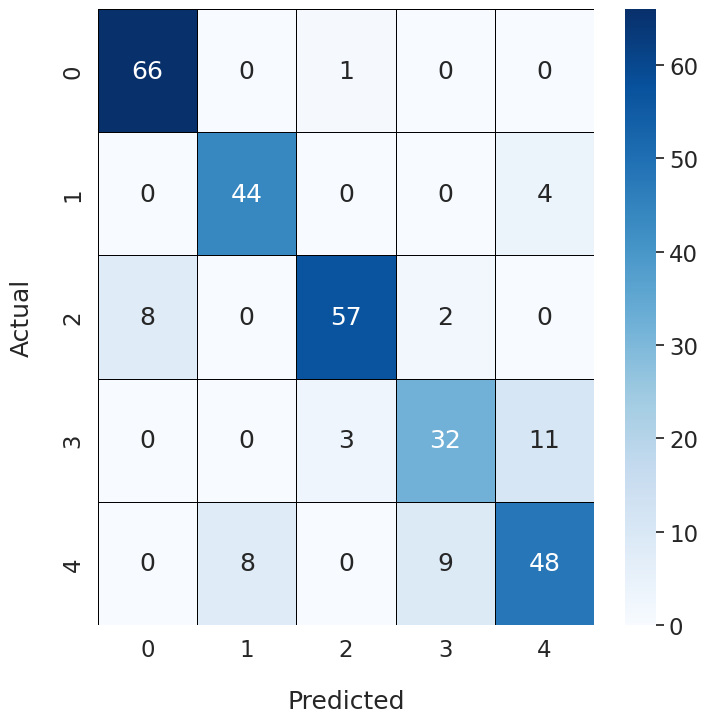

Epoch Training Time: 881.21 seconds
Test set: Average loss: 0.4500, Accuracy: 263/323 (81.42%), F1 Score: 0.8139

Fold 2
-------
Early stopping at epoch 147 due to no improvement in validation loss.


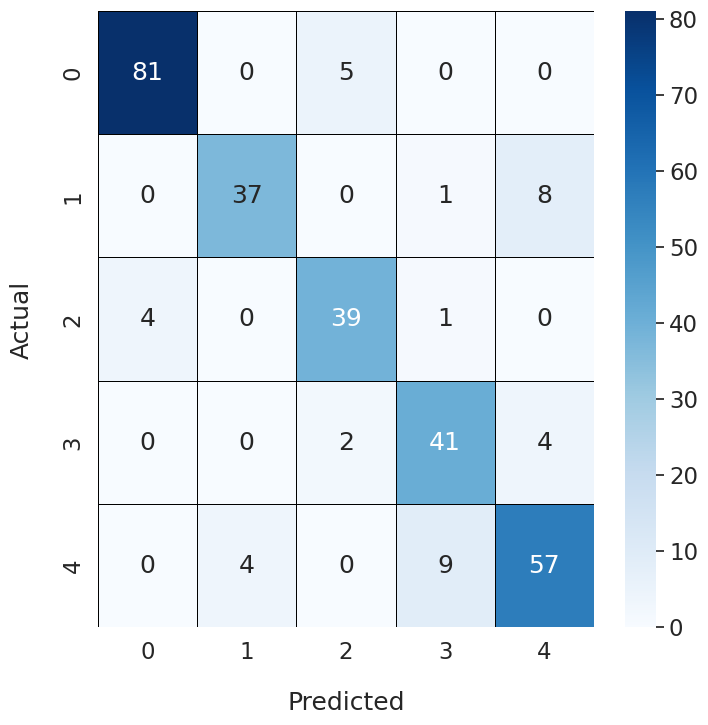

Epoch Training Time: 1230.23 seconds
Test set: Average loss: 0.5435, Accuracy: 277/323 (85.76%), F1 Score: 0.8575

Fold 3
-------
Early stopping at epoch 117 due to no improvement in validation loss.


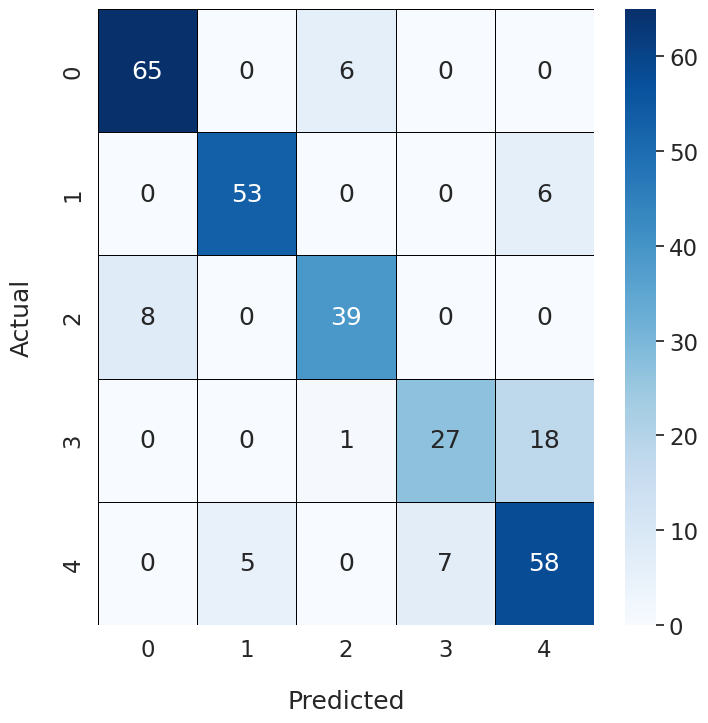

Epoch Training Time: 1055.04 seconds
Test set: Average loss: 0.4231, Accuracy: 279/323 (86.38%), F1 Score: 0.8636

Fold 4
-------
Early stopping at epoch 137 due to no improvement in validation loss.


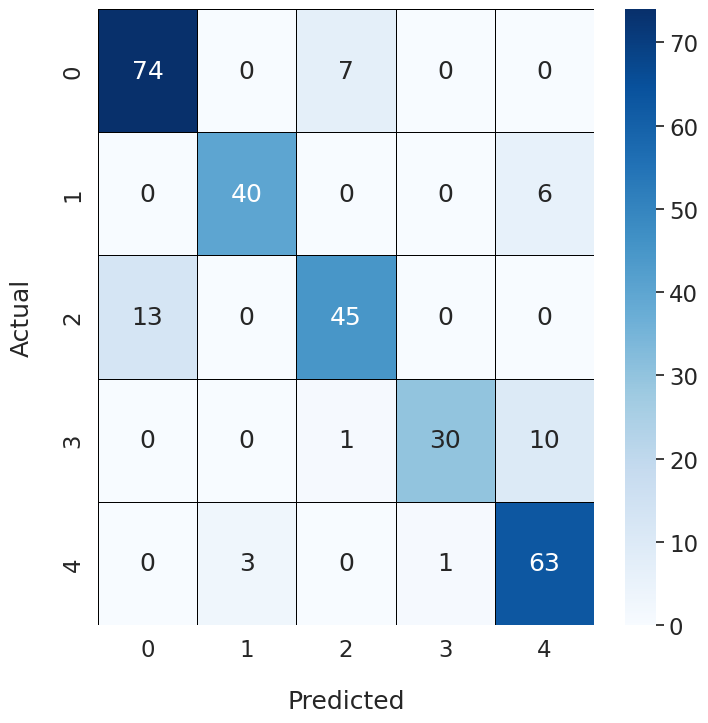

Epoch Training Time: 1098.56 seconds
Test set: Average loss: 0.4808, Accuracy: 279/323 (86.38%), F1 Score: 0.8633

Fold 5
-------
Early stopping at epoch 112 due to no improvement in validation loss.


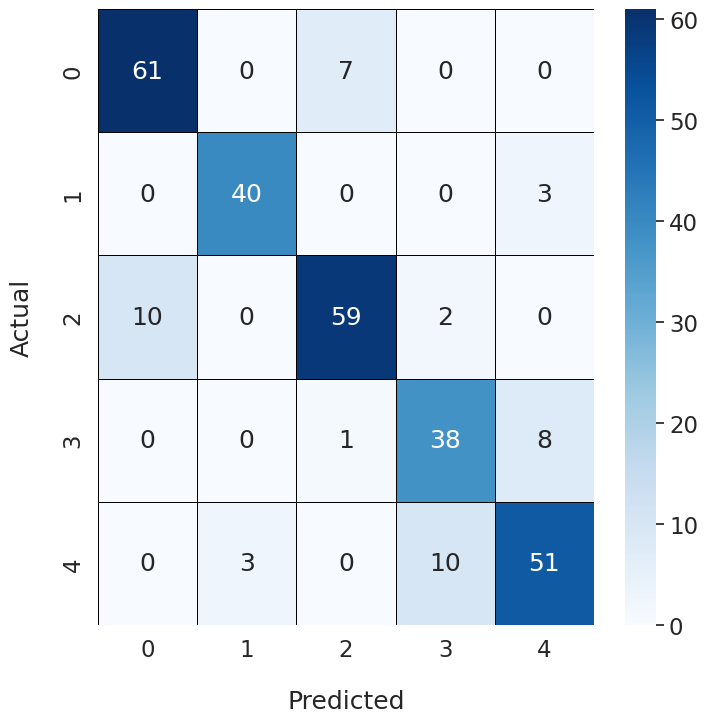

Epoch Training Time: 1108.57 seconds
Test set: Average loss: 0.4783, Accuracy: 261/323 (80.80%), F1 Score: 0.8075

Fold 6
-------
Early stopping at epoch 119 due to no improvement in validation loss.


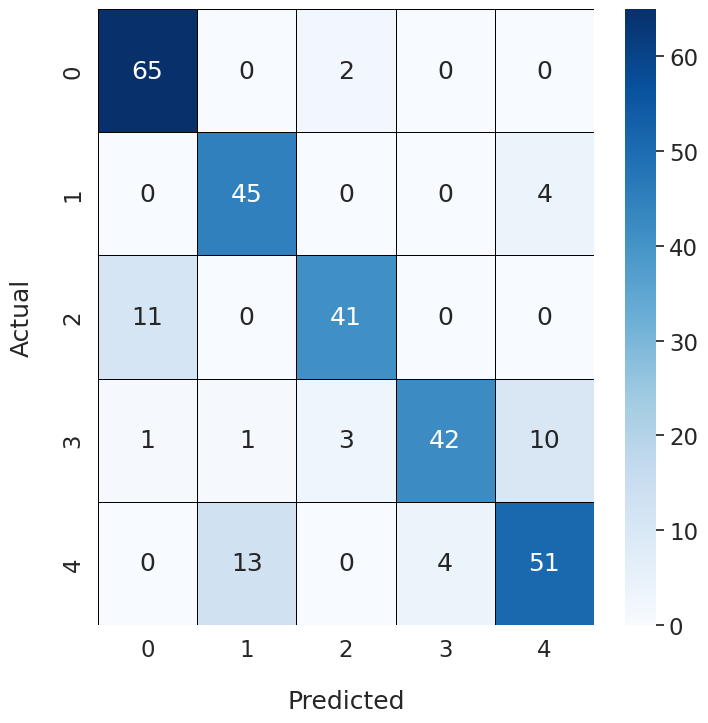

Epoch Training Time: 956.78 seconds
Test set: Average loss: 0.4721, Accuracy: 272/323 (84.21%), F1 Score: 0.8404

Fold 7
-------
Early stopping at epoch 111 due to no improvement in validation loss.


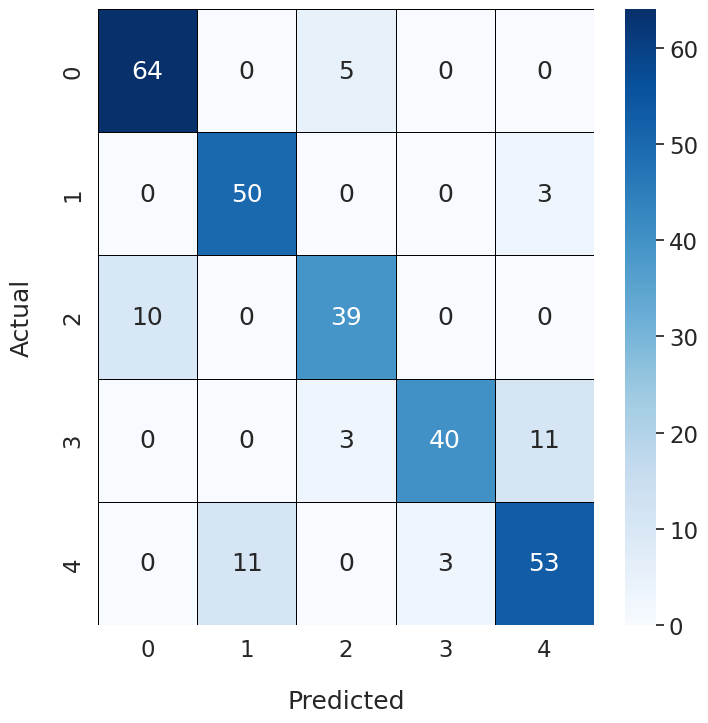

Epoch Training Time: 884.53 seconds
Test set: Average loss: 0.4312, Accuracy: 263/323 (81.42%), F1 Score: 0.8120

Fold 8
-------
Early stopping at epoch 122 due to no improvement in validation loss.


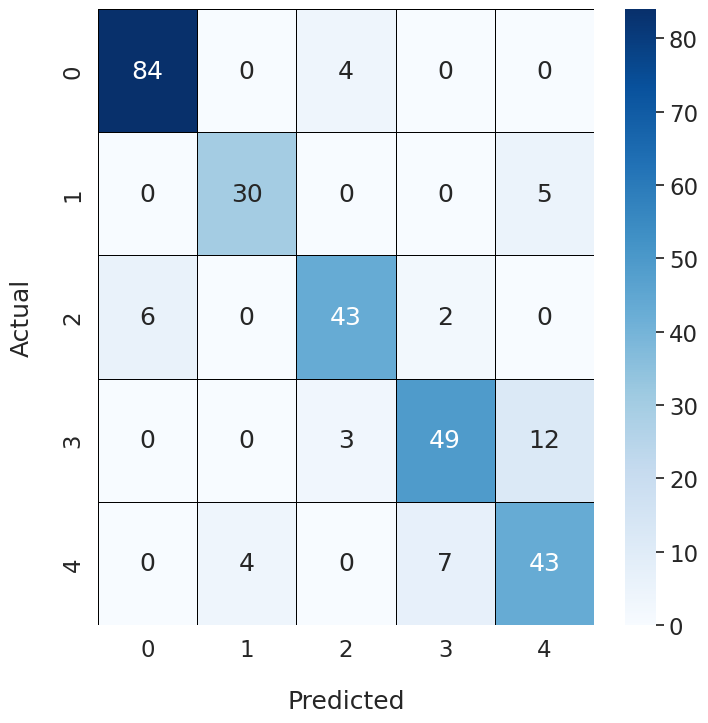

Epoch Training Time: 938.61 seconds
Test set: Average loss: 0.4541, Accuracy: 267/323 (82.66%), F1 Score: 0.8266

Fold 9
-------
Early stopping at epoch 115 due to no improvement in validation loss.


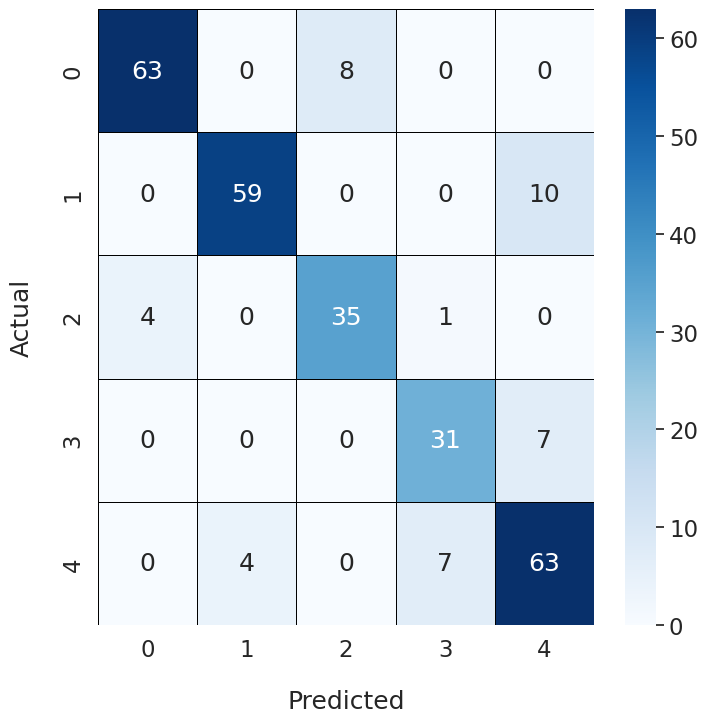

Epoch Training Time: 925.59 seconds
Test set: Average loss: 0.4671, Accuracy: 266/323 (82.35%), F1 Score: 0.8222

Fold 10
-------
Early stopping at epoch 116 due to no improvement in validation loss.


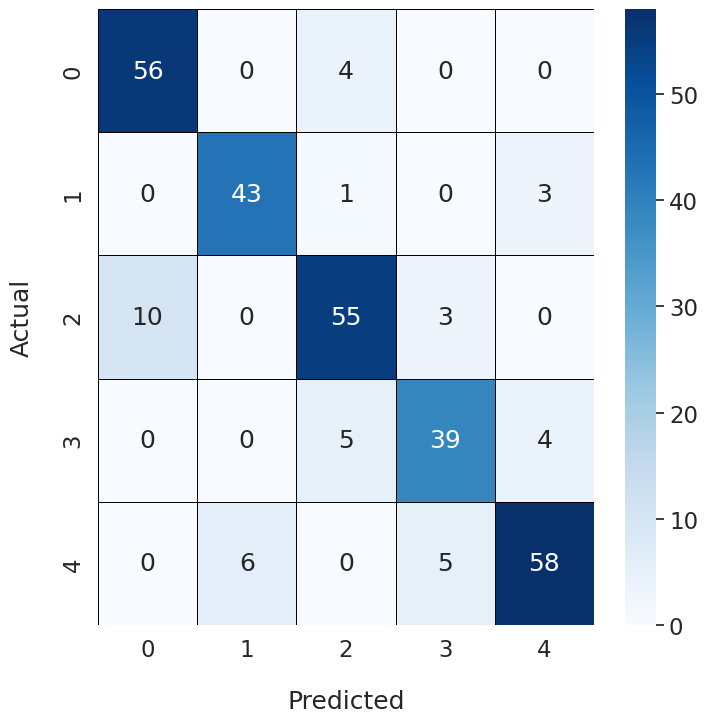

Epoch Training Time: 794.89 seconds
Test set: Average loss: 0.4218, Accuracy: 274/323 (84.83%), F1 Score: 0.8462



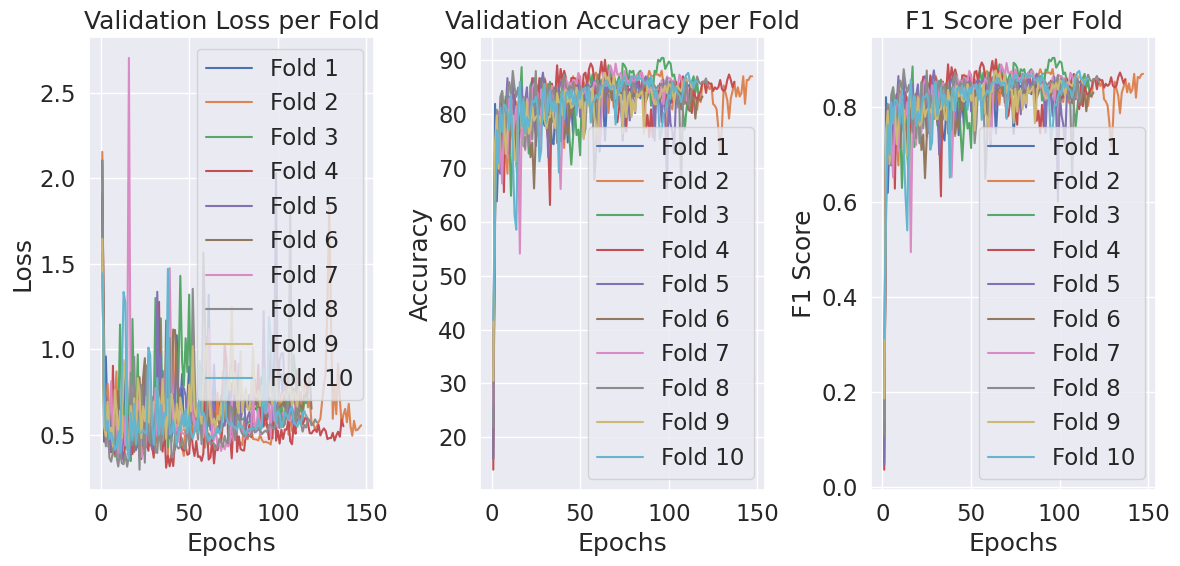

Maximum Fold Accuracy = 86.37770897832817
Maximum Fold F1 Score = 0.8635950737308347
Average Fold Accuracy = 83.62229102167183
Average Fold F1 Score = 0.8353183534426701


In [24]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Restnet/SE_mix"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/SE_mix/best_SE_mix.pth"
os.makedirs("./model_Restnet/SE_mix", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_SEmix.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_SEmix(ResidualBlock_SEmix, [3, 4, 6, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 224, 224), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=lr0, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEmix_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet_SEmix(ResidualBlock_SEmix, [3, 4, 6, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [25]:
clear_all_memory()

Memory cleared and environment reset!


SE fuzzy mixed pool + Restnet34--------------------------------------------------------------------------------------


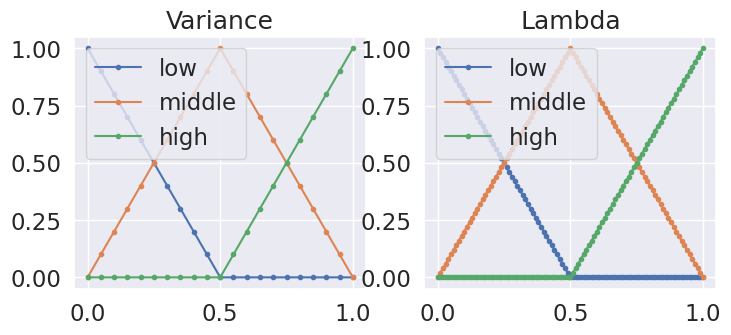

fuzzy_pool


In [26]:
from Mixedpool_fuzzy import mixedPool_fuzz

In [27]:
import import_ipynb
from starter_restnet import *
import sys

In [28]:
class SE_Block_fuzz(nn.Module):
    "credits: https://github.com/moskomule/senet.pytorch/blob/master/senet/se_module.py#L4"
    def __init__(self, c, r=16):  # alway tune
        super().__init__()
        self.squeeze = mixedPool_fuzz()
        self.excitation = nn.Sequential(
            nn.Linear(c, c // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(c // r, c, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        bs, c, _, _ = x.shape
        y = self.squeeze(x).view(bs, c)
        y = self.excitation(y).view(bs, c, 1, 1)
        return x * y.expand_as(x)

In [29]:
class ResidualBlock_SEfuzz(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=8):
            super(ResidualBlock_SEfuzz, self).__init__()
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels))
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels
            # add SE block
            self.se = SE_Block_fuzz(out_channels, r)

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)

            out = self.se(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_SEfuzz(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_SEfuzz, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.avgpool = nn.AvgPool2d(7, stride=1)
            self.fc = nn.Linear(512, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.avgpool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [30]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 3.69 GMac
Model Params: 21.61 M
Early stopping at epoch 106 due to no improvement in validation loss.


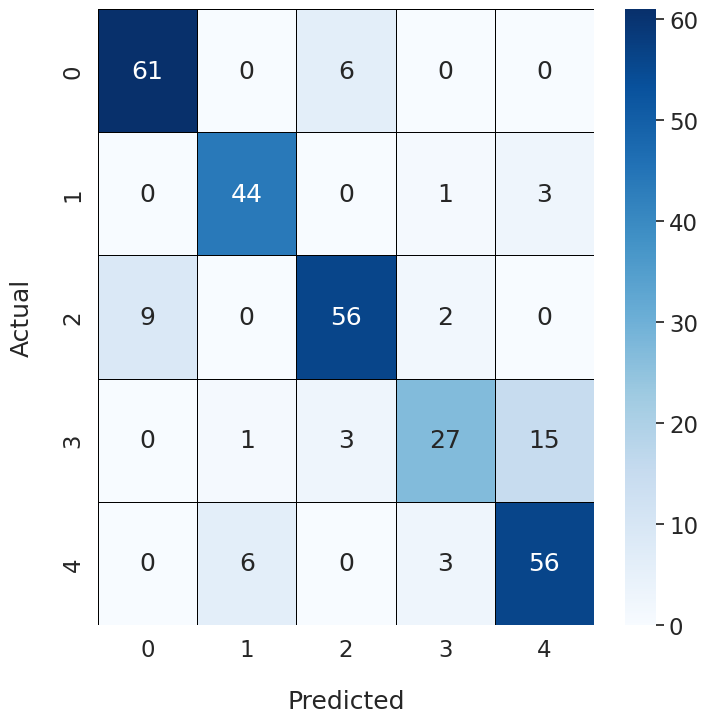

Epoch Training Time: 873.40 seconds
Test set: Average loss: 0.5138, Accuracy: 257/323 (79.57%), F1 Score: 0.7917

Fold 2
-------
Early stopping at epoch 114 due to no improvement in validation loss.


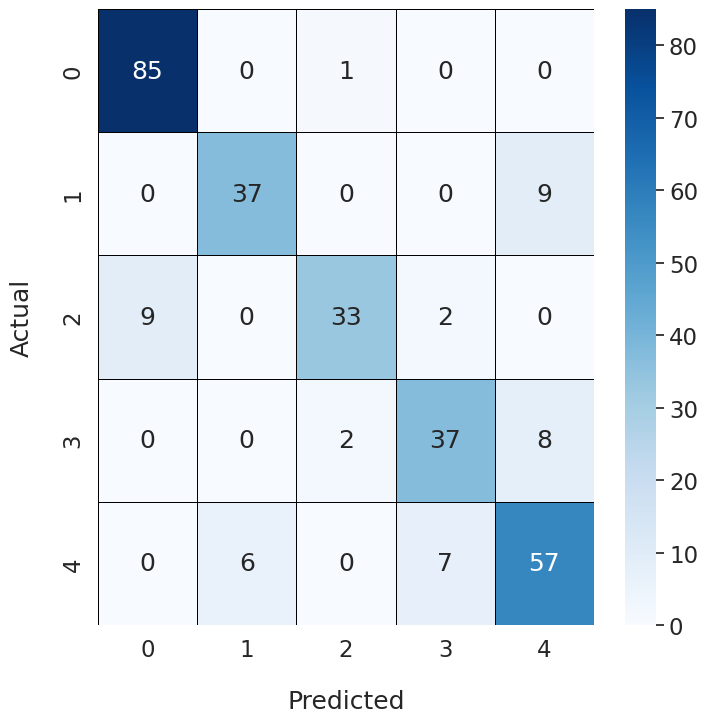

Epoch Training Time: 943.74 seconds
Test set: Average loss: 0.4271, Accuracy: 267/323 (82.66%), F1 Score: 0.8245

Fold 3
-------
Early stopping at epoch 126 due to no improvement in validation loss.


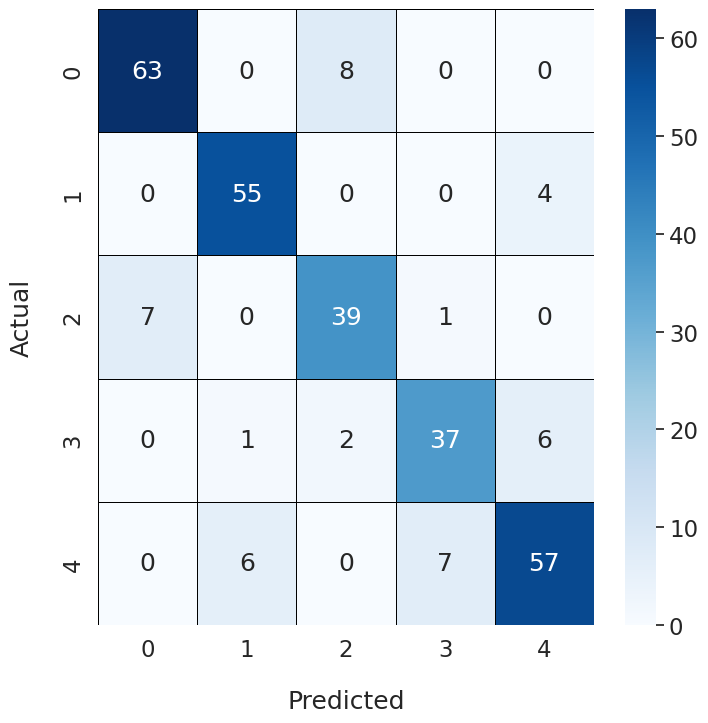

Epoch Training Time: 1042.27 seconds
Test set: Average loss: 0.4145, Accuracy: 274/323 (84.83%), F1 Score: 0.8453

Fold 4
-------
Early stopping at epoch 121 due to no improvement in validation loss.


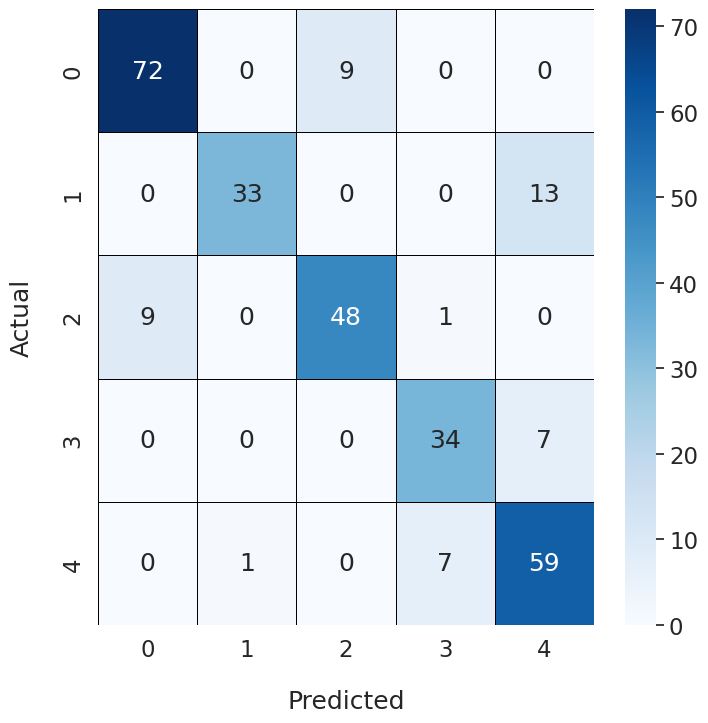

Epoch Training Time: 1071.82 seconds
Test set: Average loss: 0.5520, Accuracy: 266/323 (82.35%), F1 Score: 0.8191

Fold 5
-------
Early stopping at epoch 130 due to no improvement in validation loss.


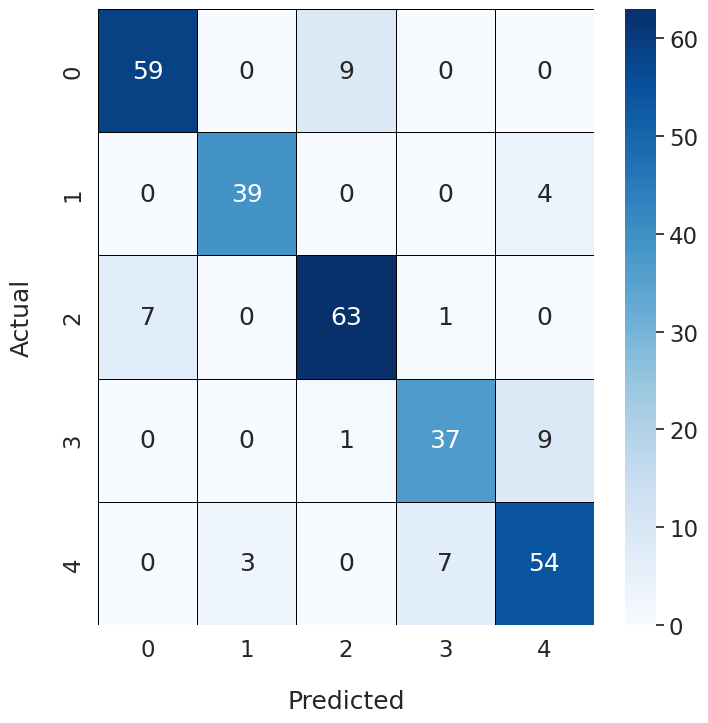

Epoch Training Time: 1303.98 seconds
Test set: Average loss: 0.5318, Accuracy: 269/323 (83.28%), F1 Score: 0.8307

Fold 6
-------
Early stopping at epoch 113 due to no improvement in validation loss.


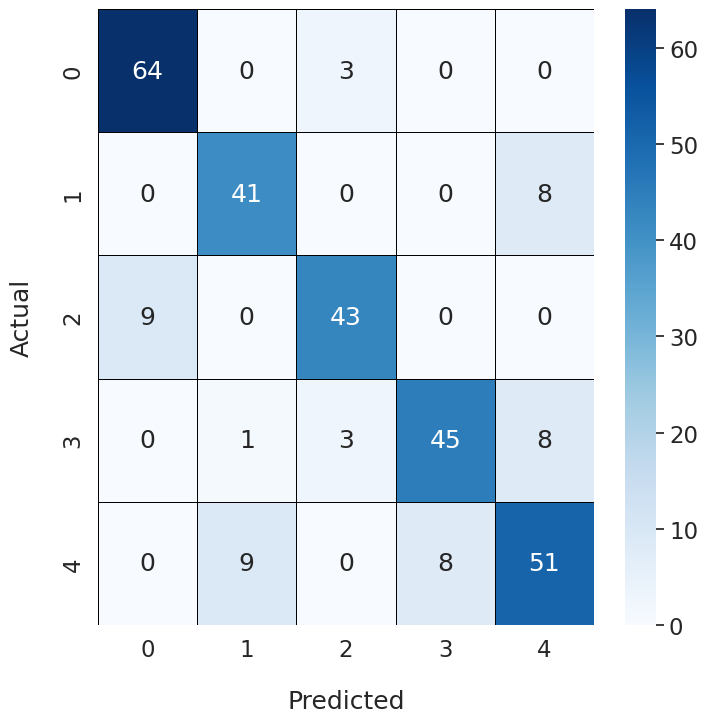

Epoch Training Time: 983.60 seconds
Test set: Average loss: 0.4407, Accuracy: 273/323 (84.52%), F1 Score: 0.8442

Fold 7
-------
Early stopping at epoch 114 due to no improvement in validation loss.


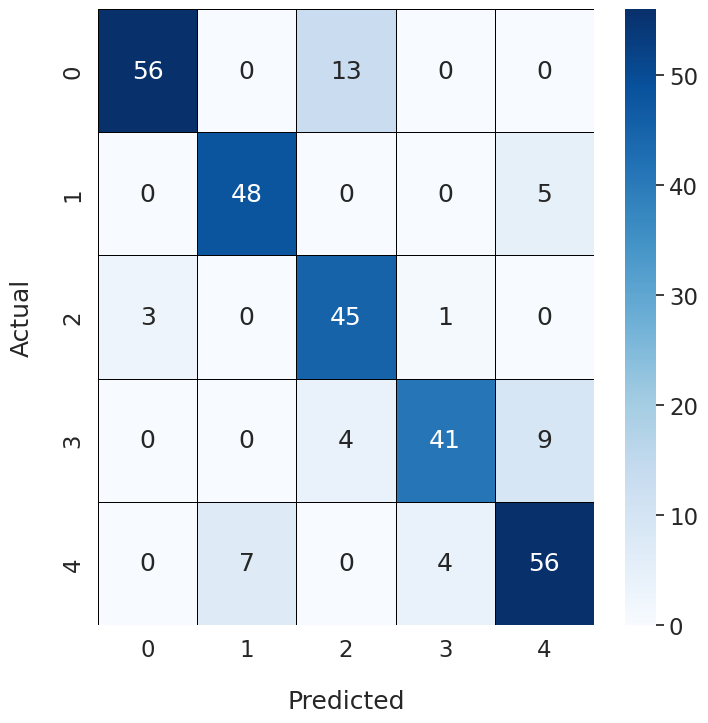

Epoch Training Time: 1323.44 seconds
Test set: Average loss: 0.4686, Accuracy: 266/323 (82.35%), F1 Score: 0.8207

Fold 8
-------
Early stopping at epoch 109 due to no improvement in validation loss.


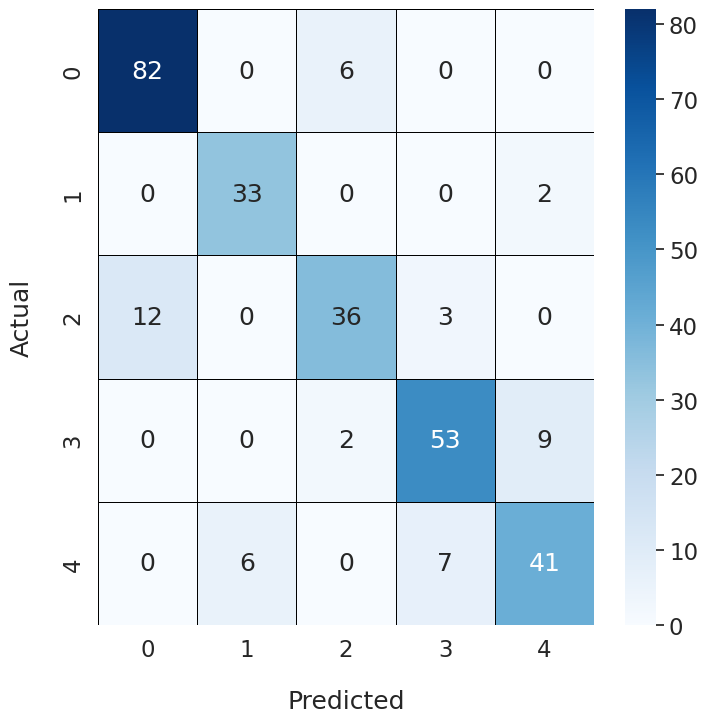

Epoch Training Time: 1119.47 seconds
Test set: Average loss: 0.3905, Accuracy: 280/323 (86.69%), F1 Score: 0.8662

Fold 9
-------
Early stopping at epoch 112 due to no improvement in validation loss.


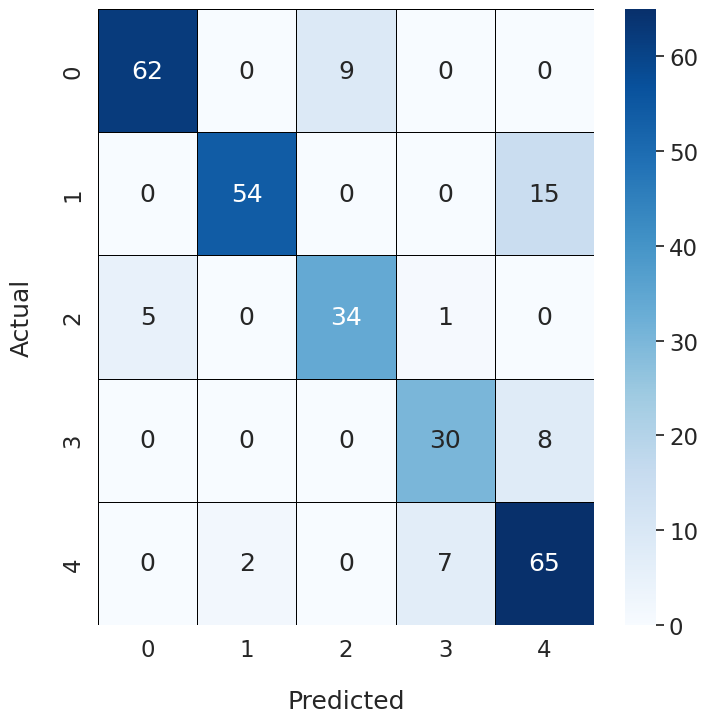

Epoch Training Time: 1231.39 seconds
Test set: Average loss: 0.4223, Accuracy: 267/323 (82.66%), F1 Score: 0.8239

Fold 10
-------
Early stopping at epoch 126 due to no improvement in validation loss.


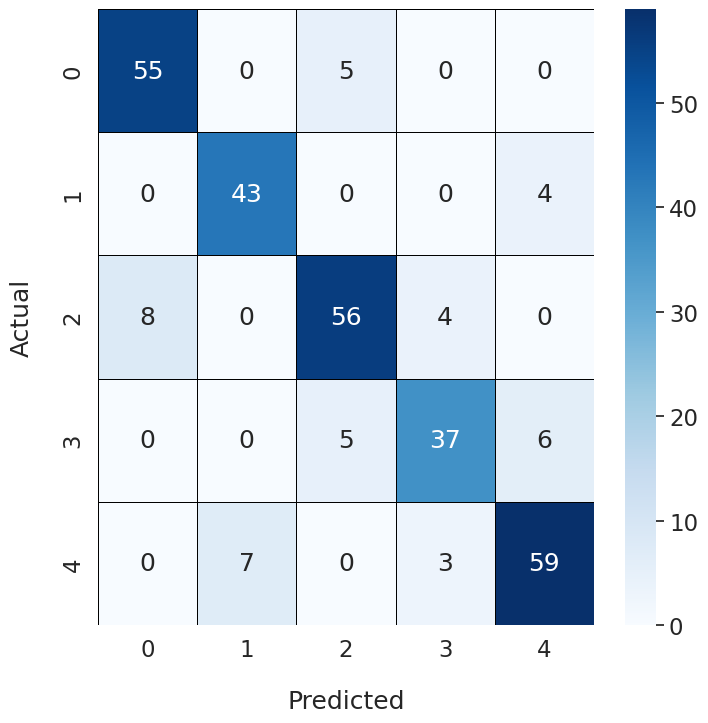

Epoch Training Time: 1316.68 seconds
Test set: Average loss: 0.4581, Accuracy: 274/323 (84.83%), F1 Score: 0.8469



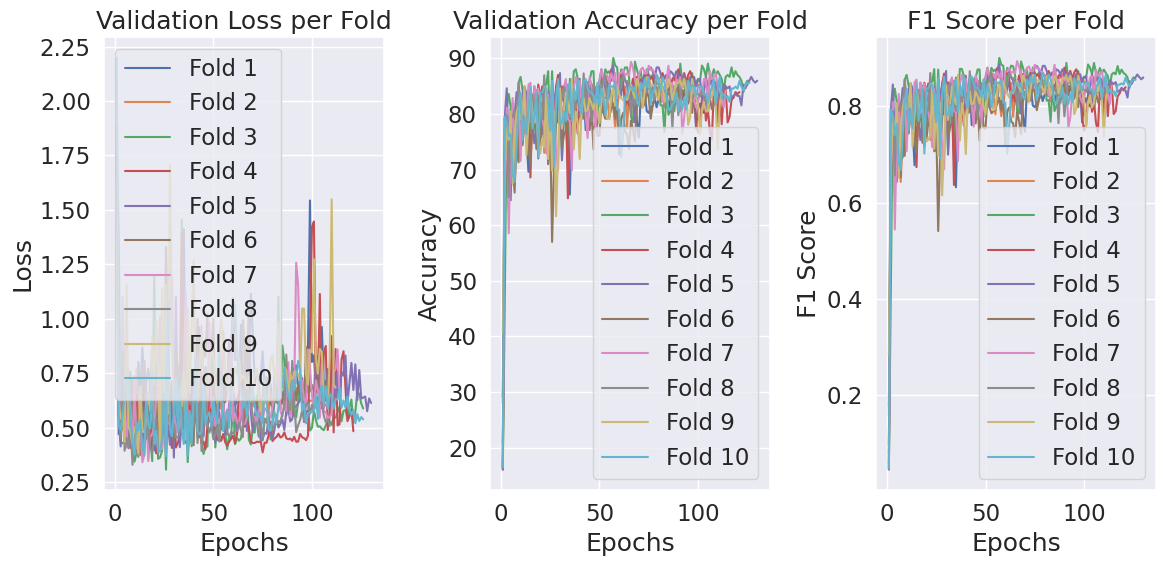

Maximum Fold Accuracy = 86.687306501548
Maximum Fold F1 Score = 0.8661994058773205
Average Fold Accuracy = 83.37461300309596
Average Fold F1 Score = 0.8313160981766311


In [31]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Restnet/SE_fuzz"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/SE_fuzz/best_SE_fuzz.pth"
os.makedirs("./model_Restnet/SE_fuzz", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_SEfuzz.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_SEfuzz(ResidualBlock_SEfuzz, [3, 4, 6, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 224, 224), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=lr0, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEfuzz_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet_SEfuzz(ResidualBlock_SEfuzz, [3, 4, 6, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [32]:
clear_all_memory()

Memory cleared and environment reset!


======================================STAGE2=============================================

Fuzzy mixed pool (replace avg pool) + Restnet34--------------------------------------------------------------------------------------

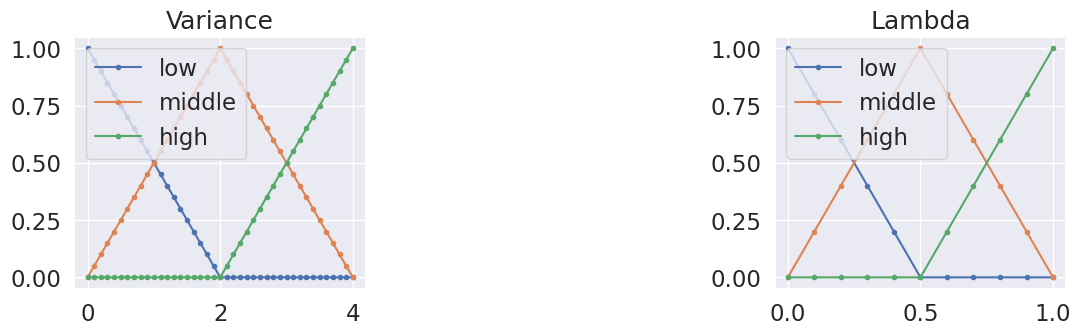

fuzzy_pool_noSE


In [33]:
from Mixedpool_fuzzy_noSE_replaceavg import mixedPool_fuzz

In [34]:
import import_ipynb
from starter_restnet import *
import sys

In [35]:
class ResidualBlock_Fuzz_noSE(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=16):
            super(ResidualBlock_Fuzz_noSE, self).__init__()
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels))
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels
            
        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_Fuzz_noSE(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_Fuzz_noSE, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            #self.avgpool = nn.AvgPool2d(7, stride=1)
            self.fuzzy_pool = mixedPool_fuzz()
            self.fc = nn.Linear(512, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            #x = self.avgpool(x)
            x = self.fuzzy_pool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [36]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 3.68 GMac
Model Params: 21.3 M
Early stopping at epoch 142 due to no improvement in validation loss.


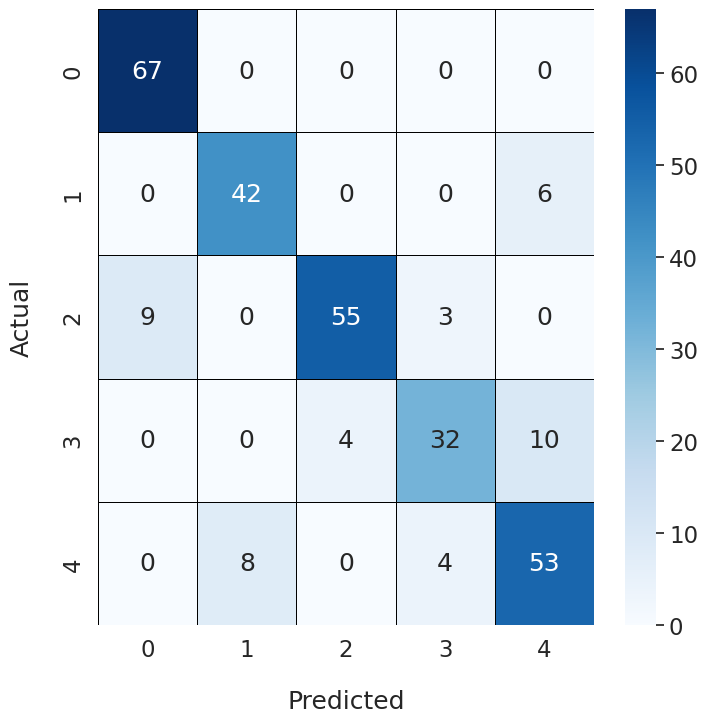

Epoch Training Time: 1128.47 seconds
Test set: Average loss: 0.5687, Accuracy: 273/323 (84.52%), F1 Score: 0.8447

Fold 2
-------
Early stopping at epoch 109 due to no improvement in validation loss.


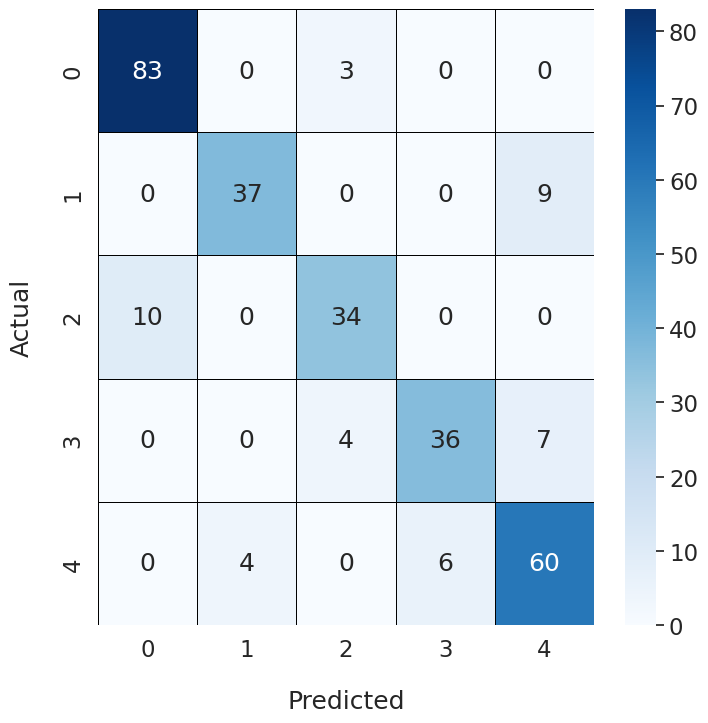

Epoch Training Time: 829.87 seconds
Test set: Average loss: 0.4702, Accuracy: 268/323 (82.97%), F1 Score: 0.8262

Fold 3
-------
Early stopping at epoch 120 due to no improvement in validation loss.


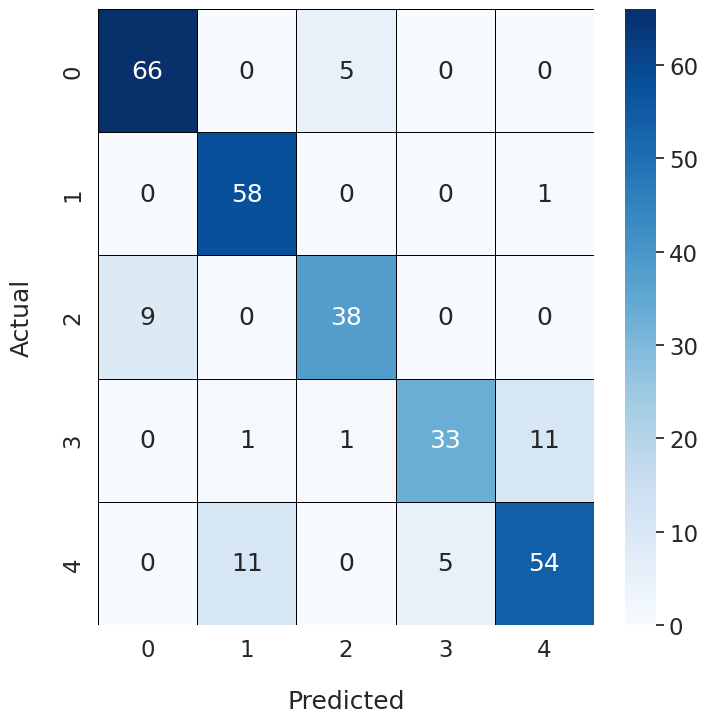

Epoch Training Time: 848.66 seconds
Test set: Average loss: 0.5422, Accuracy: 266/323 (82.35%), F1 Score: 0.8211

Fold 4
-------
Early stopping at epoch 116 due to no improvement in validation loss.


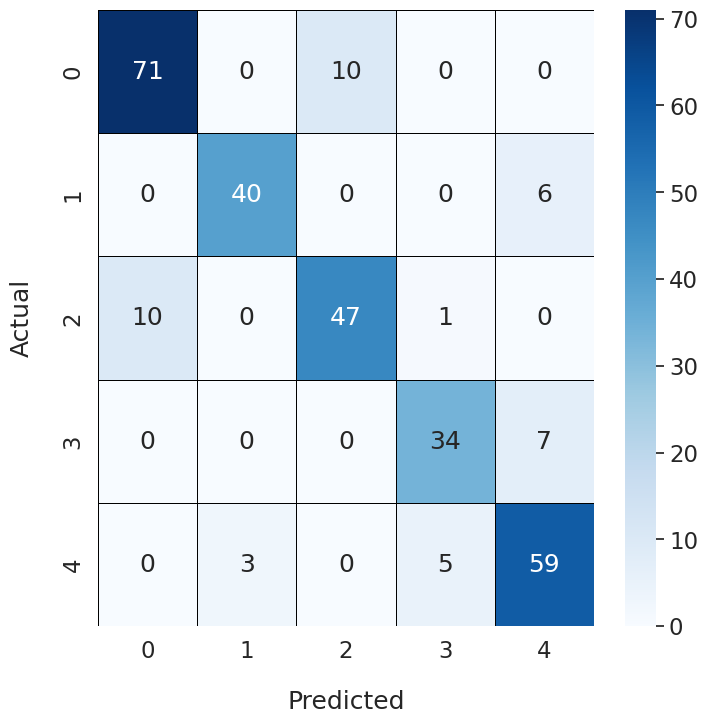

Epoch Training Time: 1064.10 seconds
Test set: Average loss: 0.4711, Accuracy: 267/323 (82.66%), F1 Score: 0.8259

Fold 5
-------
Early stopping at epoch 119 due to no improvement in validation loss.


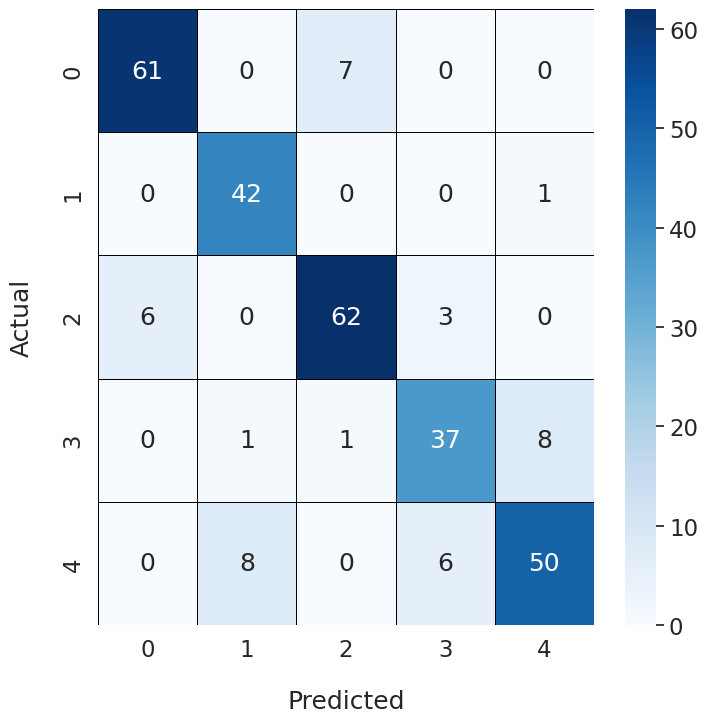

Epoch Training Time: 897.93 seconds
Test set: Average loss: 0.4748, Accuracy: 271/323 (83.90%), F1 Score: 0.8357

Fold 6
-------
Early stopping at epoch 122 due to no improvement in validation loss.


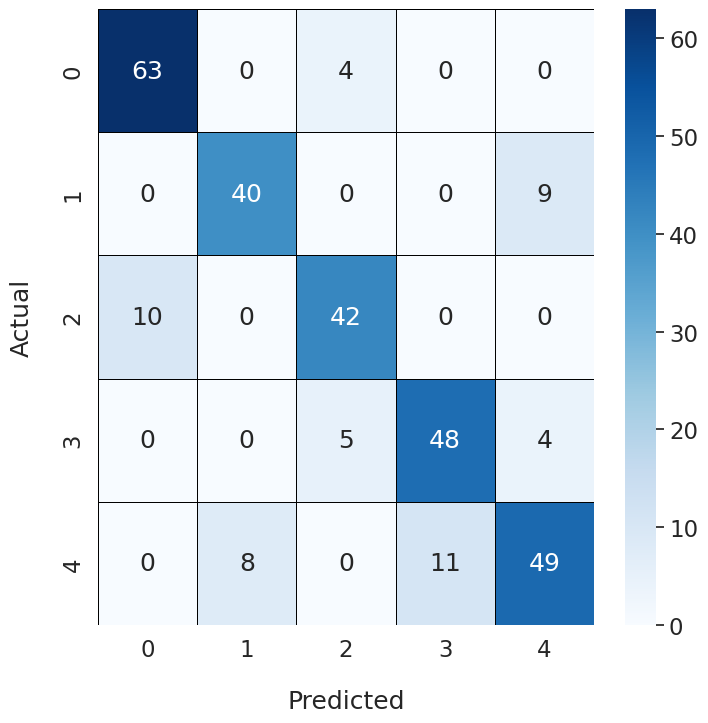

Epoch Training Time: 976.58 seconds
Test set: Average loss: 0.4470, Accuracy: 269/323 (83.28%), F1 Score: 0.8314

Fold 7
-------
Early stopping at epoch 118 due to no improvement in validation loss.


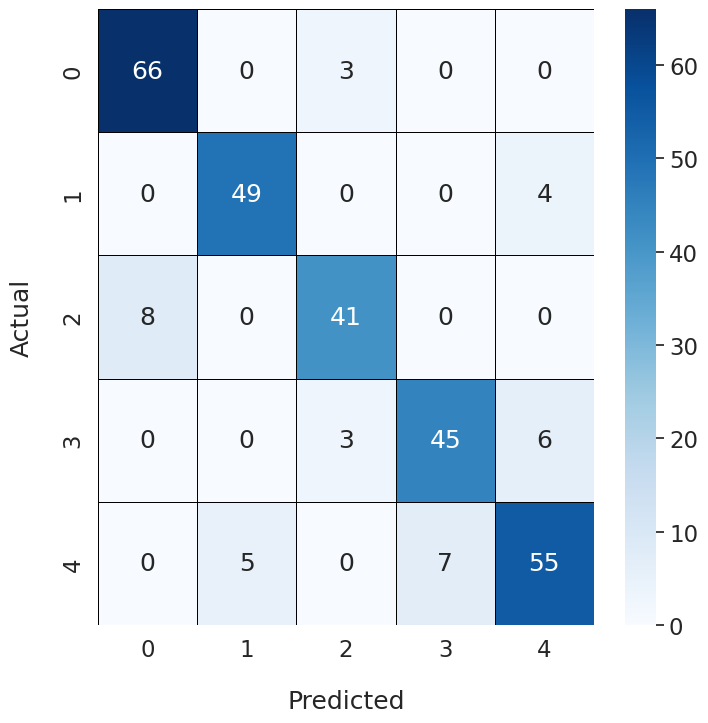

Epoch Training Time: 1024.65 seconds
Test set: Average loss: 0.4597, Accuracy: 272/323 (84.21%), F1 Score: 0.8411

Fold 8
-------
Early stopping at epoch 116 due to no improvement in validation loss.


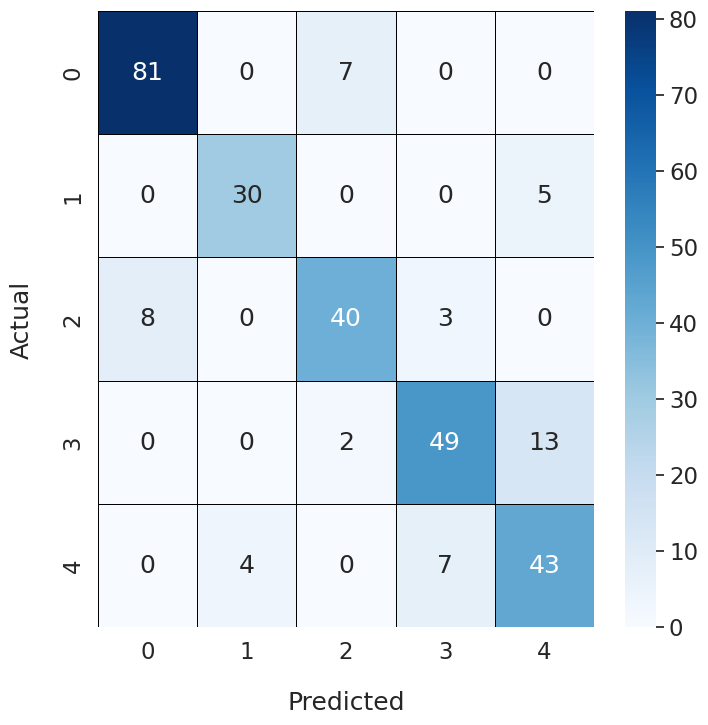

Epoch Training Time: 1093.43 seconds
Test set: Average loss: 0.4624, Accuracy: 268/323 (82.97%), F1 Score: 0.8271

Fold 9
-------
Early stopping at epoch 121 due to no improvement in validation loss.


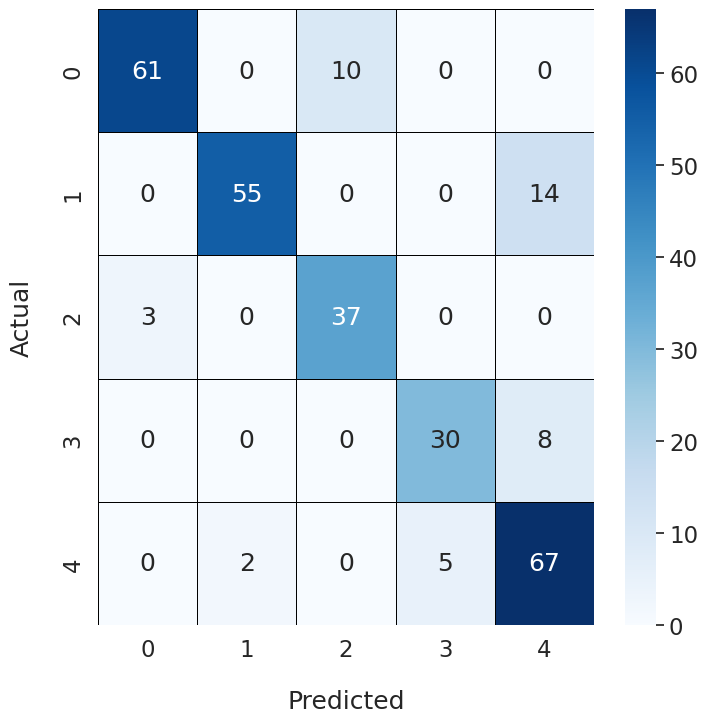

Epoch Training Time: 1086.78 seconds
Test set: Average loss: 0.4753, Accuracy: 265/323 (82.04%), F1 Score: 0.8206

Fold 10
-------
Early stopping at epoch 115 due to no improvement in validation loss.


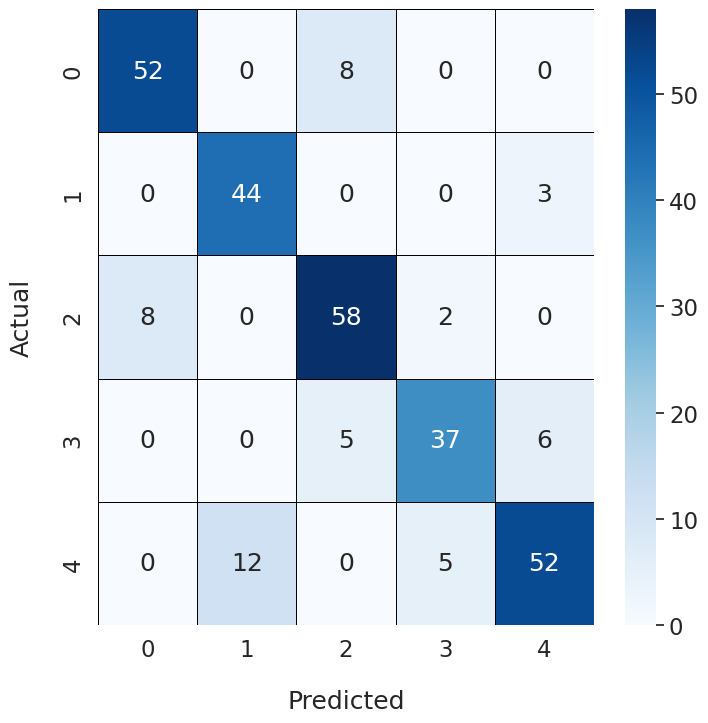

Epoch Training Time: 890.31 seconds
Test set: Average loss: 0.4072, Accuracy: 269/323 (83.28%), F1 Score: 0.8312



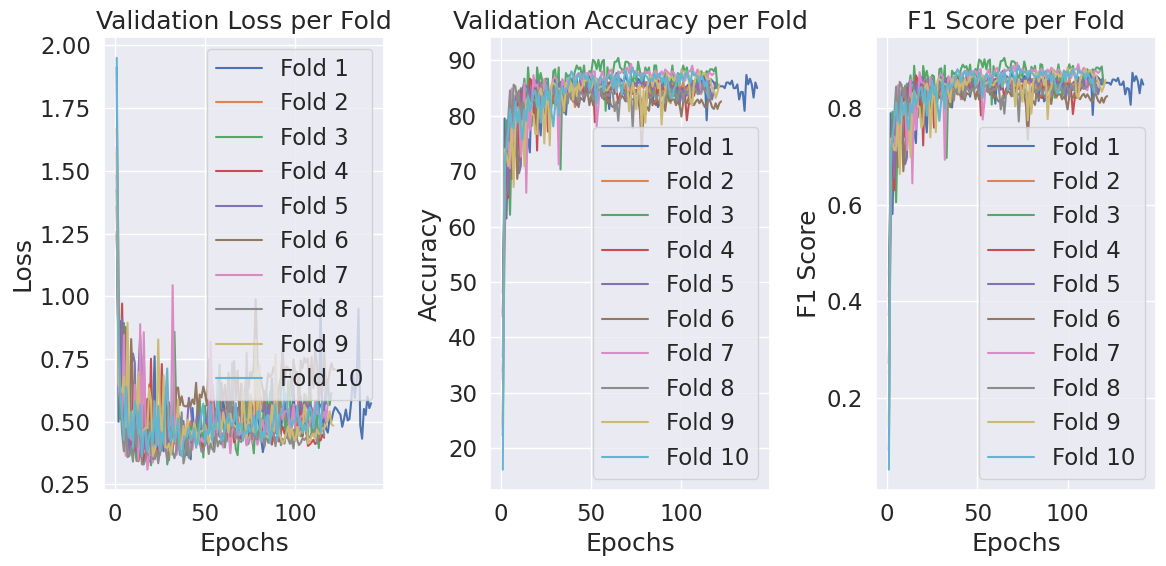

Maximum Fold Accuracy = 84.52012383900929
Maximum Fold F1 Score = 0.8446585755031718
Average Fold Accuracy = 83.21981424148606
Average Fold F1 Score = 0.8304973014362613


In [37]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Restnet/Fuzz_noSE"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/Fuzz_noSE/best_Fuzz_noSE.pth"
os.makedirs("./model_Restnet/Fuzz_noSE", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_Fuzz_noSE.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_Fuzz_noSE(ResidualBlock_Fuzz_noSE, [3, 4, 6, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 224, 224), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=lr0, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEfuzz_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet_Fuzz_noSE(ResidualBlock_Fuzz_noSE, [3, 4, 6, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [38]:
clear_all_memory()

Memory cleared and environment reset!


Mixed pool 0.0 + Restnet34--------------------------------------------------------------------------------------

In [39]:
from Mixedpool00 import mixedPool

alpha = 0.0


In [40]:
import import_ipynb
from starter_restnet import *
import sys

In [41]:
class ResidualBlock_Mixed00_noSE(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=16):
            super(ResidualBlock_Mixed00_noSE, self).__init__()
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels))
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels
            
        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_Mixed00_noSE(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_Mixed00_noSE, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            #self.avgpool = nn.AvgPool2d(7, stride=1)
            self.mixed_pool = mixedPool()
            self.fc = nn.Linear(512, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            #x = self.avgpool(x)
            x = self.mixed_pool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [42]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 3.68 GMac
Model Params: 21.3 M
Early stopping at epoch 117 due to no improvement in validation loss.


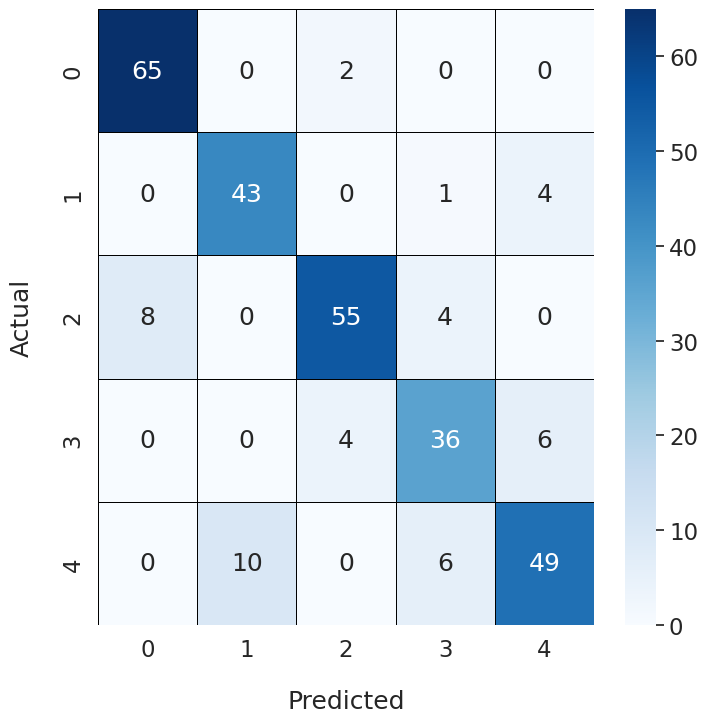

Epoch Training Time: 732.59 seconds
Test set: Average loss: 0.4676, Accuracy: 260/323 (80.50%), F1 Score: 0.8056

Fold 2
-------
Early stopping at epoch 114 due to no improvement in validation loss.


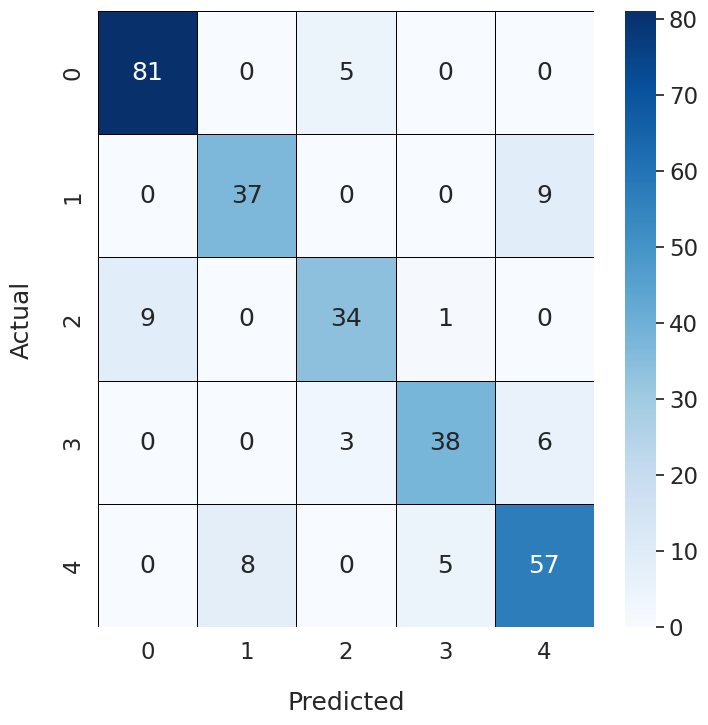

Epoch Training Time: 687.84 seconds
Test set: Average loss: 0.5071, Accuracy: 266/323 (82.35%), F1 Score: 0.8200

Fold 3
-------
Early stopping at epoch 117 due to no improvement in validation loss.


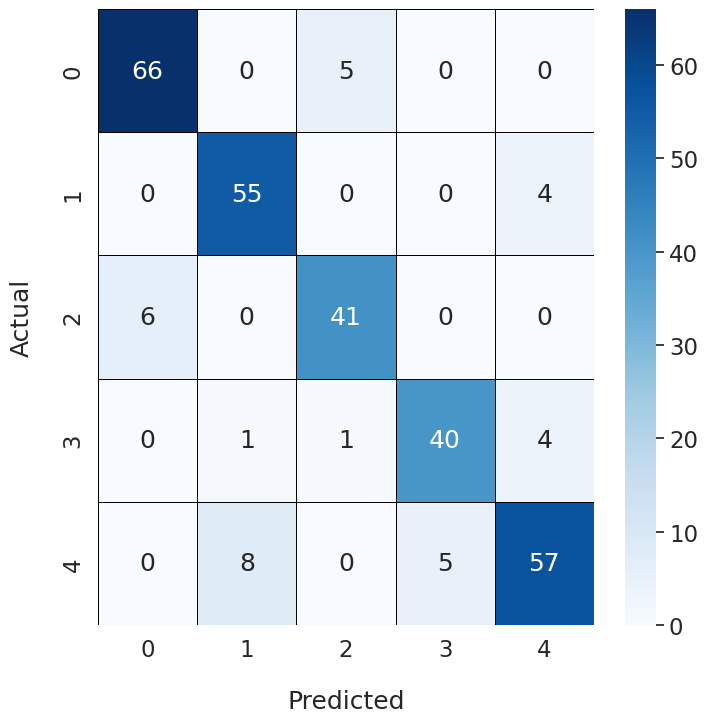

Epoch Training Time: 693.82 seconds
Test set: Average loss: 0.5224, Accuracy: 267/323 (82.66%), F1 Score: 0.8260

Fold 4
-------
Early stopping at epoch 111 due to no improvement in validation loss.


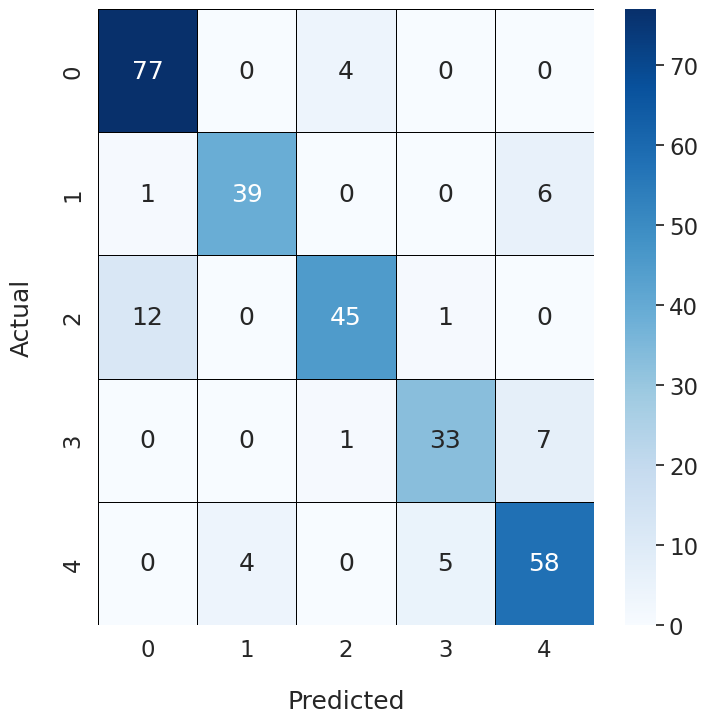

Epoch Training Time: 710.09 seconds
Test set: Average loss: 0.4014, Accuracy: 273/323 (84.52%), F1 Score: 0.8439

Fold 5
-------
Early stopping at epoch 119 due to no improvement in validation loss.


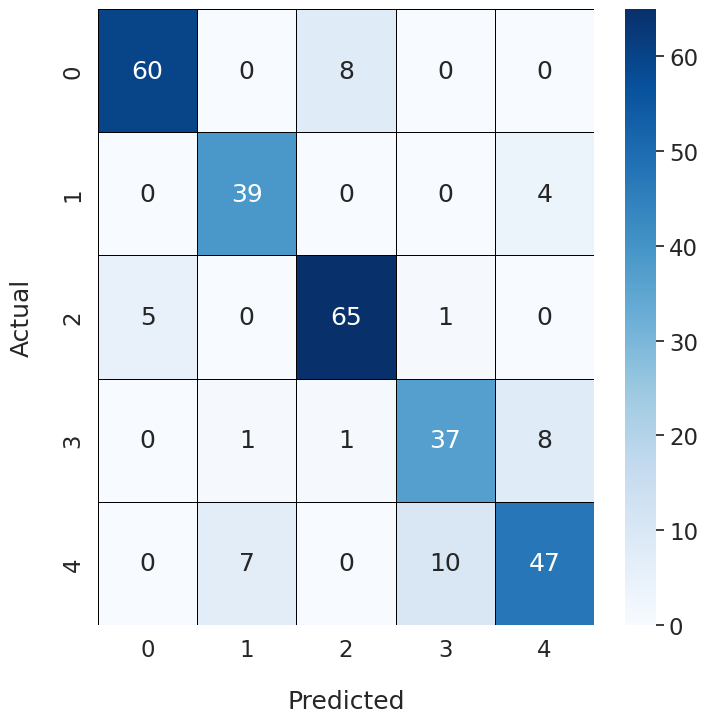

Epoch Training Time: 750.70 seconds
Test set: Average loss: 0.5406, Accuracy: 262/323 (81.11%), F1 Score: 0.8053

Fold 6
-------
Early stopping at epoch 113 due to no improvement in validation loss.


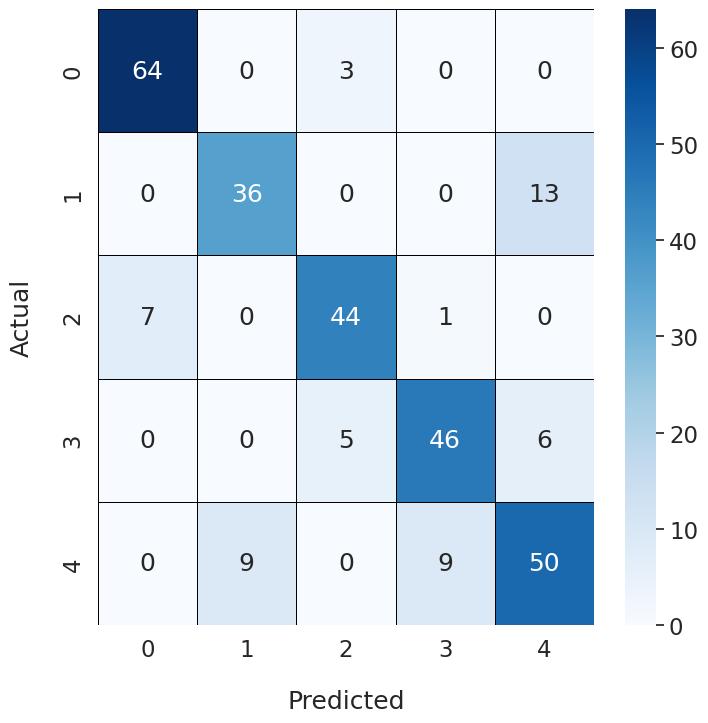

Epoch Training Time: 736.65 seconds
Test set: Average loss: 0.4034, Accuracy: 270/323 (83.59%), F1 Score: 0.8346

Fold 7
-------
Early stopping at epoch 111 due to no improvement in validation loss.


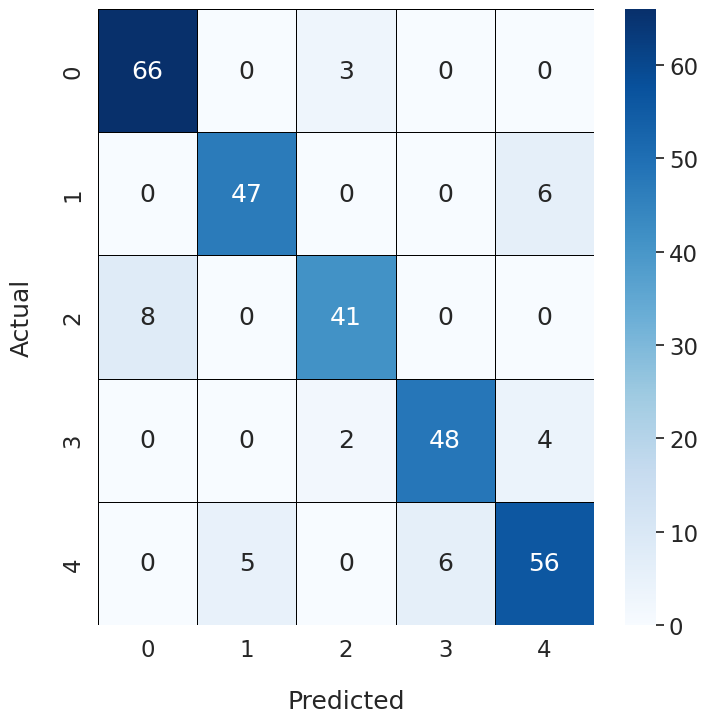

Epoch Training Time: 671.69 seconds
Test set: Average loss: 0.3781, Accuracy: 274/323 (84.83%), F1 Score: 0.8466

Fold 8
-------
Early stopping at epoch 114 due to no improvement in validation loss.


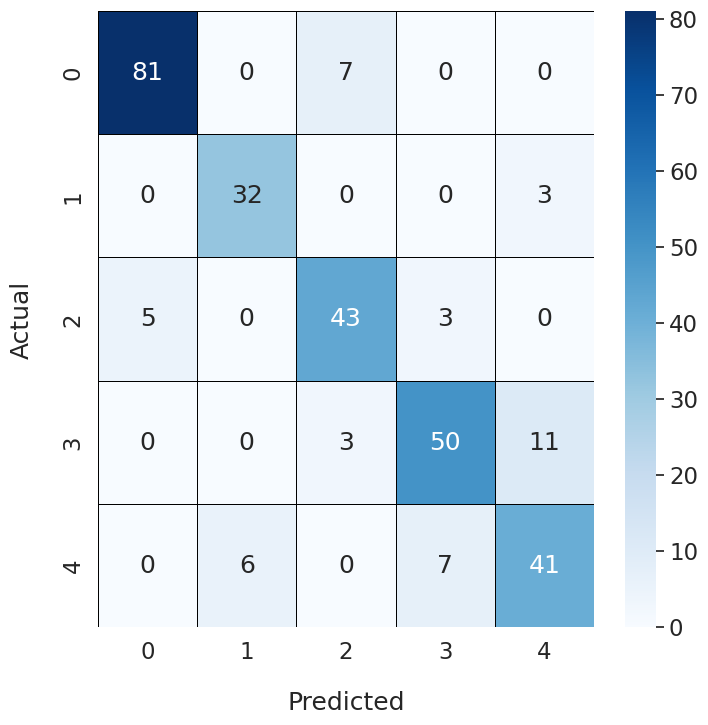

Epoch Training Time: 701.77 seconds
Test set: Average loss: 0.5426, Accuracy: 261/323 (80.80%), F1 Score: 0.8013

Fold 9
-------
Early stopping at epoch 113 due to no improvement in validation loss.


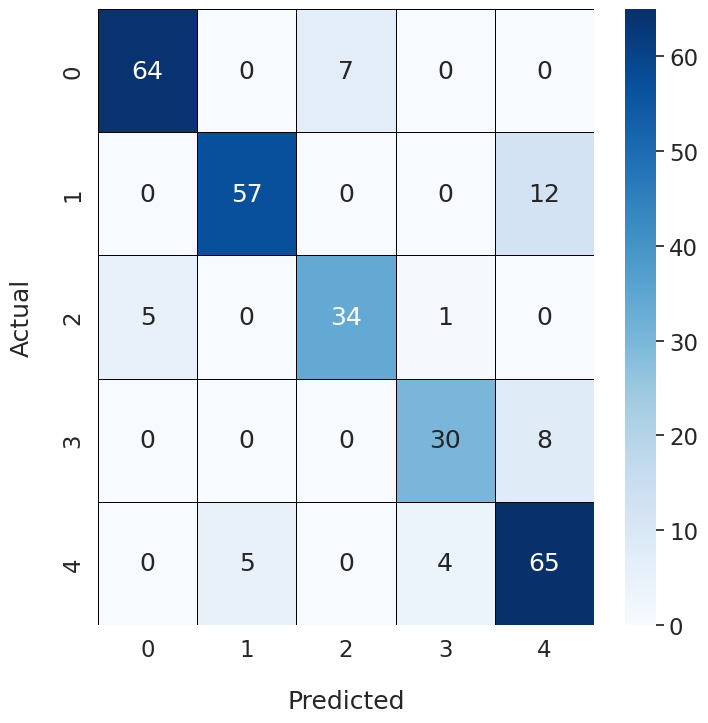

Epoch Training Time: 639.57 seconds
Test set: Average loss: 0.4706, Accuracy: 263/323 (81.42%), F1 Score: 0.8087

Fold 10
-------
Early stopping at epoch 114 due to no improvement in validation loss.


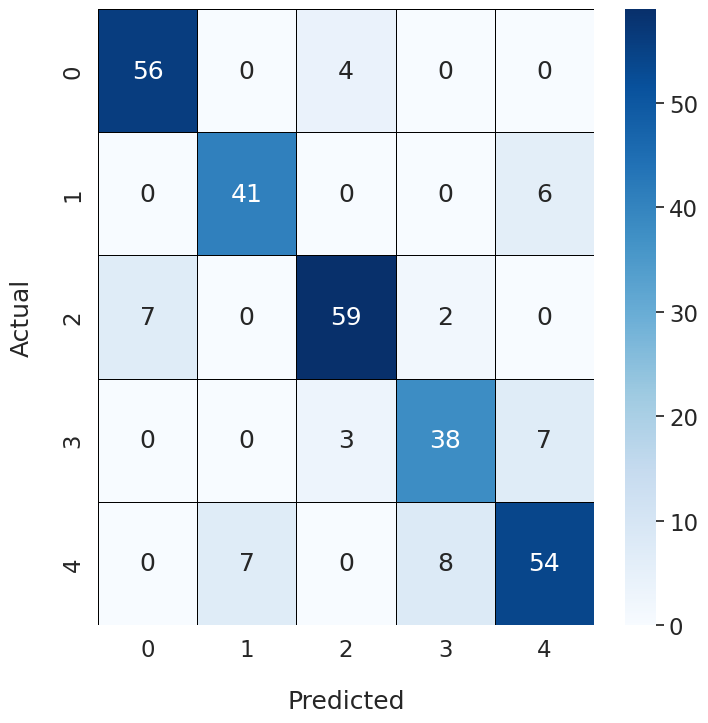

Epoch Training Time: 709.34 seconds
Test set: Average loss: 0.4495, Accuracy: 262/323 (81.11%), F1 Score: 0.8118



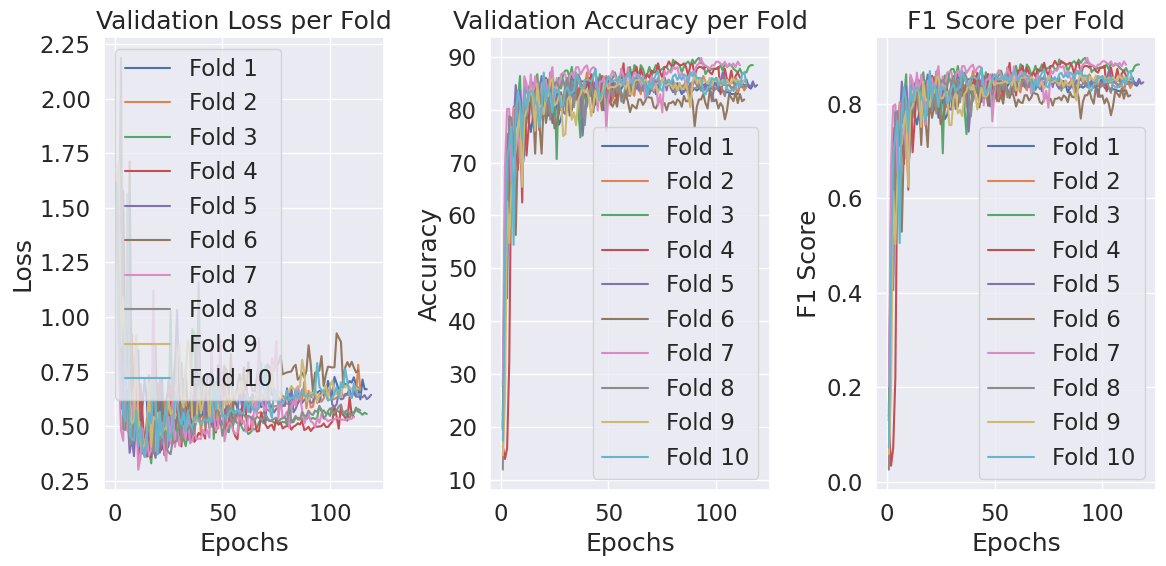

Maximum Fold Accuracy = 84.82972136222911
Maximum Fold F1 Score = 0.8465731194305436
Average Fold Accuracy = 82.29102167182663
Average Fold F1 Score = 0.8203865522859676


In [43]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Restnet/Mixed0.0_noSE"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/Mixed0.0_noSE/best_Mixed0.0_noSE.pth"
os.makedirs("./model_Restnet/Mixed0.0_noSE", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_Mixed0.0_noSE.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_Mixed00_noSE(ResidualBlock_Mixed00_noSE, [3, 4, 6, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 224, 224), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=lr0, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEfuzz_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet_Mixed00_noSE(ResidualBlock_Mixed00_noSE, [3, 4, 6, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [44]:
clear_all_memory()

Memory cleared and environment reset!


Mixed pool 0.3 + Restnet34--------------------------------------------------------------------------------------

In [45]:
from Mixedpool03 import mixedPool

alpha = 0.3


In [46]:
import import_ipynb
from starter_restnet import *
import sys

In [47]:
class ResidualBlock_Mixed03_noSE(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=16):
            super(ResidualBlock_Mixed03_noSE, self).__init__()
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels))
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels
            
        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_Mixed03_noSE(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_Mixed03_noSE, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            #self.avgpool = nn.AvgPool2d(7, stride=1)
            self.mixed_pool = mixedPool()
            self.fc = nn.Linear(512, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            #x = self.avgpool(x)
            x = self.mixed_pool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [48]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 3.68 GMac
Model Params: 21.3 M
Early stopping at epoch 107 due to no improvement in validation loss.


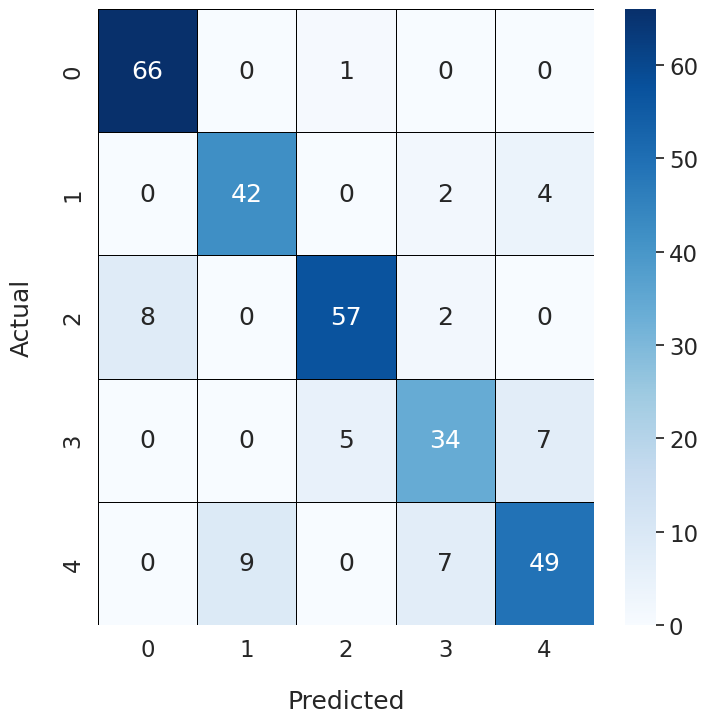

Epoch Training Time: 672.38 seconds
Test set: Average loss: 0.4427, Accuracy: 259/323 (80.19%), F1 Score: 0.8008

Fold 2
-------
Early stopping at epoch 117 due to no improvement in validation loss.


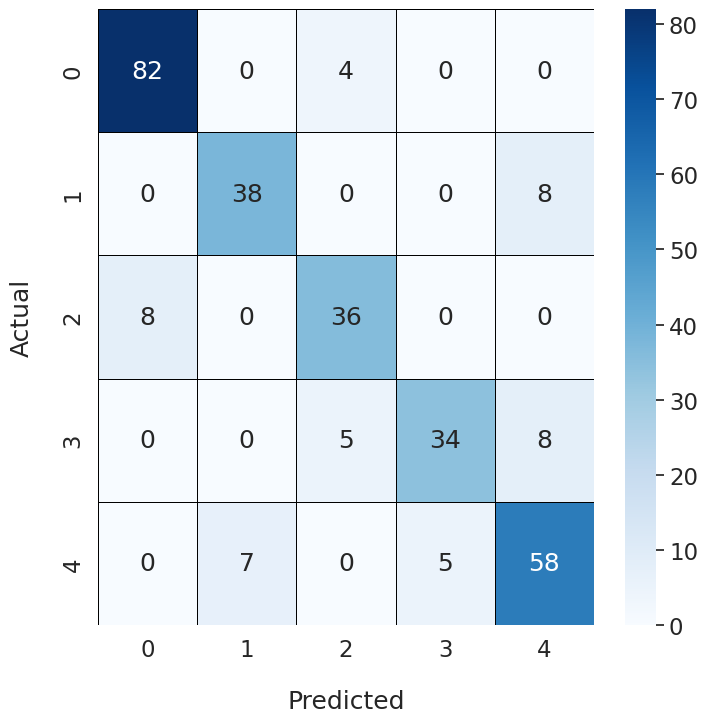

Epoch Training Time: 716.82 seconds
Test set: Average loss: 0.5138, Accuracy: 267/323 (82.66%), F1 Score: 0.8243

Fold 3
-------
Early stopping at epoch 105 due to no improvement in validation loss.


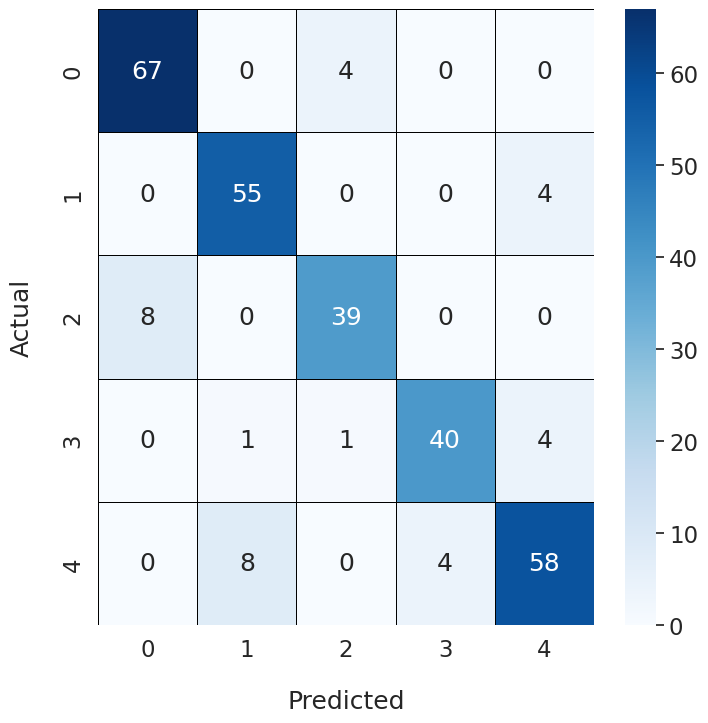

Epoch Training Time: 662.38 seconds
Test set: Average loss: 0.4568, Accuracy: 260/323 (80.50%), F1 Score: 0.8051

Fold 4
-------
Early stopping at epoch 116 due to no improvement in validation loss.


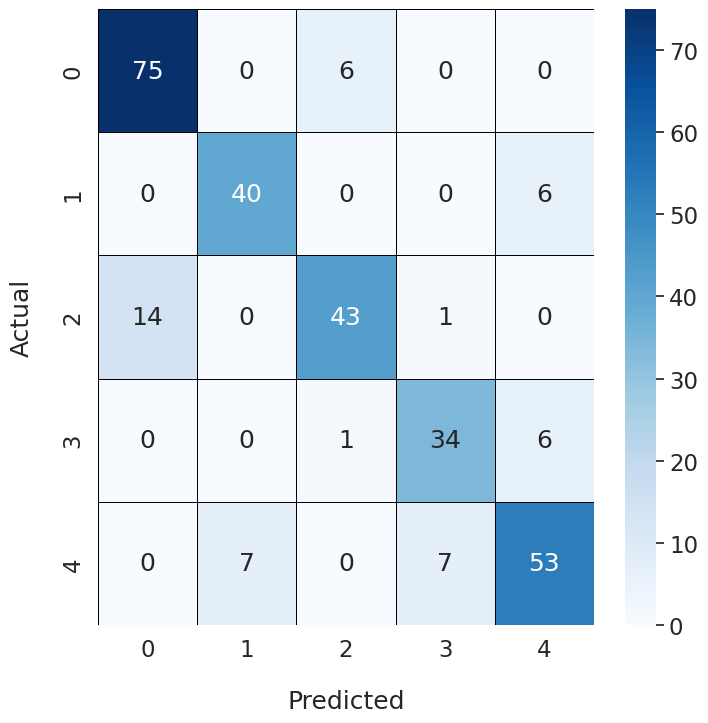

Epoch Training Time: 682.07 seconds
Test set: Average loss: 0.4789, Accuracy: 259/323 (80.19%), F1 Score: 0.8001

Fold 5
-------
Early stopping at epoch 113 due to no improvement in validation loss.


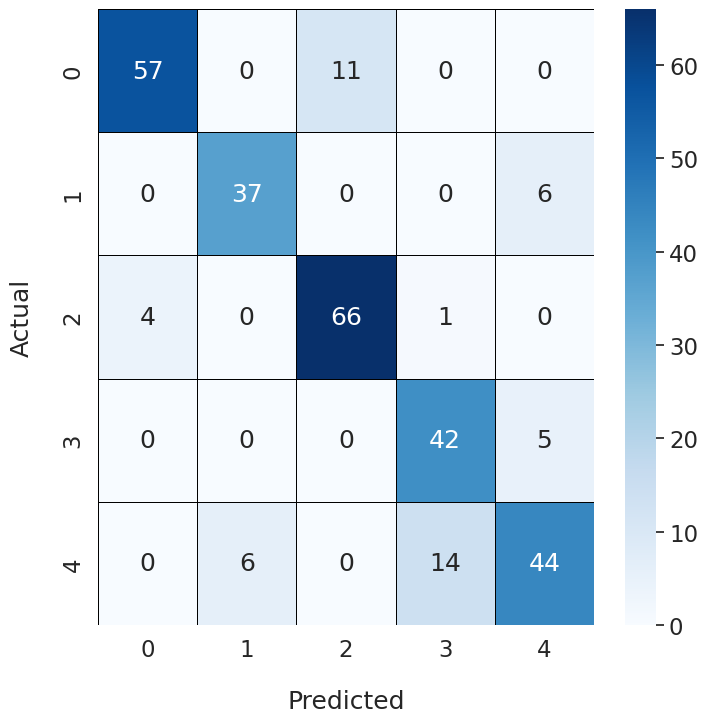

Epoch Training Time: 723.14 seconds
Test set: Average loss: 0.4494, Accuracy: 261/323 (80.80%), F1 Score: 0.8023

Fold 6
-------
Early stopping at epoch 113 due to no improvement in validation loss.


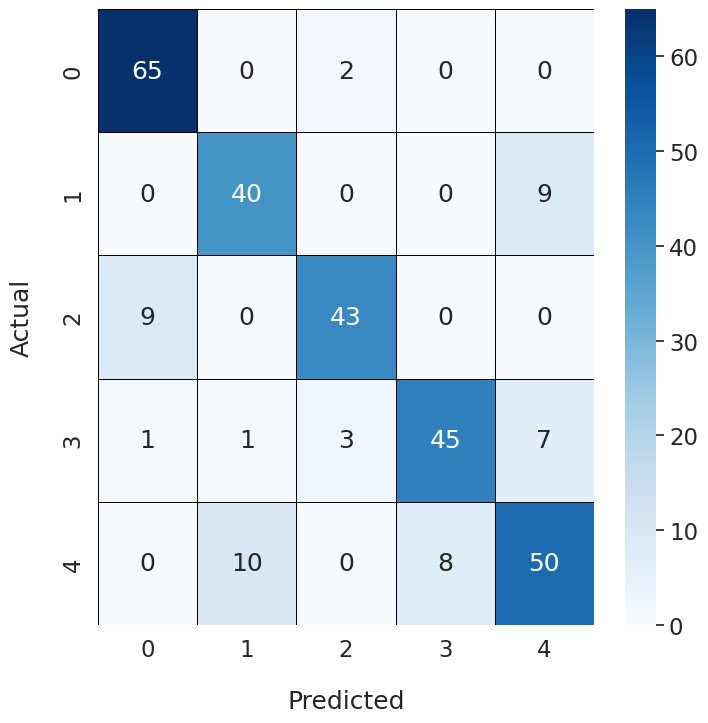

Epoch Training Time: 722.95 seconds
Test set: Average loss: 0.4886, Accuracy: 270/323 (83.59%), F1 Score: 0.8325

Fold 7
-------
Early stopping at epoch 108 due to no improvement in validation loss.


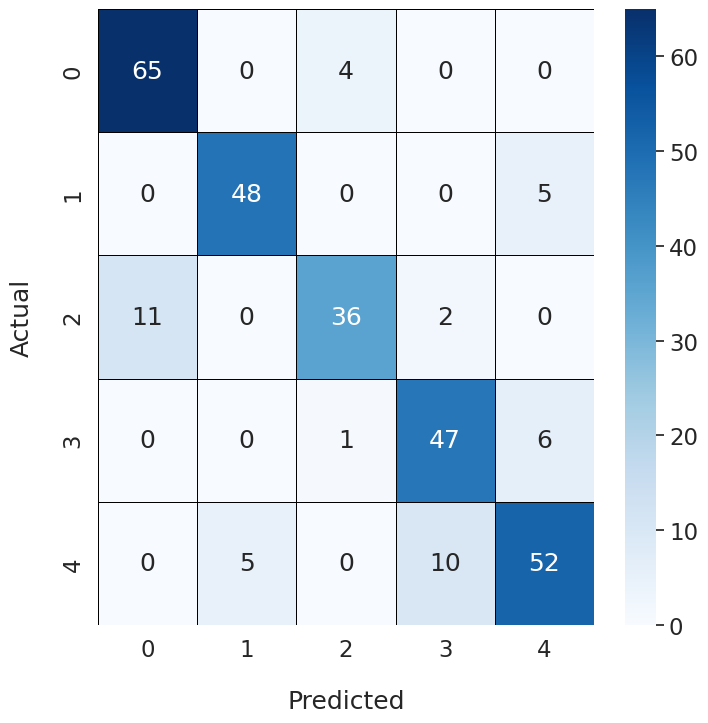

Epoch Training Time: 660.29 seconds
Test set: Average loss: 0.4591, Accuracy: 264/323 (81.73%), F1 Score: 0.8140

Fold 8
-------
Early stopping at epoch 112 due to no improvement in validation loss.


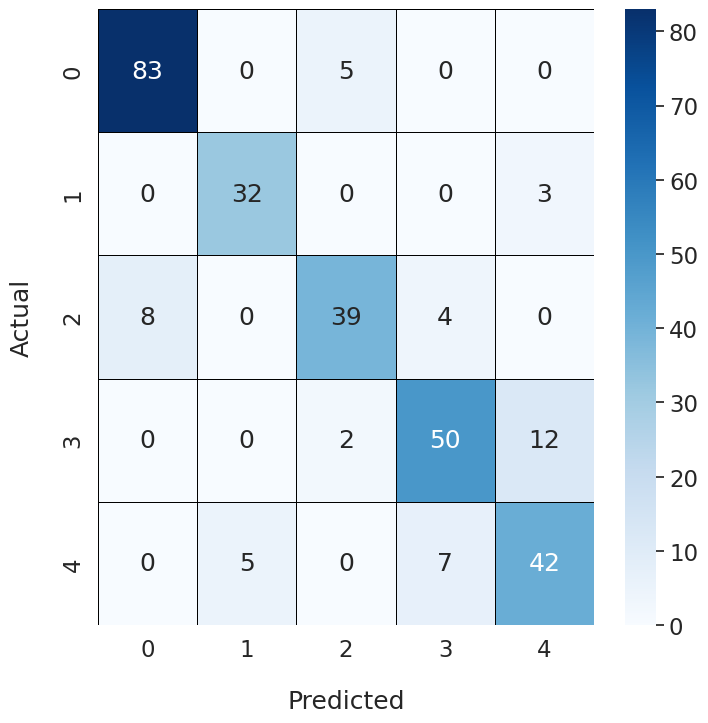

Epoch Training Time: 691.17 seconds
Test set: Average loss: 0.5180, Accuracy: 260/323 (80.50%), F1 Score: 0.8028

Fold 9
-------
Early stopping at epoch 115 due to no improvement in validation loss.


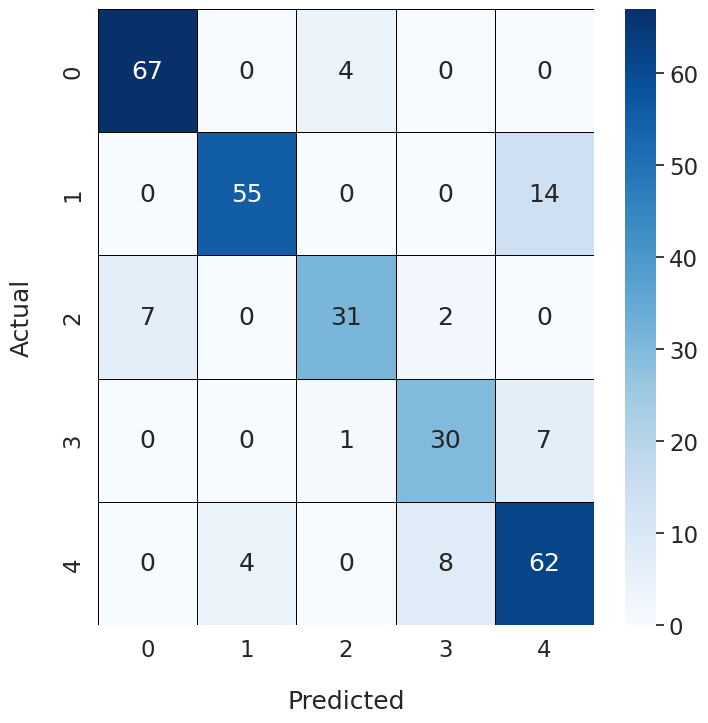

Epoch Training Time: 682.46 seconds
Test set: Average loss: 0.5125, Accuracy: 265/323 (82.04%), F1 Score: 0.8157

Fold 10
-------
Early stopping at epoch 121 due to no improvement in validation loss.


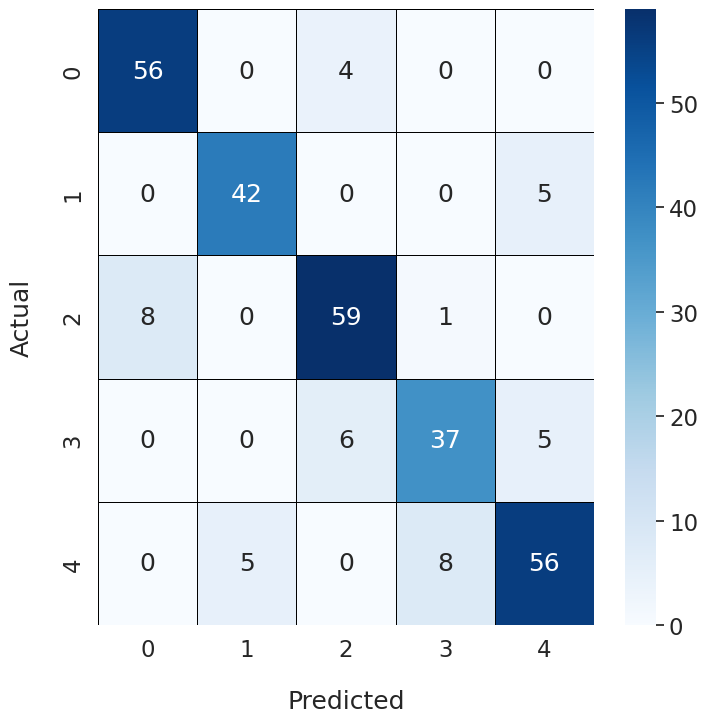

Epoch Training Time: 733.59 seconds
Test set: Average loss: 0.5241, Accuracy: 268/323 (82.97%), F1 Score: 0.8282



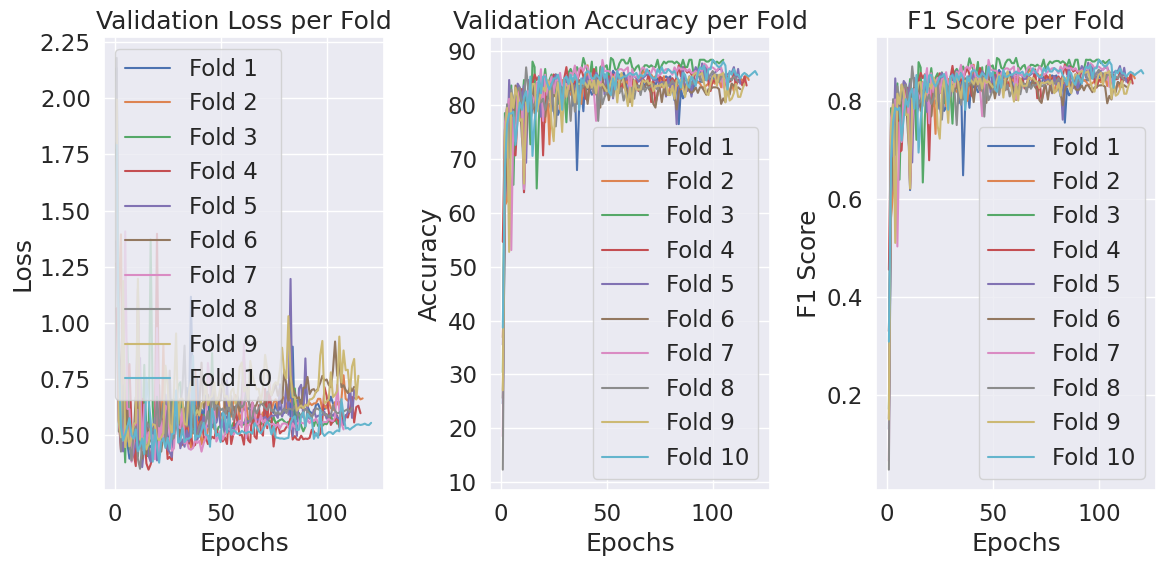

Maximum Fold Accuracy = 83.59133126934985
Maximum Fold F1 Score = 0.8325011763582529
Average Fold Accuracy = 81.51702786377709
Average Fold F1 Score = 0.8125863663510039


In [49]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Restnet/Mixed0.3_noSE"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/Mixed0.3_noSE/best_Mixed0.3_noSE.pth"
os.makedirs("./model_Restnet/Mixed0.3_noSE", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_Mixed0.3_noSE.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_Mixed03_noSE(ResidualBlock_Mixed03_noSE, [3, 4, 6, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 224, 224), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=lr0, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEfuzz_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet_Mixed03_noSE(ResidualBlock_Mixed03_noSE, [3, 4, 6, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [50]:
clear_all_memory()

Memory cleared and environment reset!


Mixed pool 0.5 + Restnet34--------------------------------------------------------------------------------------

In [51]:
from Mixedpool05 import mixedPool

In [52]:
import import_ipynb
from starter_restnet import *
import sys

In [53]:
class ResidualBlock_Mixed05_noSE(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=16):
            super(ResidualBlock_Mixed05_noSE, self).__init__()
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels))
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels
            
        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_Mixed05_noSE(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_Mixed05_noSE, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            #self.avgpool = nn.AvgPool2d(7, stride=1)
            self.mixed_pool = mixedPool()
            self.fc = nn.Linear(512, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            #x = self.avgpool(x)
            x = self.mixed_pool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [54]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 3.68 GMac
Model Params: 21.3 M
Early stopping at epoch 106 due to no improvement in validation loss.


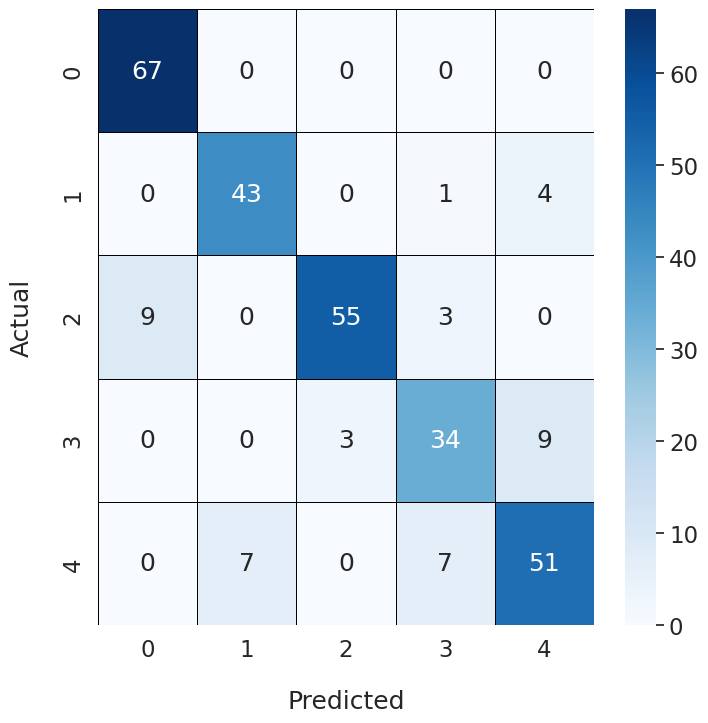

Epoch Training Time: 627.57 seconds
Test set: Average loss: 0.4337, Accuracy: 269/323 (83.28%), F1 Score: 0.8325

Fold 2
-------
Early stopping at epoch 106 due to no improvement in validation loss.


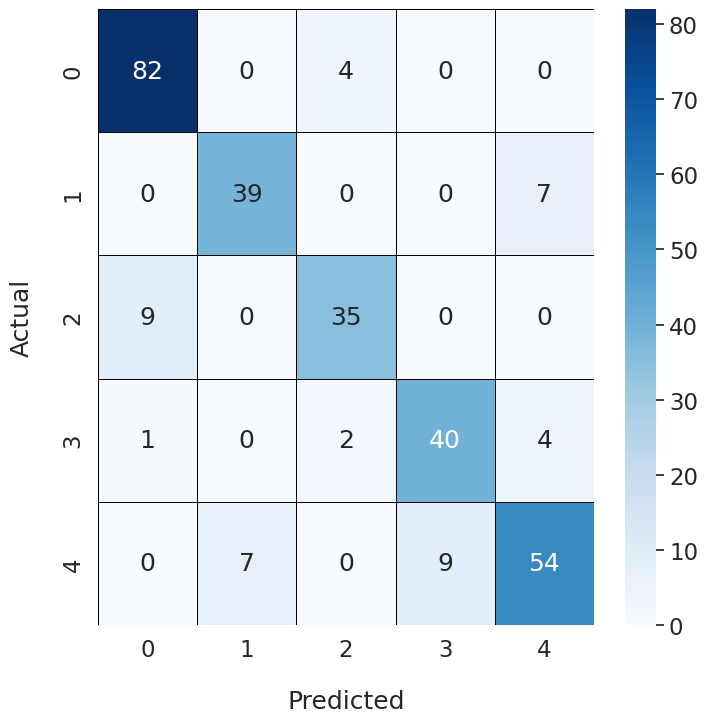

Epoch Training Time: 661.35 seconds
Test set: Average loss: 0.4221, Accuracy: 269/323 (83.28%), F1 Score: 0.8307

Fold 3
-------
Early stopping at epoch 107 due to no improvement in validation loss.


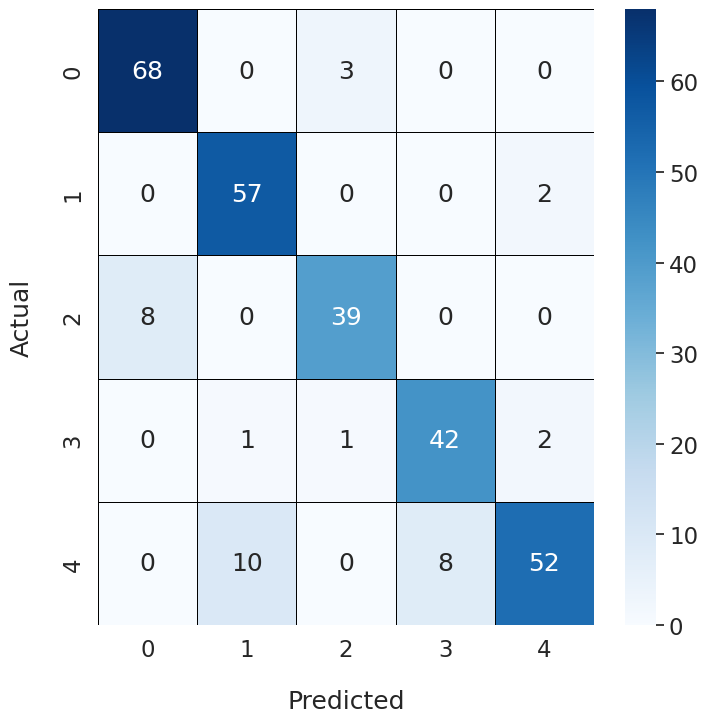

Epoch Training Time: 656.84 seconds
Test set: Average loss: 0.4279, Accuracy: 270/323 (83.59%), F1 Score: 0.8357

Fold 4
-------
Early stopping at epoch 115 due to no improvement in validation loss.


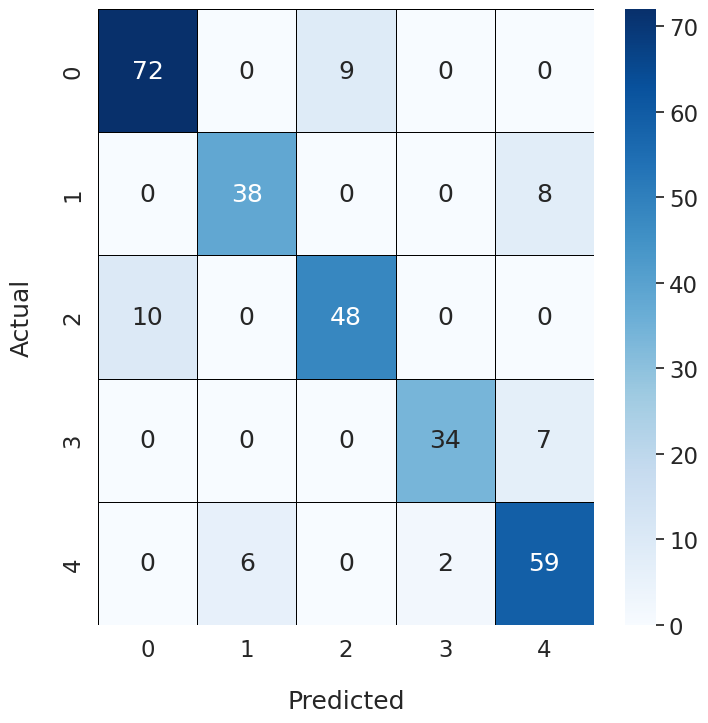

Epoch Training Time: 678.74 seconds
Test set: Average loss: 0.5330, Accuracy: 263/323 (81.42%), F1 Score: 0.8115

Fold 5
-------
Early stopping at epoch 108 due to no improvement in validation loss.


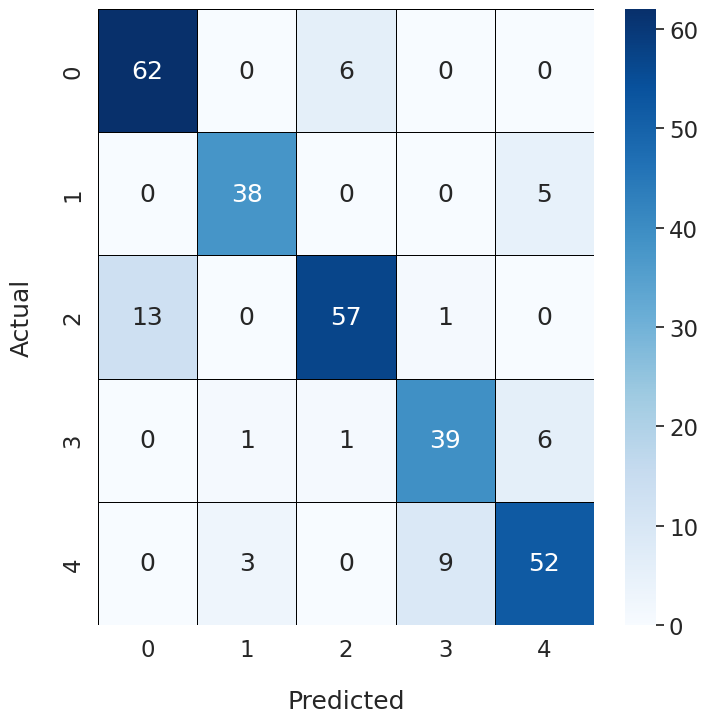

Epoch Training Time: 679.60 seconds
Test set: Average loss: 0.4403, Accuracy: 266/323 (82.35%), F1 Score: 0.8204

Fold 6
-------
Early stopping at epoch 112 due to no improvement in validation loss.


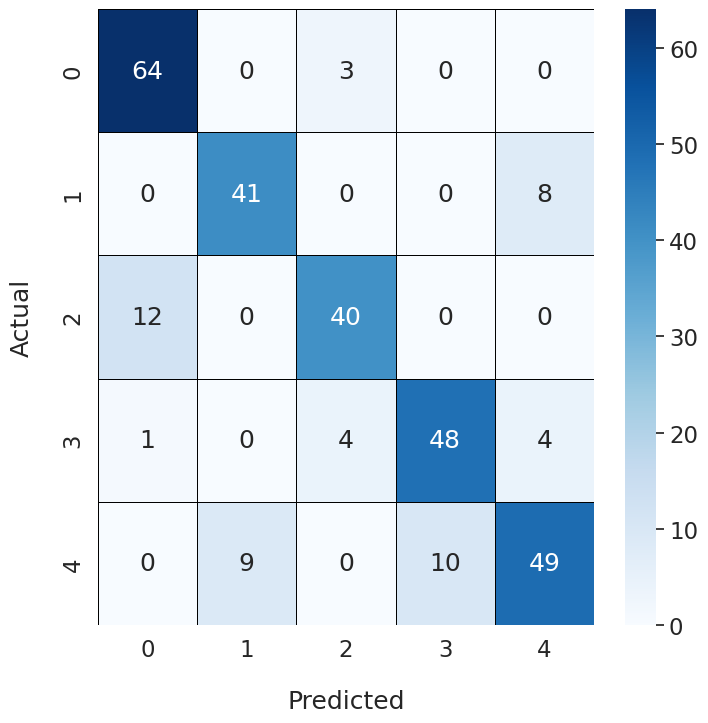

Epoch Training Time: 720.23 seconds
Test set: Average loss: 0.4688, Accuracy: 265/323 (82.04%), F1 Score: 0.8187

Fold 7
-------
Early stopping at epoch 110 due to no improvement in validation loss.


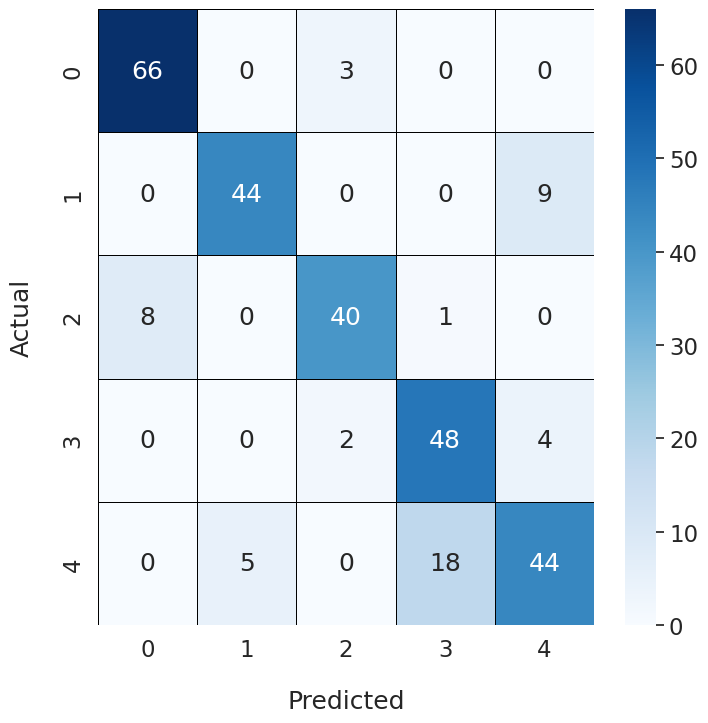

Epoch Training Time: 739.44 seconds
Test set: Average loss: 0.4797, Accuracy: 267/323 (82.66%), F1 Score: 0.8239

Fold 8
-------
Early stopping at epoch 107 due to no improvement in validation loss.


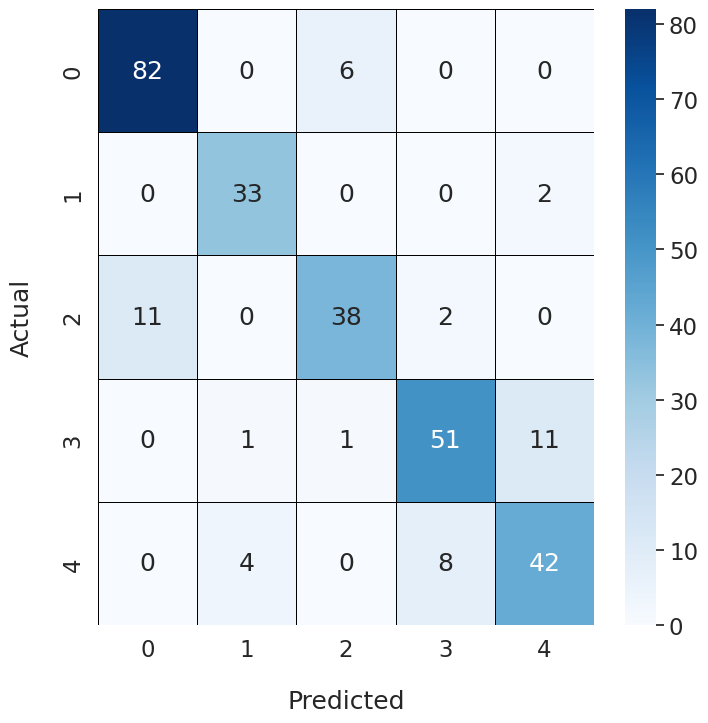

Epoch Training Time: 659.93 seconds
Test set: Average loss: 0.4531, Accuracy: 261/323 (80.80%), F1 Score: 0.8062

Fold 9
-------
Early stopping at epoch 107 due to no improvement in validation loss.


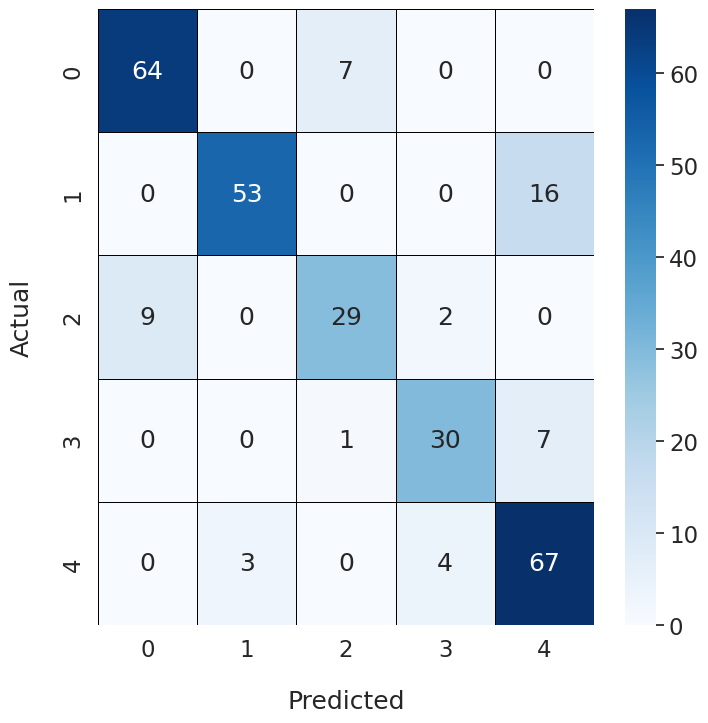

Epoch Training Time: 641.49 seconds
Test set: Average loss: 0.4520, Accuracy: 264/323 (81.73%), F1 Score: 0.8134

Fold 10
-------
Early stopping at epoch 109 due to no improvement in validation loss.


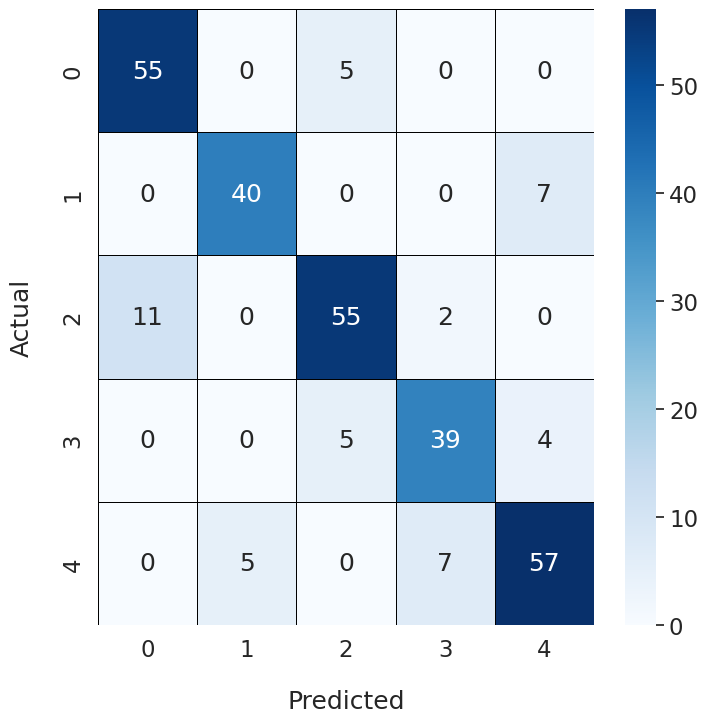

Epoch Training Time: 656.68 seconds
Test set: Average loss: 0.4224, Accuracy: 268/323 (82.97%), F1 Score: 0.8299



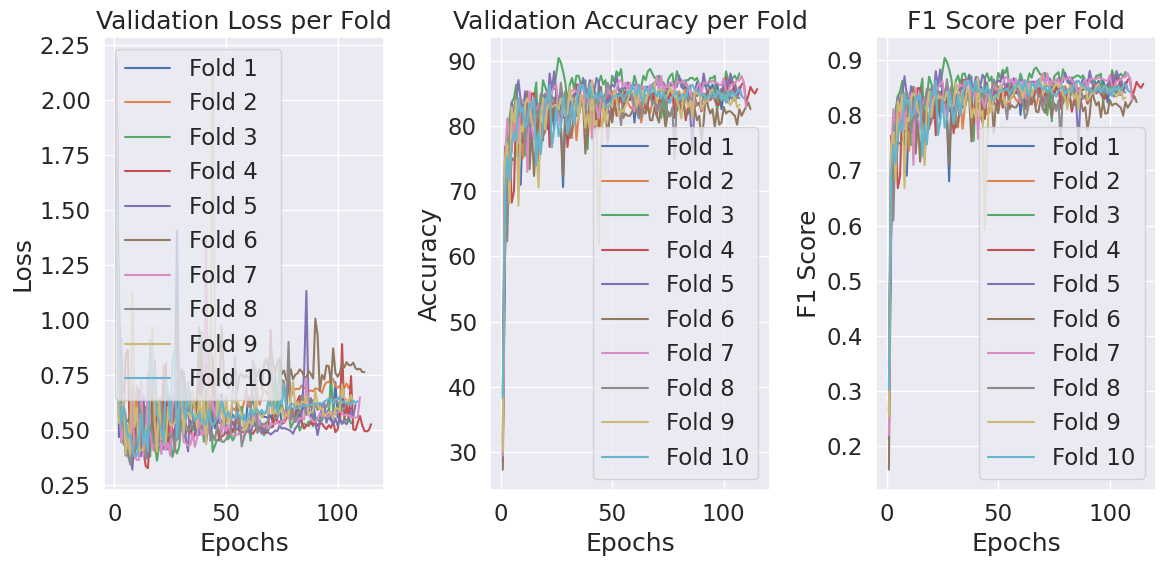

Maximum Fold Accuracy = 83.59133126934985
Maximum Fold F1 Score = 0.8357053358537994
Average Fold Accuracy = 82.41486068111456
Average Fold F1 Score = 0.8222933983379728


In [55]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Restnet/Mixed0.5_noSE"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/Mixed0.5_noSE/best_Mixed0.5_noSE.pth"
os.makedirs("./model_Restnet/Mixed0.5_noSE", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_Mixed0.5_noSE.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_Mixed05_noSE(ResidualBlock_Mixed05_noSE, [3, 4, 6, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 224, 224), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=lr0, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEfuzz_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet_Mixed05_noSE(ResidualBlock_Mixed05_noSE, [3, 4, 6, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [56]:
clear_all_memory()

Memory cleared and environment reset!


Mixed pool 0.75 + Restnet34--------------------------------------------------------------------------------------

In [57]:
from Mixedpool075 import mixedPool

alpha = 0.75


In [58]:
import import_ipynb
from starter_restnet import *
import sys

In [59]:
class ResidualBlock_Mixed075_noSE(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=16):
            super(ResidualBlock_Mixed075_noSE, self).__init__()
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels))
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels
            
        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_Mixed075_noSE(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_Mixed075_noSE, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            #self.avgpool = nn.AvgPool2d(7, stride=1)
            self.mixed_pool = mixedPool()
            self.fc = nn.Linear(512, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            #x = self.avgpool(x)
            x = self.mixed_pool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [60]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 3.68 GMac
Model Params: 21.3 M
Early stopping at epoch 112 due to no improvement in validation loss.


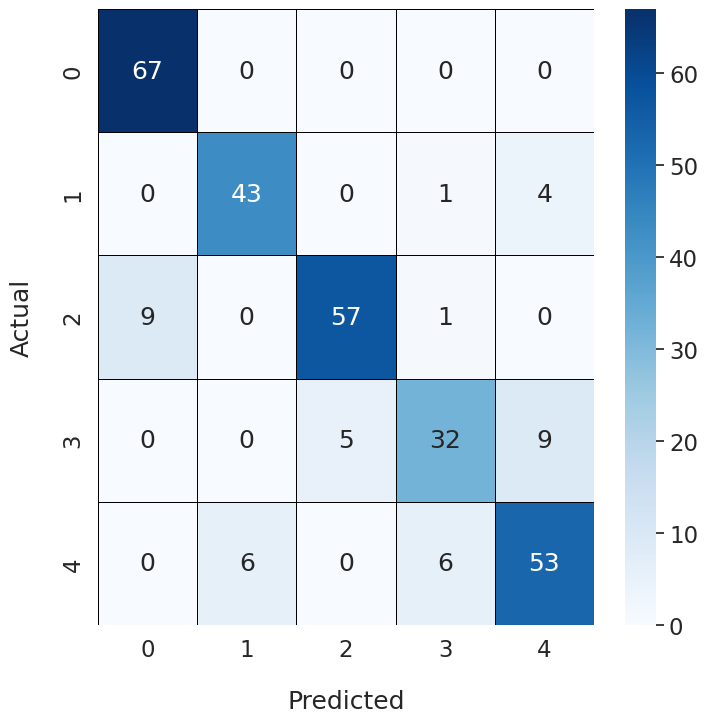

Epoch Training Time: 721.99 seconds
Test set: Average loss: 0.4290, Accuracy: 270/323 (83.59%), F1 Score: 0.8346

Fold 2
-------
Early stopping at epoch 113 due to no improvement in validation loss.


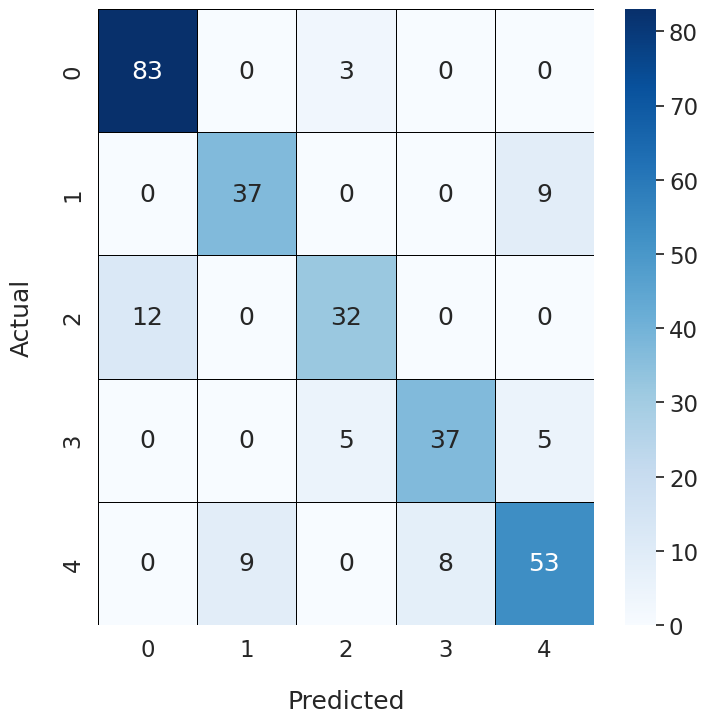

Epoch Training Time: 738.03 seconds
Test set: Average loss: 0.4852, Accuracy: 268/323 (82.97%), F1 Score: 0.8289

Fold 3
-------
Early stopping at epoch 114 due to no improvement in validation loss.


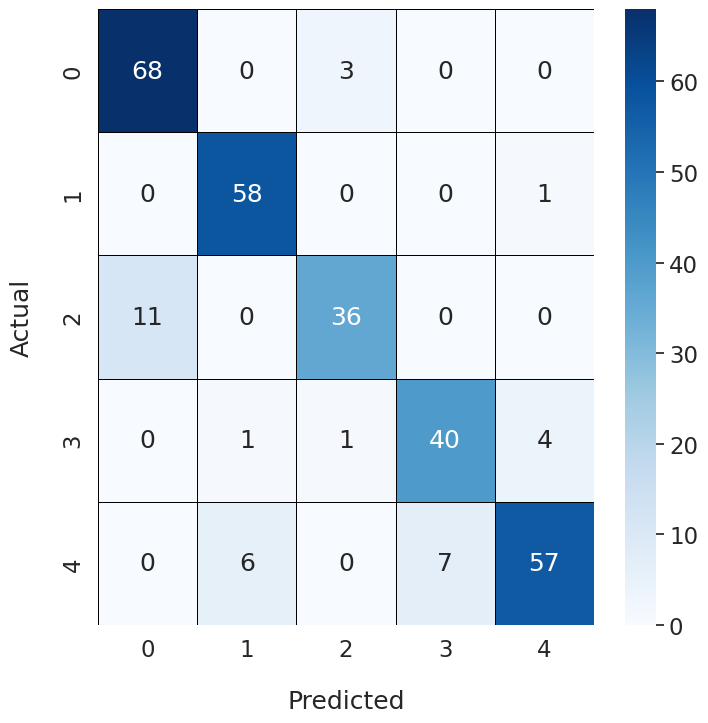

Epoch Training Time: 680.01 seconds
Test set: Average loss: 0.5207, Accuracy: 261/323 (80.80%), F1 Score: 0.8038

Fold 4
-------
Early stopping at epoch 108 due to no improvement in validation loss.


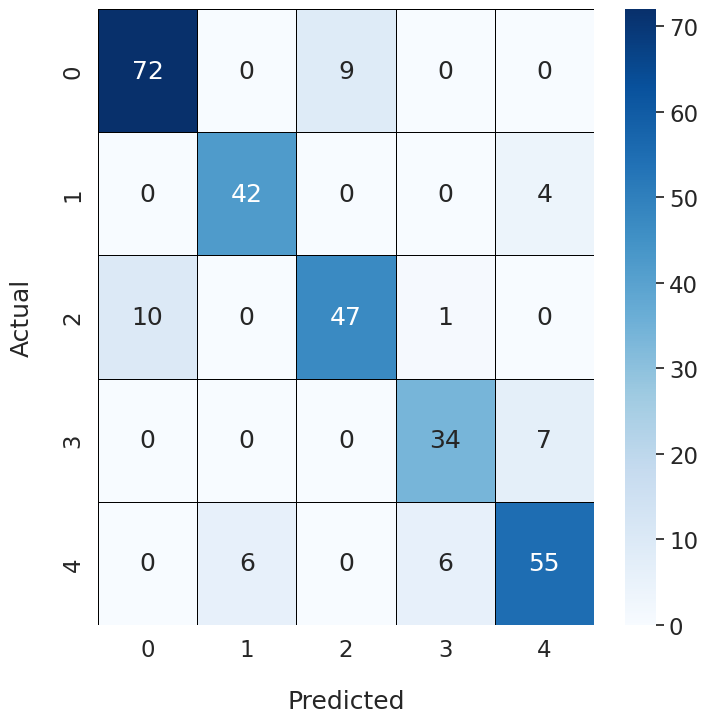

Epoch Training Time: 570.46 seconds
Test set: Average loss: 0.4701, Accuracy: 263/323 (81.42%), F1 Score: 0.8112

Fold 5
-------
Early stopping at epoch 111 due to no improvement in validation loss.


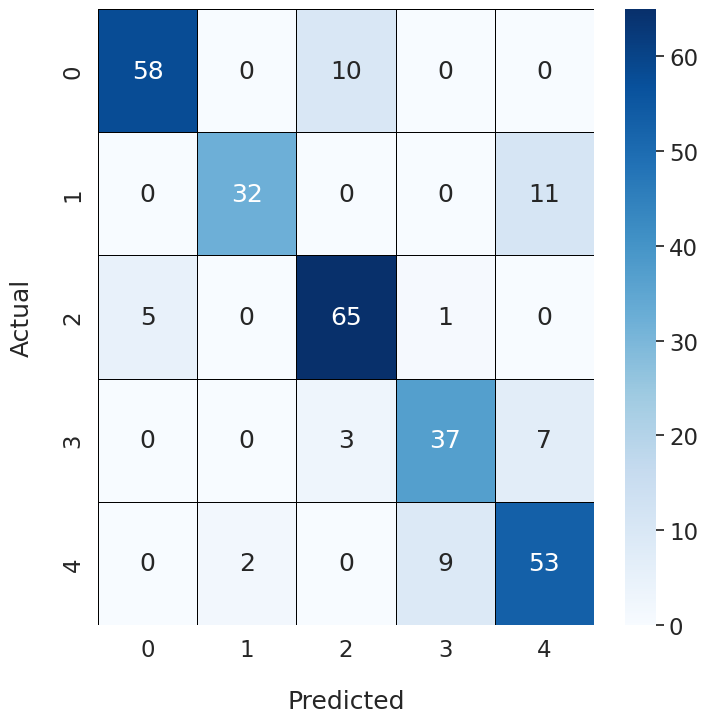

Epoch Training Time: 648.03 seconds
Test set: Average loss: 0.5069, Accuracy: 259/323 (80.19%), F1 Score: 0.7996

Fold 6
-------
Early stopping at epoch 107 due to no improvement in validation loss.


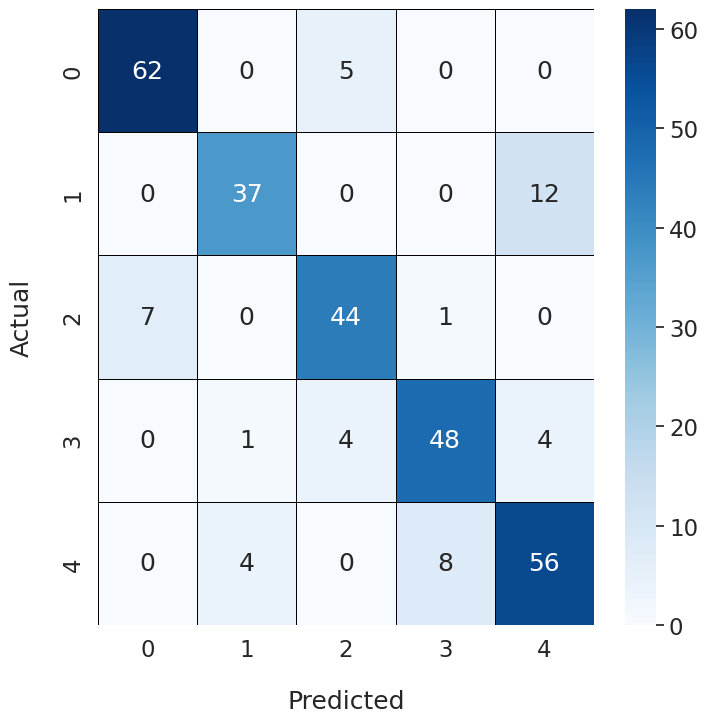

Epoch Training Time: 659.41 seconds
Test set: Average loss: 0.4583, Accuracy: 263/323 (81.42%), F1 Score: 0.8128

Fold 7
-------
Early stopping at epoch 114 due to no improvement in validation loss.


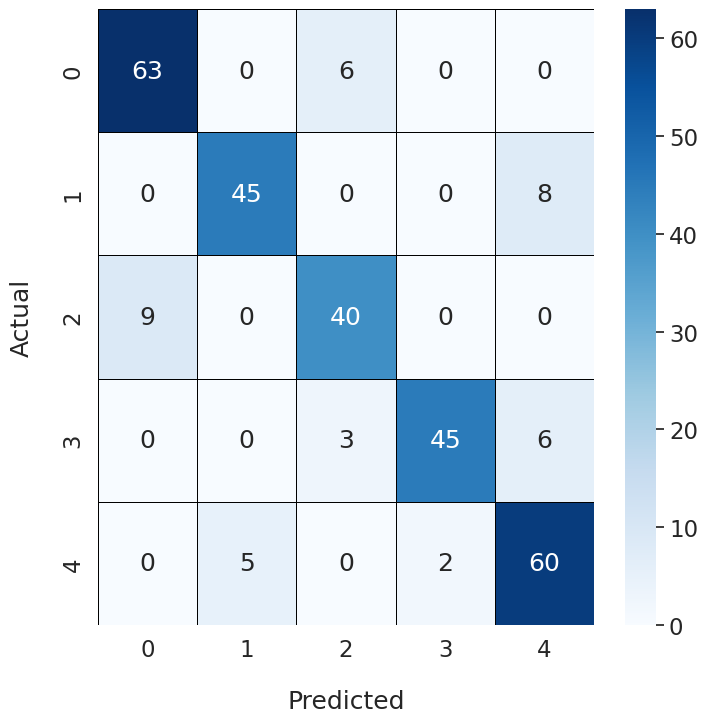

Epoch Training Time: 724.46 seconds
Test set: Average loss: 0.4305, Accuracy: 267/323 (82.66%), F1 Score: 0.8270

Fold 8
-------
Early stopping at epoch 106 due to no improvement in validation loss.


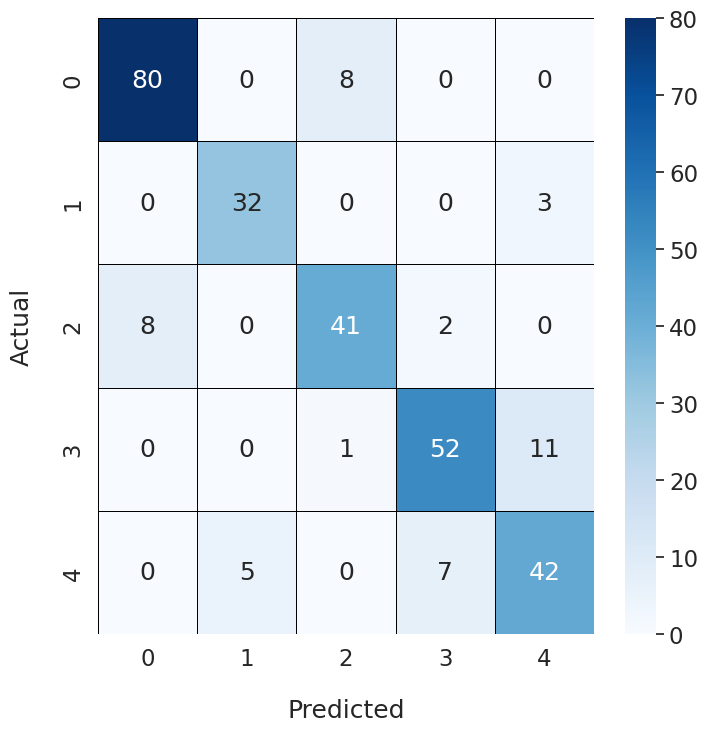

Epoch Training Time: 652.62 seconds
Test set: Average loss: 0.4476, Accuracy: 265/323 (82.04%), F1 Score: 0.8166

Fold 9
-------
Early stopping at epoch 113 due to no improvement in validation loss.


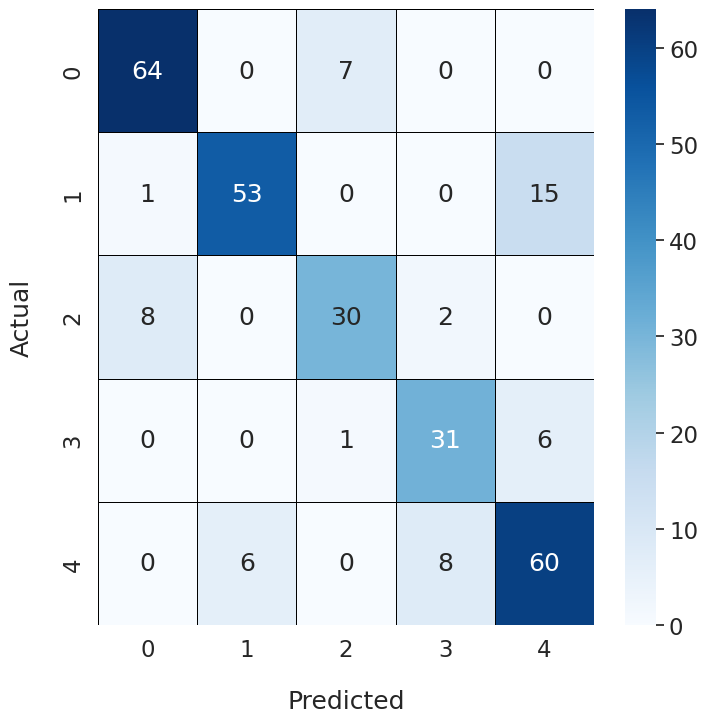

Epoch Training Time: 648.20 seconds
Test set: Average loss: 0.5400, Accuracy: 263/323 (81.42%), F1 Score: 0.8108

Fold 10
-------
Early stopping at epoch 126 due to no improvement in validation loss.


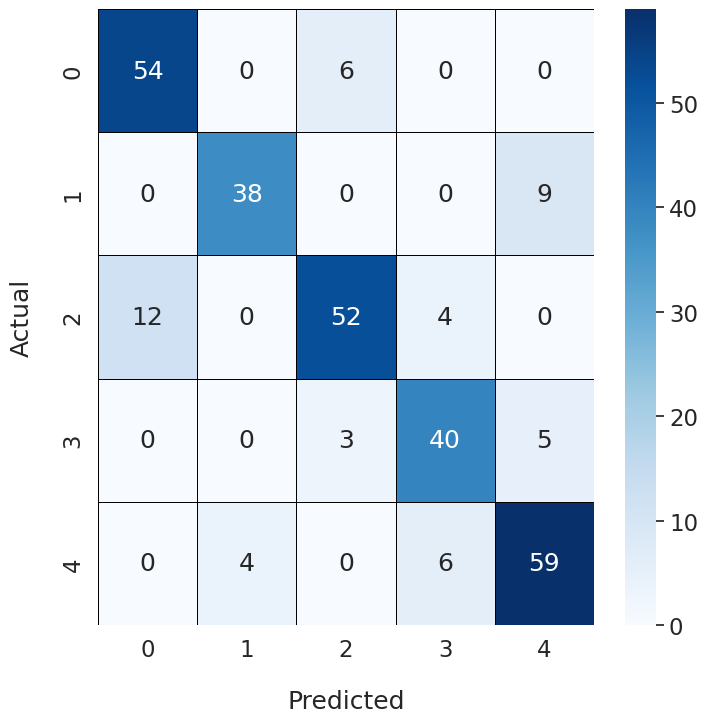

Epoch Training Time: 749.46 seconds
Test set: Average loss: 0.5639, Accuracy: 260/323 (80.50%), F1 Score: 0.8036



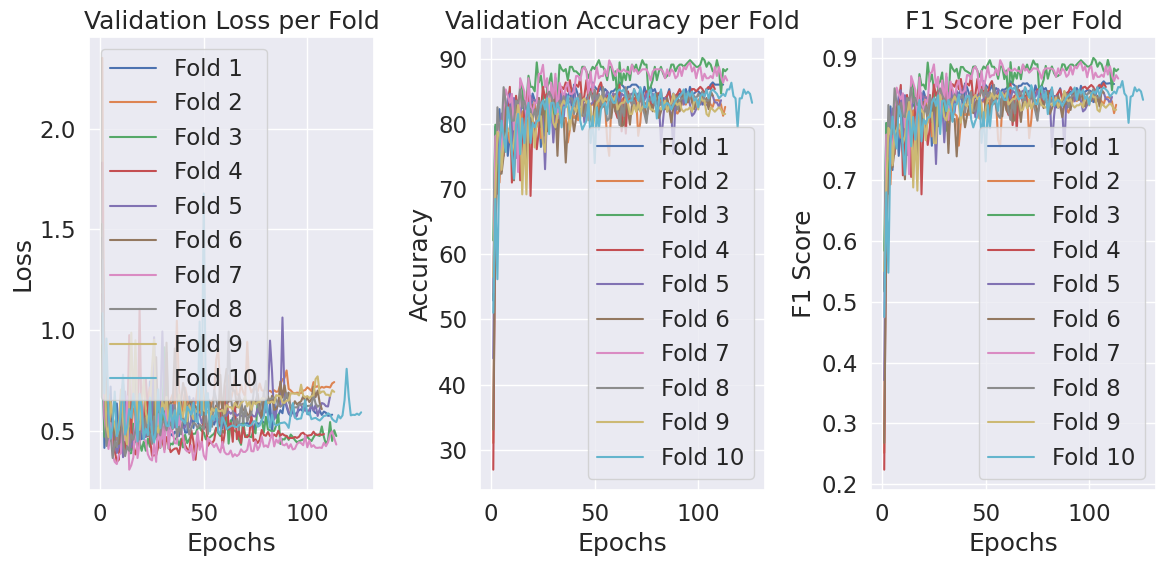

Maximum Fold Accuracy = 83.59133126934985
Maximum Fold F1 Score = 0.8346336367580188
Average Fold Accuracy = 81.70278637770897
Average Fold F1 Score = 0.8148880475343393


In [61]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Restnet/Mixed0.75_noSE"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/Mixed0.75_noSE/best_Mixed0.75_noSE.pth"
os.makedirs("./model_Restnet/Mixed0.75_noSE", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_Mixed0.75_noSE.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_Mixed075_noSE(ResidualBlock_Mixed075_noSE, [3, 4, 6, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 224, 224), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=lr0, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEfuzz_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet_Mixed075_noSE(ResidualBlock_Mixed075_noSE, [3, 4, 6, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [62]:
clear_all_memory()

Memory cleared and environment reset!


Mixed pool 1.0 + Restnet34--------------------------------------------------------------------------------------

In [63]:
from Mixedpool10 import mixedPool

alpha = 1.0


In [64]:
import import_ipynb
from starter_restnet import *
import sys

In [65]:
class ResidualBlock_Mixed10_noSE(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None, r=16):
            super(ResidualBlock_Mixed10_noSE, self).__init__()
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels))
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels
            
        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet_Mixed10_noSE(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet_Mixed10_noSE, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            #self.avgpool = nn.AvgPool2d(7, stride=1)
            self.mixed_pool = mixedPool()
            self.fc = nn.Linear(512, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            #x = self.avgpool(x)
            x = self.mixed_pool(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [66]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 3.68 GMac
Model Params: 21.3 M
Early stopping at epoch 105 due to no improvement in validation loss.


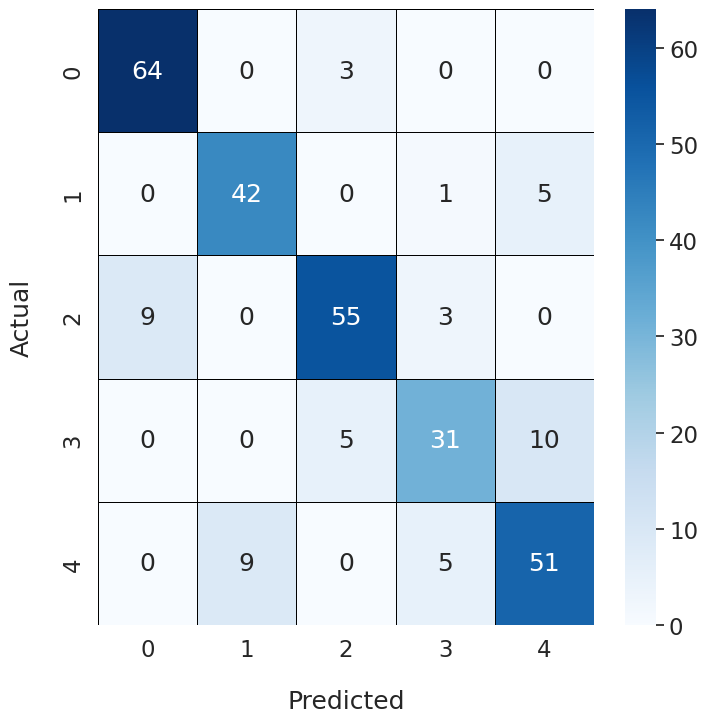

Epoch Training Time: 658.67 seconds
Test set: Average loss: 0.4460, Accuracy: 261/323 (80.80%), F1 Score: 0.8078

Fold 2
-------
Early stopping at epoch 109 due to no improvement in validation loss.


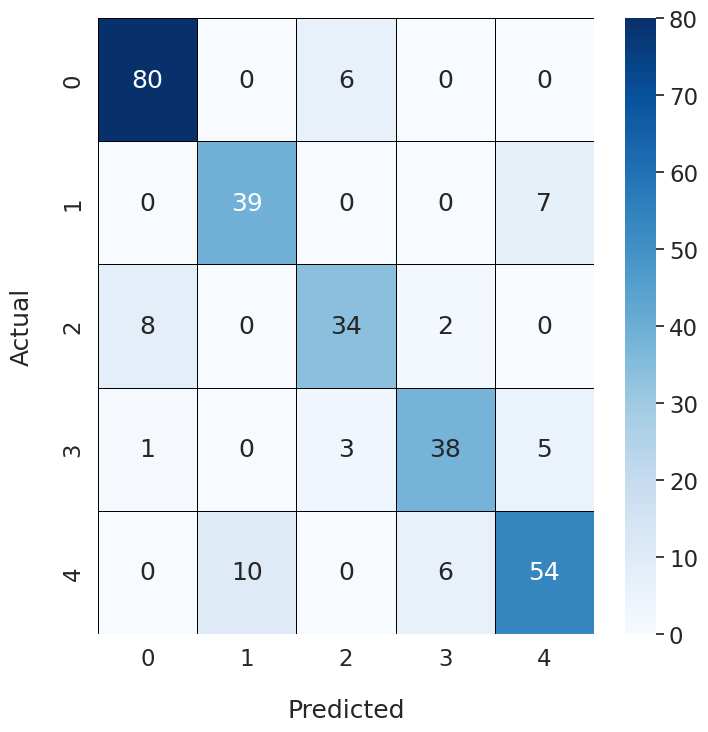

Epoch Training Time: 689.92 seconds
Test set: Average loss: 0.4242, Accuracy: 267/323 (82.66%), F1 Score: 0.8250

Fold 3
-------
Early stopping at epoch 120 due to no improvement in validation loss.


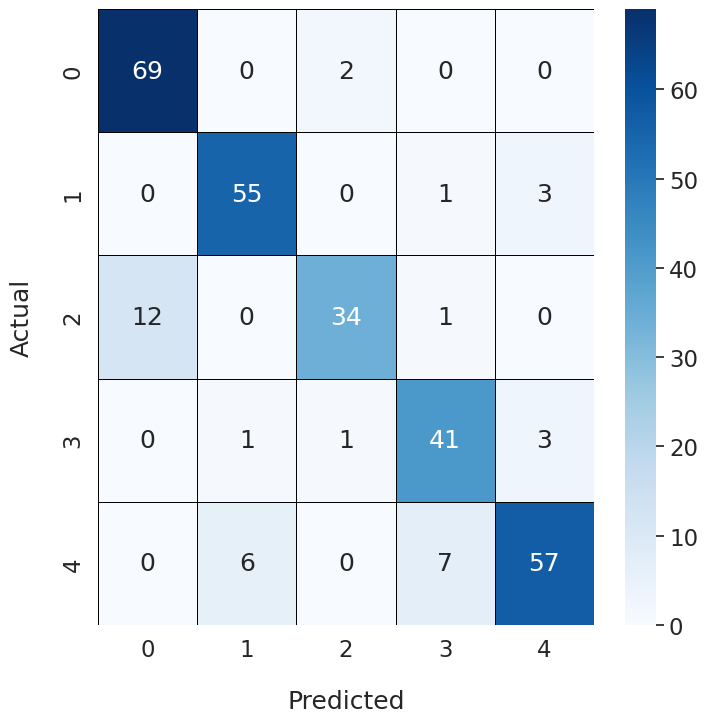

Epoch Training Time: 760.08 seconds
Test set: Average loss: 0.4580, Accuracy: 271/323 (83.90%), F1 Score: 0.8390

Fold 4
-------
Early stopping at epoch 111 due to no improvement in validation loss.


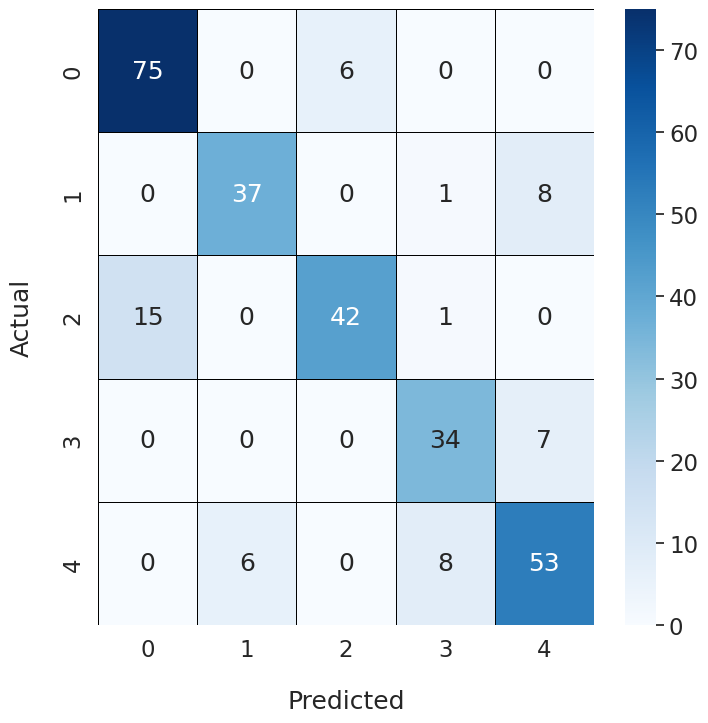

Epoch Training Time: 633.88 seconds
Test set: Average loss: 0.4246, Accuracy: 262/323 (81.11%), F1 Score: 0.8098

Fold 5
-------
Early stopping at epoch 113 due to no improvement in validation loss.


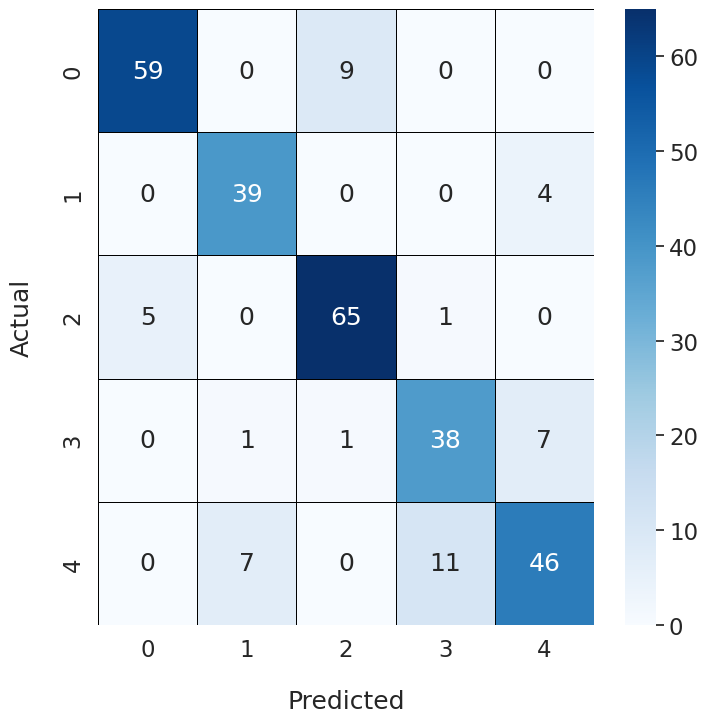

Epoch Training Time: 746.61 seconds
Test set: Average loss: 0.4462, Accuracy: 266/323 (82.35%), F1 Score: 0.8203

Fold 6
-------
Early stopping at epoch 107 due to no improvement in validation loss.


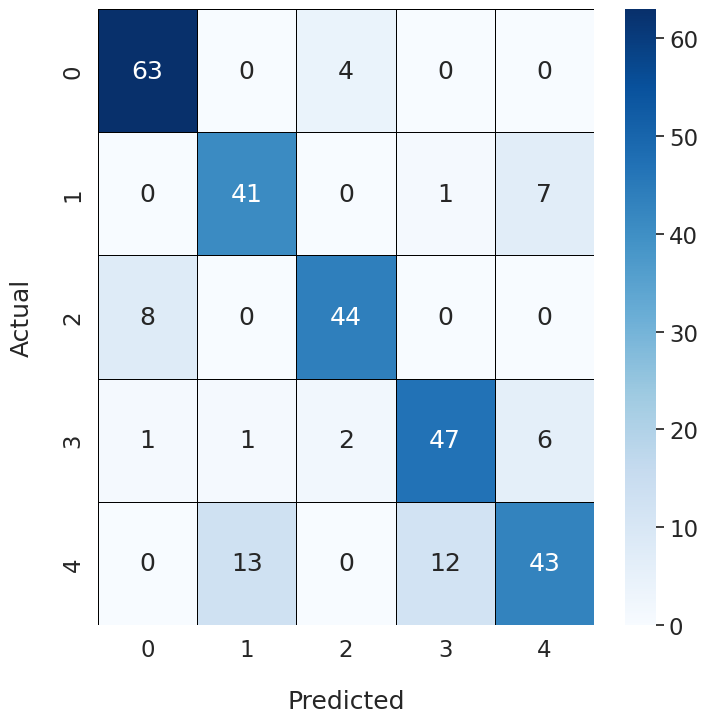

Epoch Training Time: 654.96 seconds
Test set: Average loss: 0.4140, Accuracy: 268/323 (82.97%), F1 Score: 0.8263

Fold 7
-------
Early stopping at epoch 108 due to no improvement in validation loss.


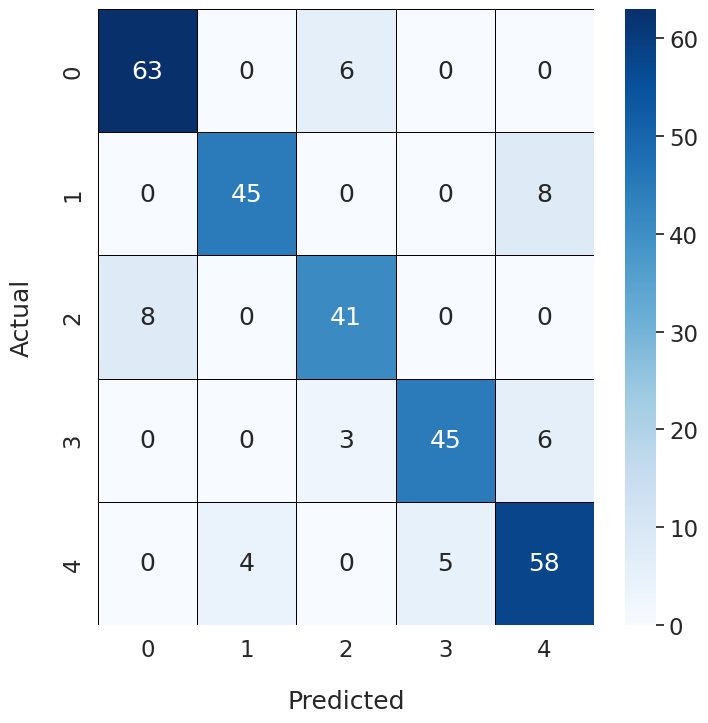

Epoch Training Time: 680.00 seconds
Test set: Average loss: 0.4348, Accuracy: 262/323 (81.11%), F1 Score: 0.8098

Fold 8
-------
Early stopping at epoch 118 due to no improvement in validation loss.


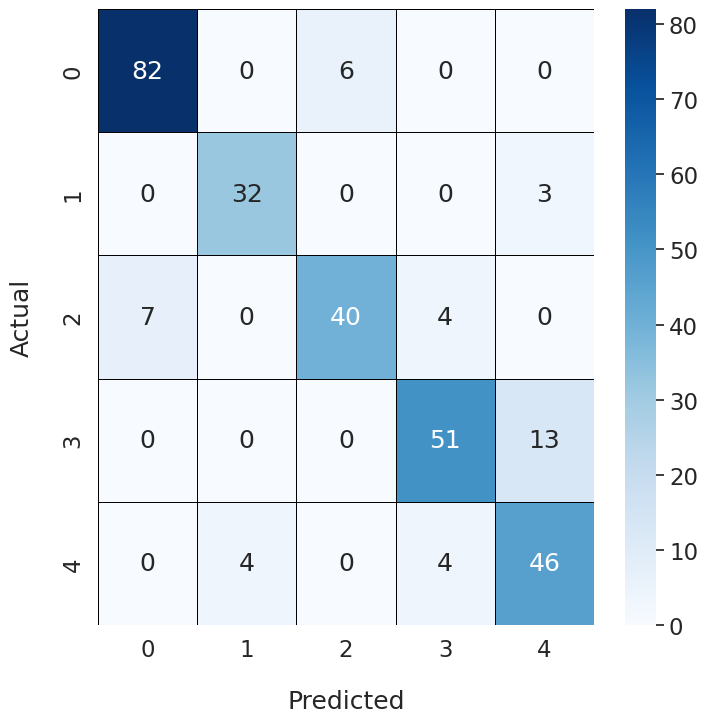

Epoch Training Time: 711.87 seconds
Test set: Average loss: 0.4867, Accuracy: 260/323 (80.50%), F1 Score: 0.8038

Fold 9
-------
Early stopping at epoch 113 due to no improvement in validation loss.


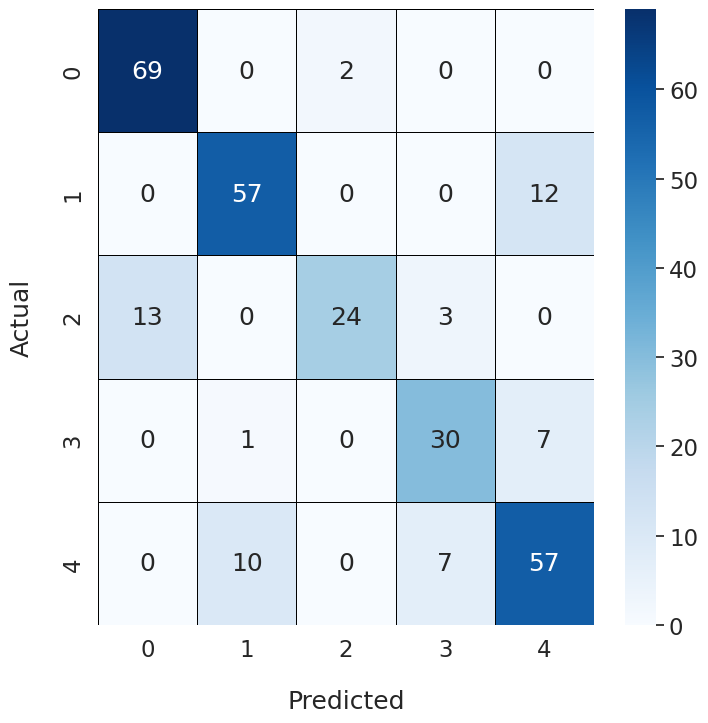

Epoch Training Time: 646.51 seconds
Test set: Average loss: 0.4685, Accuracy: 271/323 (83.90%), F1 Score: 0.8370

Fold 10
-------
Early stopping at epoch 110 due to no improvement in validation loss.


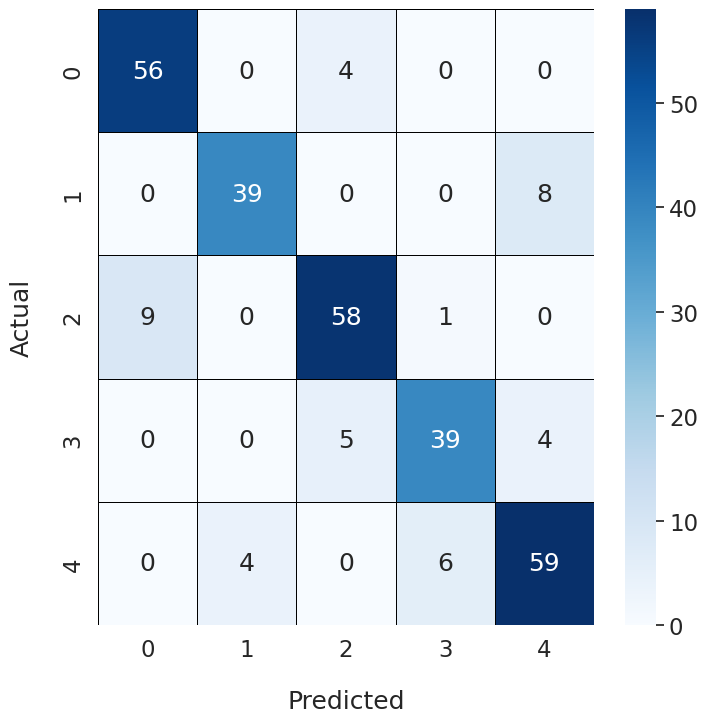

Epoch Training Time: 708.69 seconds
Test set: Average loss: 0.4272, Accuracy: 269/323 (83.28%), F1 Score: 0.8313



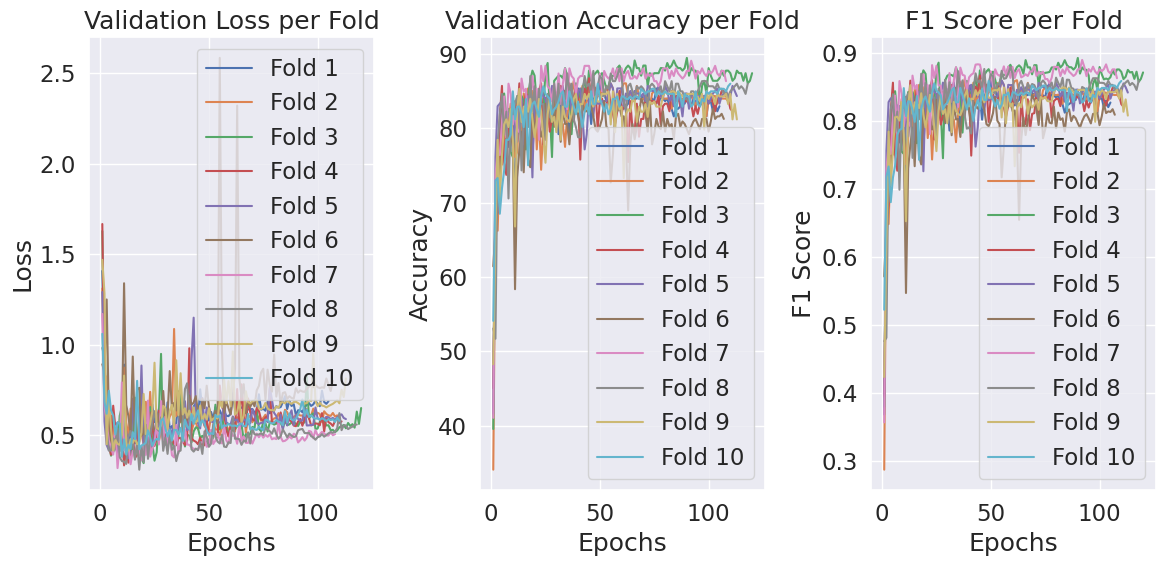

Maximum Fold Accuracy = 83.90092879256966
Maximum Fold F1 Score = 0.838993524147713
Average Fold Accuracy = 82.26006191950465
Average Fold F1 Score = 0.8210053978957836


In [67]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Restnet/Mixed1.0_noSE"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/Mixed1.0_noSE/best_Mixed1.0_noSE.pth"
os.makedirs("./model_Restnet/Mixed1.0_noSE", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_Mixed1.0_noSE.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet_Mixed10_noSE(ResidualBlock_Mixed10_noSE, [3, 4, 6, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 224, 224), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=lr0, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEfuzz_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet_Mixed10_noSE(ResidualBlock_Mixed10_noSE, [3, 4, 6, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [68]:
clear_all_memory()

Memory cleared and environment reset!


Max pool + Restnet34--------------------------------------------------------------------------------------

In [69]:
import import_ipynb
from starter_restnet import *
import sys

In [70]:
class ResidualBlock(nn.Module):
        def __init__(self, in_channels, out_channels, stride = 1, downsample = None):
            super(ResidualBlock, self).__init__()
            self.conv1 = nn.Sequential(
                            nn.Conv2d(in_channels, out_channels, kernel_size = 3, stride = stride, padding = 1),
                            nn.BatchNorm2d(out_channels),
                            nn.ReLU())
            self.conv2 = nn.Sequential(
                            nn.Conv2d(out_channels, out_channels, kernel_size = 3, stride = 1, padding = 1),
                            nn.BatchNorm2d(out_channels))
            self.downsample = downsample
            self.relu = nn.ReLU()
            self.out_channels = out_channels

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.conv2(out)
            
            if self.downsample:
                residual = self.downsample(x)
            out += residual
            out = self.relu(out)
            return out

class ResNet(nn.Module):
        def __init__(self, block, layers, num_classes = 5):
            super(ResNet, self).__init__()
            self.inplanes = 64
            self.conv1 = nn.Sequential(
                            nn.Conv2d(3, 64, kernel_size = 7, stride = 2, padding = 3),
                            nn.BatchNorm2d(64),
                            nn.ReLU())
            self.maxpool = nn.MaxPool2d(kernel_size = 3, stride = 2, padding = 1)
            self.layer0 = self._make_layer(block, 64, layers[0], stride = 1)
            self.layer1 = self._make_layer(block, 128, layers[1], stride = 2)
            self.layer2 = self._make_layer(block, 256, layers[2], stride = 2)
            self.layer3 = self._make_layer(block, 512, layers[3], stride = 2)
            self.maxpool2 = nn.MaxPool2d(7, stride=1)
            self.fc = nn.Linear(512, num_classes)

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes:

                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes, kernel_size=1, stride=stride),
                    nn.BatchNorm2d(planes),
                )
            layers = []
            layers.append(block(self.inplanes, planes, stride, downsample))
            self.inplanes = planes
            for i in range(1, blocks):
                layers.append(block(self.inplanes, planes))

            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)
            x = self.maxpool(x)
            x = self.layer0(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)

            x = self.maxpool2(x)
            x = x.view(x.size(0), -1)
            x = self.fc(x)

            return x

In [71]:
all_folds_val_loss = []
all_folds_val_acc = []
all_folds_f1 = []
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 3.68 GMac
Model Params: 21.3 M
Early stopping at epoch 110 due to no improvement in validation loss.


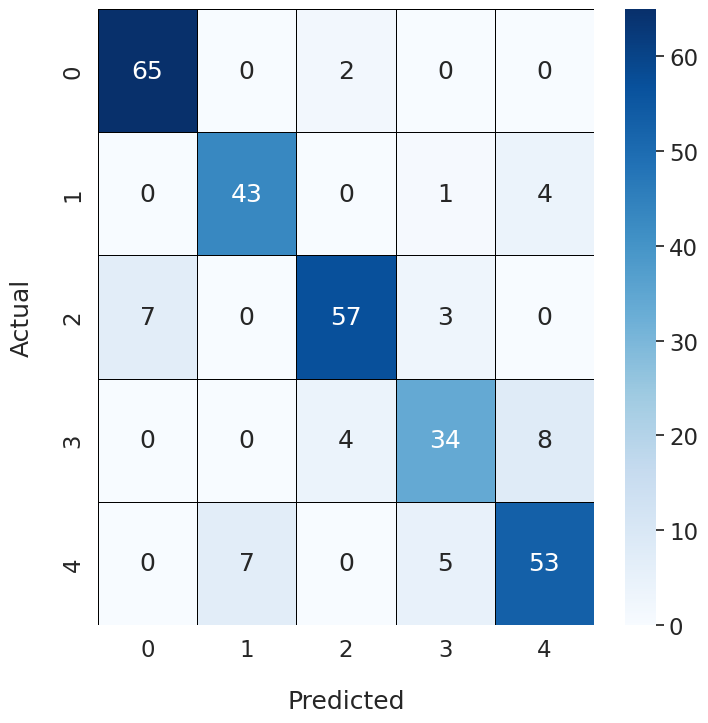

Epoch Training Time: 717.61 seconds
Test set: Average loss: 0.4300, Accuracy: 268/323 (82.97%), F1 Score: 0.8287

Fold 2
-------
Early stopping at epoch 112 due to no improvement in validation loss.


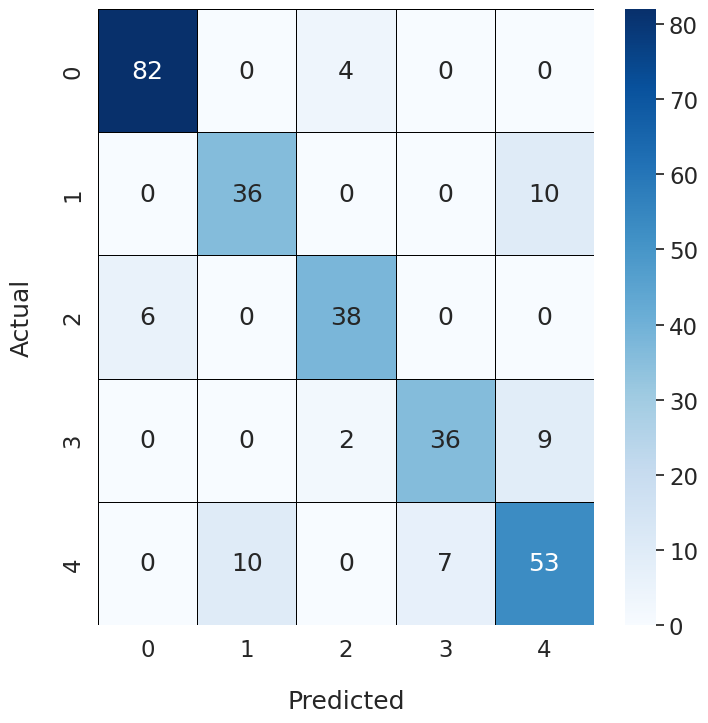

Epoch Training Time: 765.91 seconds
Test set: Average loss: 0.5075, Accuracy: 266/323 (82.35%), F1 Score: 0.8203

Fold 3
-------
Early stopping at epoch 116 due to no improvement in validation loss.


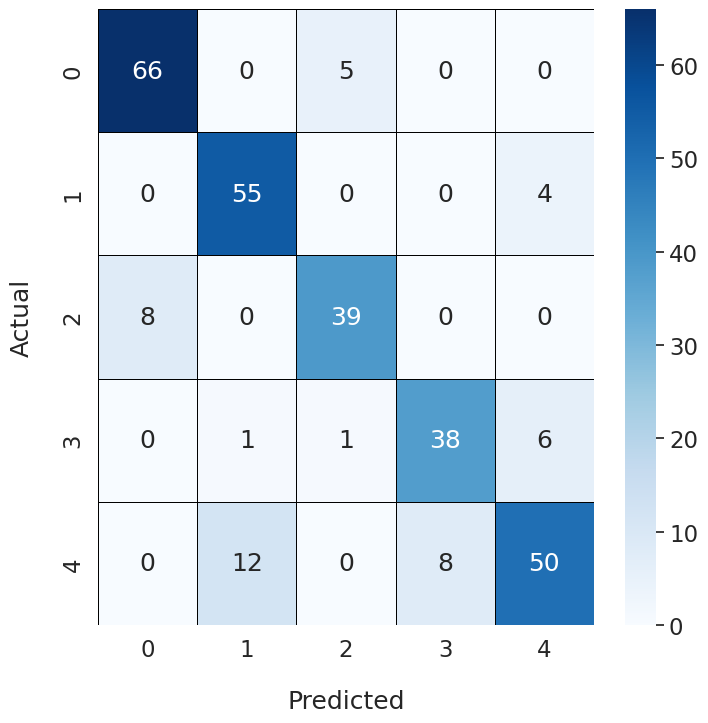

Epoch Training Time: 803.69 seconds
Test set: Average loss: 0.4863, Accuracy: 262/323 (81.11%), F1 Score: 0.8096

Fold 4
-------
Early stopping at epoch 118 due to no improvement in validation loss.


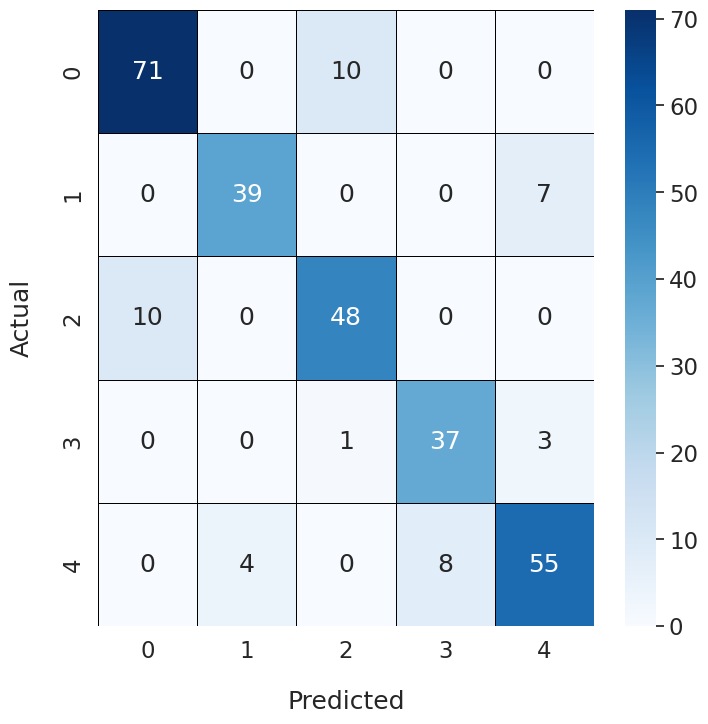

Epoch Training Time: 888.13 seconds
Test set: Average loss: 0.4560, Accuracy: 264/323 (81.73%), F1 Score: 0.8159

Fold 5
-------
Early stopping at epoch 114 due to no improvement in validation loss.


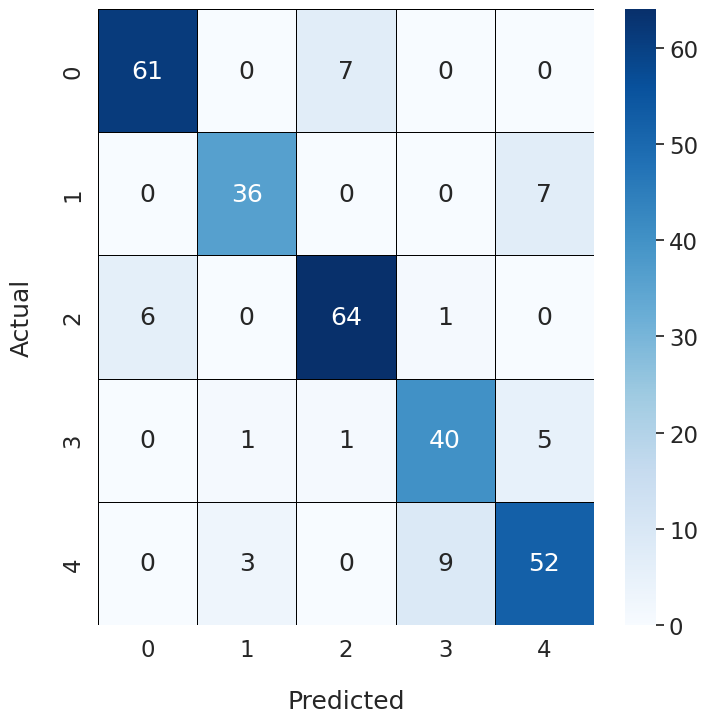

Epoch Training Time: 839.56 seconds
Test set: Average loss: 0.4299, Accuracy: 271/323 (83.90%), F1 Score: 0.8376

Fold 6
-------
Early stopping at epoch 110 due to no improvement in validation loss.


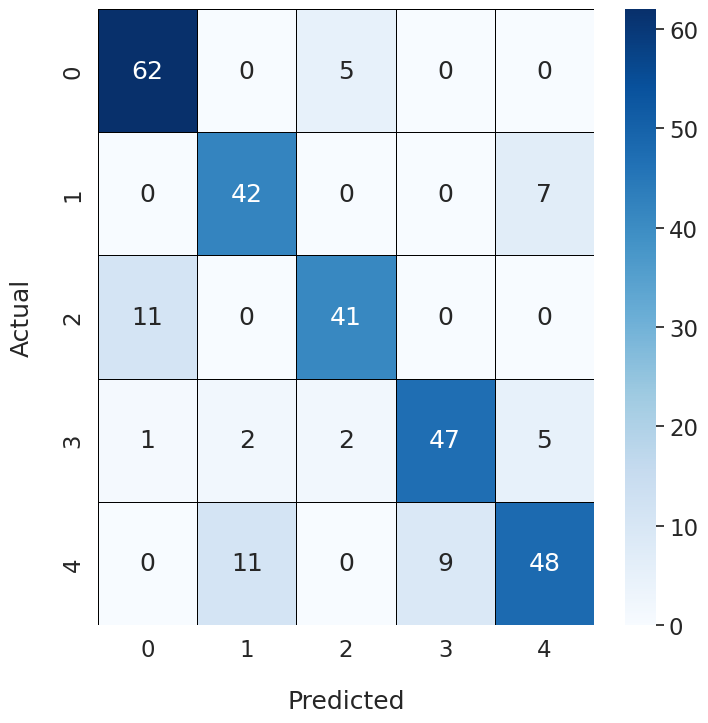

Epoch Training Time: 880.50 seconds
Test set: Average loss: 0.5020, Accuracy: 255/323 (78.95%), F1 Score: 0.7874

Fold 7
-------
Early stopping at epoch 107 due to no improvement in validation loss.


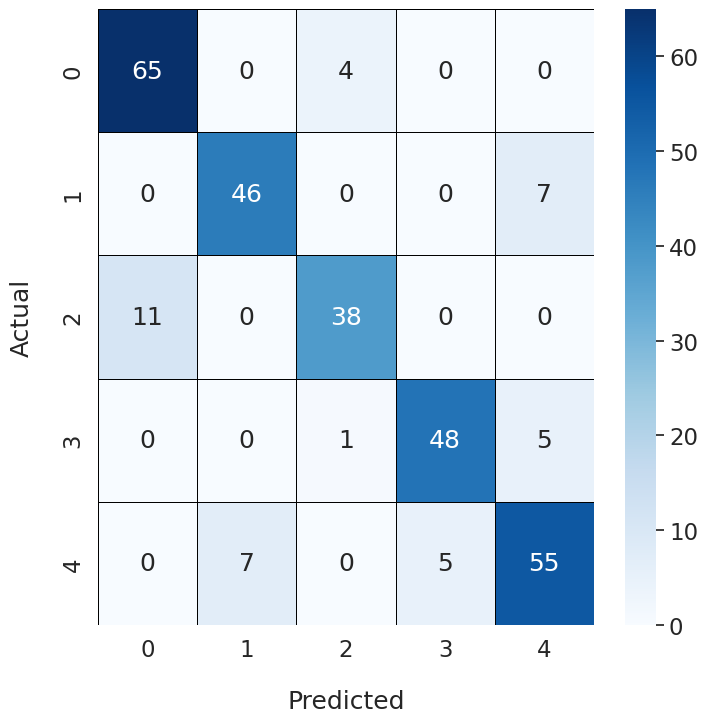

Epoch Training Time: 873.97 seconds
Test set: Average loss: 0.4418, Accuracy: 258/323 (79.88%), F1 Score: 0.7985

Fold 8
-------
Early stopping at epoch 109 due to no improvement in validation loss.


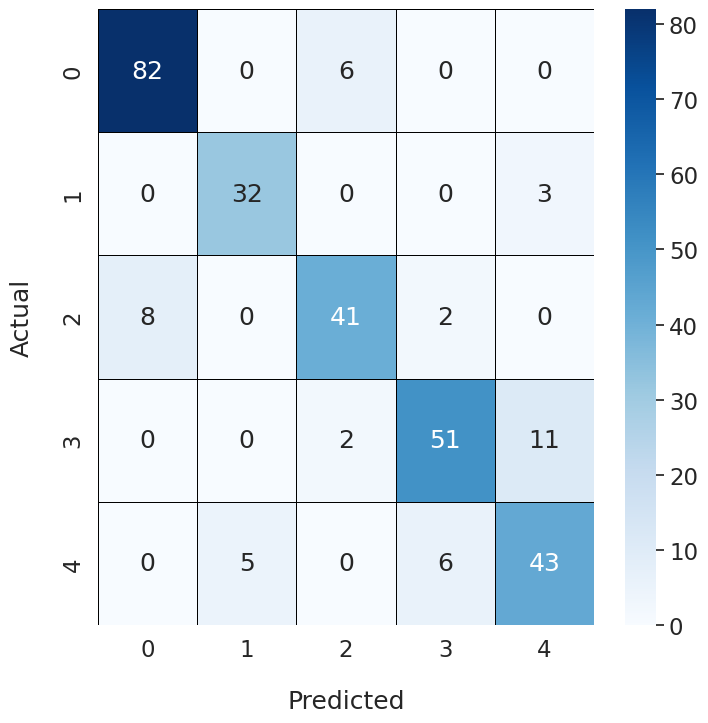

Epoch Training Time: 831.26 seconds
Test set: Average loss: 0.4322, Accuracy: 258/323 (79.88%), F1 Score: 0.7984

Fold 9
-------
Early stopping at epoch 116 due to no improvement in validation loss.


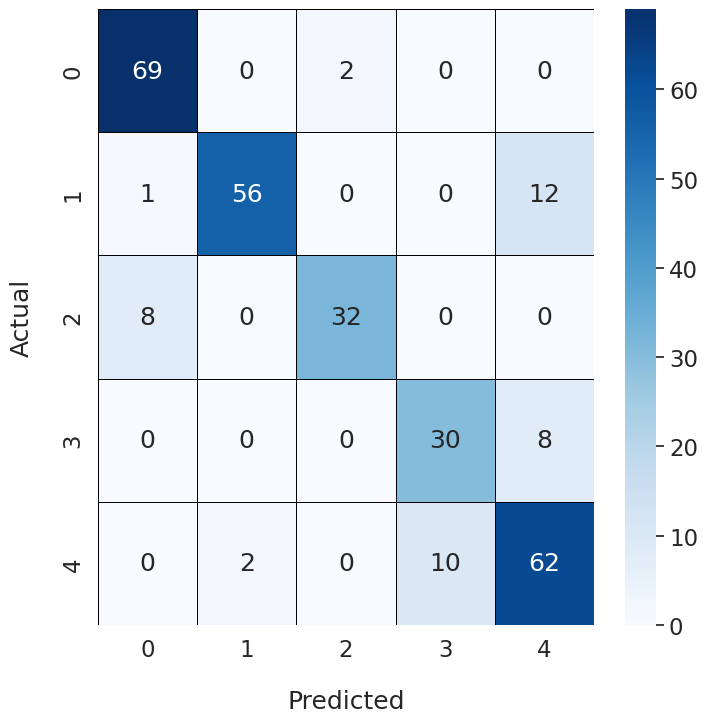

Epoch Training Time: 840.72 seconds
Test set: Average loss: 0.4128, Accuracy: 272/323 (84.21%), F1 Score: 0.8404

Fold 10
-------
Early stopping at epoch 118 due to no improvement in validation loss.


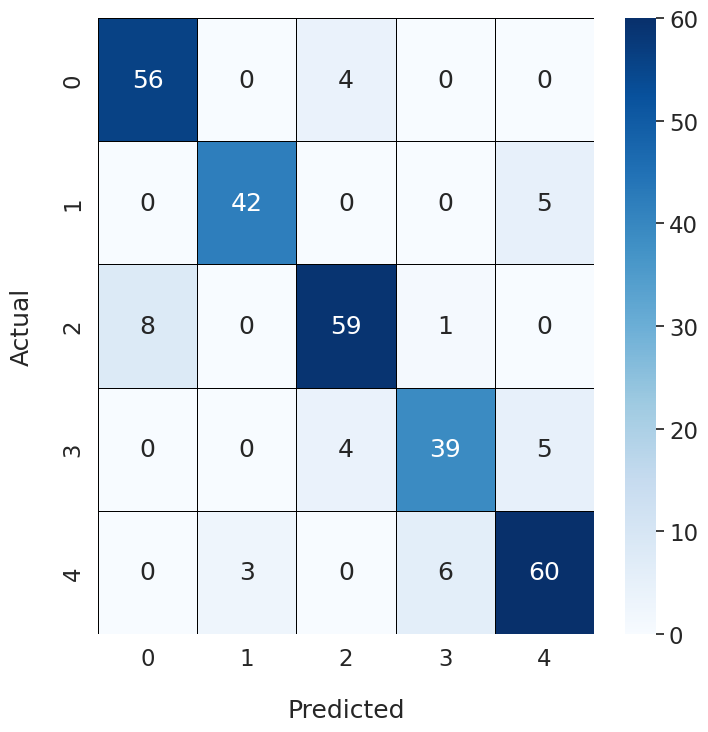

Epoch Training Time: 876.29 seconds
Test set: Average loss: 0.4309, Accuracy: 272/323 (84.21%), F1 Score: 0.8415



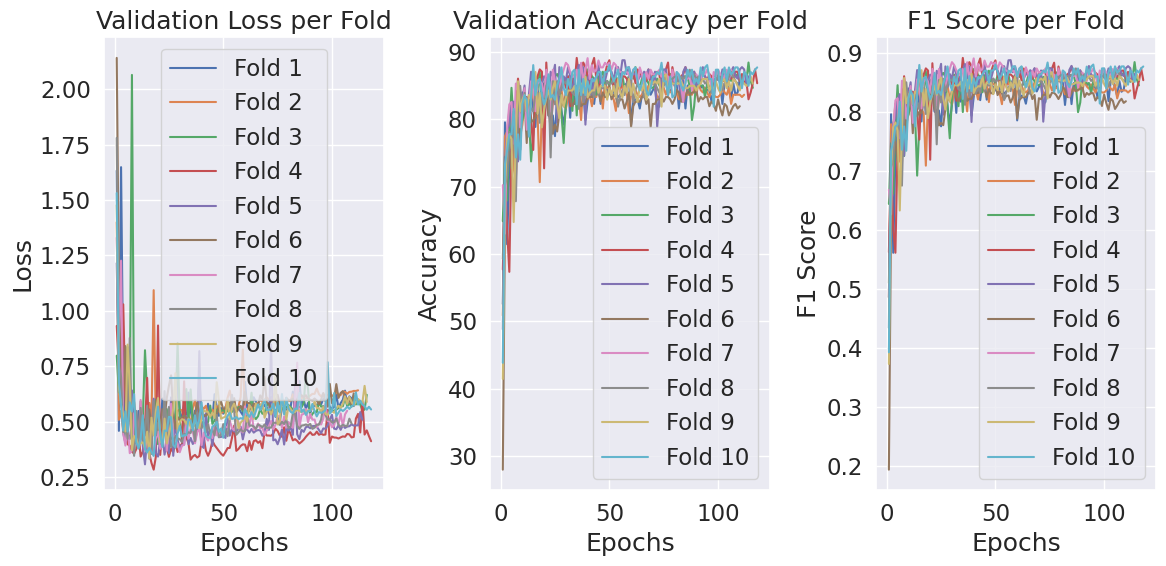

Maximum Fold Accuracy = 84.21052631578948
Maximum Fold F1 Score = 0.8415305624233133
Average Fold Accuracy = 81.91950464396284
Average Fold F1 Score = 0.8178339962746823


In [72]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Restnet/maxnoSE"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Restnet/maxnoSE/best_maxnoSE.pth"
os.makedirs("./model_Restnet/maxnoSE", exist_ok=True)

log_file_path = os.path.join(save_dir, "training_log_maxnoSE.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []

   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        drop_last=drop_last,
        generator=g
    )

    # Initialize the model and optimizer
    model = ResNet(ResidualBlock, [3, 4, 6, 3]).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 224, 224), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=lr0, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")
    
    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"maxnoSE_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])

    all_folds_val_loss.append(epoch_val_loss.copy())
    all_folds_val_acc.append(epoch_val_acc.copy())
    all_folds_f1.append(epochs_f1_score.copy())

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = ResNet(ResidualBlock, [3, 4, 6, 3]).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout_

In [73]:
clear_all_memory()

Memory cleared and environment reset!
